# xwOBA-wOBA and xBA-BA Residuals (2025-2026)

Pulled from `2025_2026_pitches.parquet` ([pull_2025_2026.py](pull_2025_2026.py)).

**How the value columns work** (confirmed by inspection):
- `woba` / `xwoba` / `xba` are stamped on the *terminal pitch* of each plate appearance (`is_terminal_pitch == '1'`), one row per PA.
- For walks, HBP, and strikeouts, `xwoba`/`xba` are deterministic (equal to the actual weight, or 0 for xBA on a strikeout) — there's no "quality of contact" to model.
- For batted-ball outcomes (single/double/triple/HR/out/error/fielder's choice/sacrifice), `xwoba`/`xba` come from a contact-quality model and differ from the actual outcome — that's where residual signal (over/underperformance) actually lives.

**Definitions used below:**
- `is_AB` = PA is not a walk, HBP, or sacrifice (matches standard AB rules; strikeouts count as AB).
- `is_hit` = play_result in single/double/triple/home_run.
- Residual = actual − expected. Positive = outperforming the model (or "lucky"/skilled contact quality not captured), negative = underperforming.
- A tiny number of `stolen_base`/`caught_stealing` terminal-pitch rows (21 total) are data artifacts, not real PA outcomes, and are dropped.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

OUT_DIR = Path("output")
OUT_DIR.mkdir(exist_ok=True)

df = pd.read_parquet("2025_2026_pitches.parquet")
print(f"{len(df):,} pitches loaded")

# one row per plate appearance
term = df[df["is_terminal_pitch"] == "1"].copy()
term = term[~term["play_result"].isin(["stolen_base", "caught_stealing"])]
print(f"{len(term):,} plate appearances (terminal pitches)")


479,801 pitches loaded


123,435 plate appearances (terminal pitches)


In [2]:
# --- category flags ---
term["is_hit"] = term["play_result"].isin(["single", "double", "triple", "home_run"])
term["is_AB"] = ~(
    (term["k_or_bb"] == "walk")
    | (term["pitch_call"] == "hit_by_pitch")
    | (term["play_result"] == "sacrifice")
)

# a readable outcome label for diagnostics
term["pa_outcome"] = np.where(
    term["pitch_call"] == "hit_by_pitch", "hit_by_pitch",
    np.where(term["k_or_bb"] != "undefined", term["k_or_bb"], term["play_result"])
)
print(term["pa_outcome"].value_counts())


pa_outcome
out                48951
strikeout          23686
single             19959
walk               13472
double              5226
home_run            2911
hit_by_pitch        2846
fielders_choice     2275
sacrifice           1886
error               1762
triple               453
undefined              8
Name: count, dtype: int64


In [3]:
# --- complete-case subsets (actual & expected both present, so residuals compare apples to apples) ---
woba_pa = term[term["woba"].notna() & term["xwoba"].notna()].copy()
ba_pa = term[term["is_AB"] & term["xba"].notna()].copy()

print(f"wOBA-eligible PAs: {len(woba_pa):,}")
print(f"BA-eligible ABs:   {len(ba_pa):,}")


wOBA-eligible PAs: 120,301
BA-eligible ABs:   102,900


## League-level calibration

Does the model balance out league-wide, or is it systematically biased high/low?

In [4]:
league = pd.DataFrame({
    "metric": ["wOBA", "BA"],
    "actual": [woba_pa["woba"].mean(), ba_pa["is_hit"].mean()],
    "expected": [woba_pa["xwoba"].mean(), ba_pa["xba"].mean()],
})
league["residual"] = league["actual"] - league["expected"]
league


,metric,actual,expected,residual
0,wOBA,0.366748,0.365264,0.001483
1,BA,0.271506,0.267838,0.003669


## Per-batter aggregation

In [5]:
MIN_PA = 50
MIN_AB = 50

woba_agg = (
    woba_pa.groupby(["batter_id", "batter"])
    .agg(PA=("woba", "size"), actual_woba=("woba", "mean"), exp_woba=("xwoba", "mean"))
    .reset_index()
)
woba_agg["woba_resid"] = woba_agg["actual_woba"] - woba_agg["exp_woba"]

ba_agg = (
    ba_pa.groupby(["batter_id", "batter"])
    .agg(AB=("xba", "size"), hits=("is_hit", "sum"), exp_ba=("xba", "mean"))
    .reset_index()
)
ba_agg["actual_ba"] = ba_agg["hits"] / ba_agg["AB"]
ba_agg["ba_resid"] = ba_agg["actual_ba"] - ba_agg["exp_ba"]

woba_qual = woba_agg[woba_agg["PA"] >= MIN_PA].sort_values("woba_resid", ascending=False)
ba_qual = ba_agg[ba_agg["AB"] >= MIN_AB].sort_values("ba_resid", ascending=False)

print(f"{len(woba_qual)} batters with >= {MIN_PA} PA")
print(f"{len(ba_qual)} batters with >= {MIN_AB} AB")


423 batters with >= 50 PA
407 batters with >= 50 AB


### wOBA overperformers / underperformers (min 50 PA)

In [6]:
top15 = woba_qual.head(15)[["batter", "PA", "actual_woba", "exp_woba", "woba_resid"]]
bottom15 = woba_qual.tail(15)[["batter", "PA", "actual_woba", "exp_woba", "woba_resid"]].sort_values("woba_resid")
print("--- Top 15 outperforming wOBA vs xwOBA ---")
print(top15.to_string(index=False))
print()
print("--- Bottom 15 underperforming wOBA vs xwOBA ---")
print(bottom15.to_string(index=False))


--- Top 15 outperforming wOBA vs xwOBA ---
             batter  PA  actual_woba  exp_woba  woba_resid
   Kolokie, Aldalay  63     0.386016  0.295016    0.091000
   Blomquist, Brett 257     0.463179  0.378525    0.084654
     Whitley, Aaron 168     0.415185  0.336423    0.078762
        Stinson, RJ 225     0.440138  0.373364    0.066773
    Bradshaw, Davis  97     0.420897  0.354866    0.066031
      Young, Chavez 356     0.476612  0.412528    0.064084
        Webb, Isaac  51     0.376608  0.313255    0.063353
       Smith, Myles 305     0.417066  0.359852    0.057213
    Tucker, Jackson 268     0.361608  0.310705    0.050903
   Ponder, Jonathan 315     0.409689  0.359276    0.050413
    Hall, Christian  62     0.349984  0.299968    0.050016
Schofield-Sam, T.J.  55     0.344218  0.294618    0.049600
  Stefanovic, Ranko 167     0.349892  0.300359    0.049533
  Stefanovic, Ranko 115     0.390652  0.341122    0.049530
  Taveras, Crixtian  56     0.299339  0.250107    0.049232

--- Bottom 1

### BA overperformers / underperformers (min 50 AB)

In [7]:
top15_ba = ba_qual.head(15)[["batter", "AB", "hits", "actual_ba", "exp_ba", "ba_resid"]]
bottom15_ba = ba_qual.tail(15)[["batter", "AB", "hits", "actual_ba", "exp_ba", "ba_resid"]].sort_values("ba_resid")
print("--- Top 15 outperforming BA vs xBA ---")
print(top15_ba.to_string(index=False))
print()
print("--- Bottom 15 underperforming BA vs xBA ---")
print(bottom15_ba.to_string(index=False))


--- Top 15 outperforming BA vs xBA ---
           batter  AB  hits  actual_ba   exp_ba  ba_resid
  Bradshaw, Davis  84    32   0.380952 0.294655  0.086298
   Whitley, Aaron 141    45   0.319149 0.237362  0.081787
 Kolokie, Aldalay  56    16   0.285714 0.217518  0.068196
 Blomquist, Brett 214    70   0.327103 0.259276  0.067827
      Stinson, RJ 186    63   0.338710 0.281070  0.057640
    Jones, Breyln  57    18   0.315789 0.258404  0.057386
    Young, Chavez 289   103   0.356401 0.299709  0.056692
  Hall, Christian  53    14   0.264151 0.207566  0.056585
  Sullivan, Billy 111    35   0.315315 0.259126  0.056189
   Stevens, Felix 191    77   0.403141 0.347953  0.055188
    Castro, Ruben 346   124   0.358382 0.303783  0.054598
      Vogel, Ryan 237    62   0.261603 0.208359  0.053245
Stefanovic, Ranko 107    35   0.327103 0.276822  0.050280
        Sosa, Gus 206    72   0.349515 0.299995  0.049519
 Adams, Christian 308   106   0.344156 0.295201  0.048955

--- Bottom 15 underperforming BA

## Plots

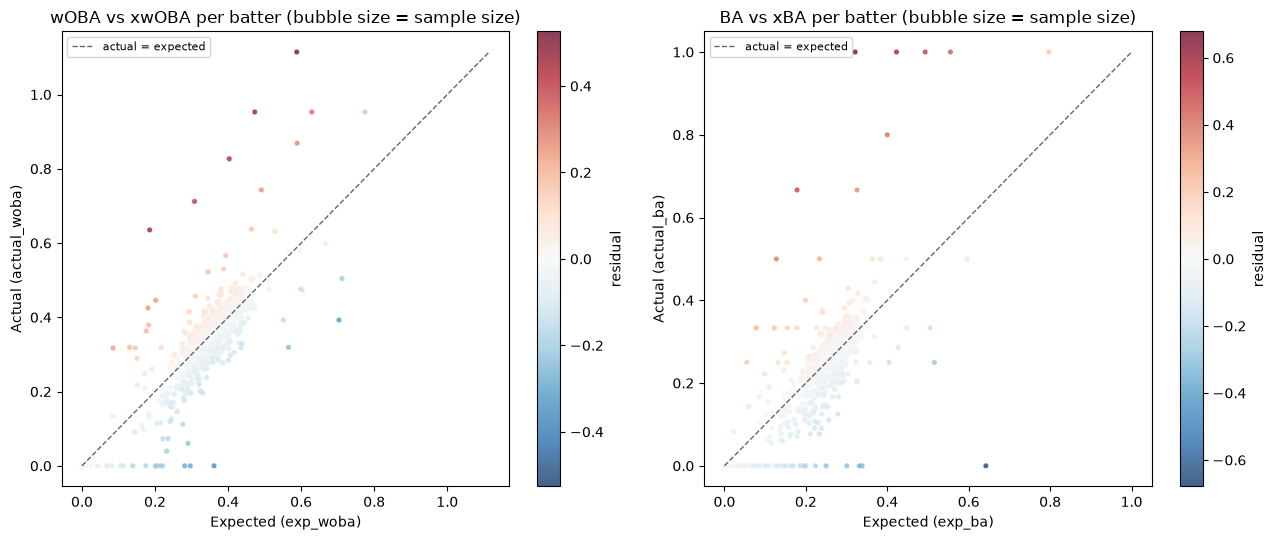

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

for ax, agg, xcol, ycol, resid, title in [
    (axes[0], woba_agg, "exp_woba", "actual_woba", "woba_resid", "wOBA vs xwOBA"),
    (axes[1], ba_agg, "exp_ba", "actual_ba", "ba_resid", "BA vs xBA"),
]:
    sizes = agg["PA"] if "PA" in agg else agg["AB"]
    sc = ax.scatter(agg[xcol], agg[ycol], c=agg[resid], cmap="RdBu_r",
                     s=15 + 60 * (sizes / sizes.max()), alpha=0.75,
                     vmin=-agg[resid].abs().max(), vmax=agg[resid].abs().max(),
                     edgecolors="white", linewidths=0.3)
    lims = [min(agg[xcol].min(), agg[ycol].min()), max(agg[xcol].max(), agg[ycol].max())]
    ax.plot(lims, lims, "k--", lw=1, alpha=0.6, label="actual = expected")
    ax.set_xlabel(f"Expected ({xcol})")
    ax.set_ylabel(f"Actual ({ycol})")
    ax.set_title(f"{title} per batter (bubble size = sample size)")
    ax.legend(loc="upper left", fontsize=8)
    plt.colorbar(sc, ax=ax, label="residual")

plt.tight_layout()
plt.savefig(OUT_DIR / "xwoba_xba_actual_vs_expected.png", dpi=150)
plt.show()


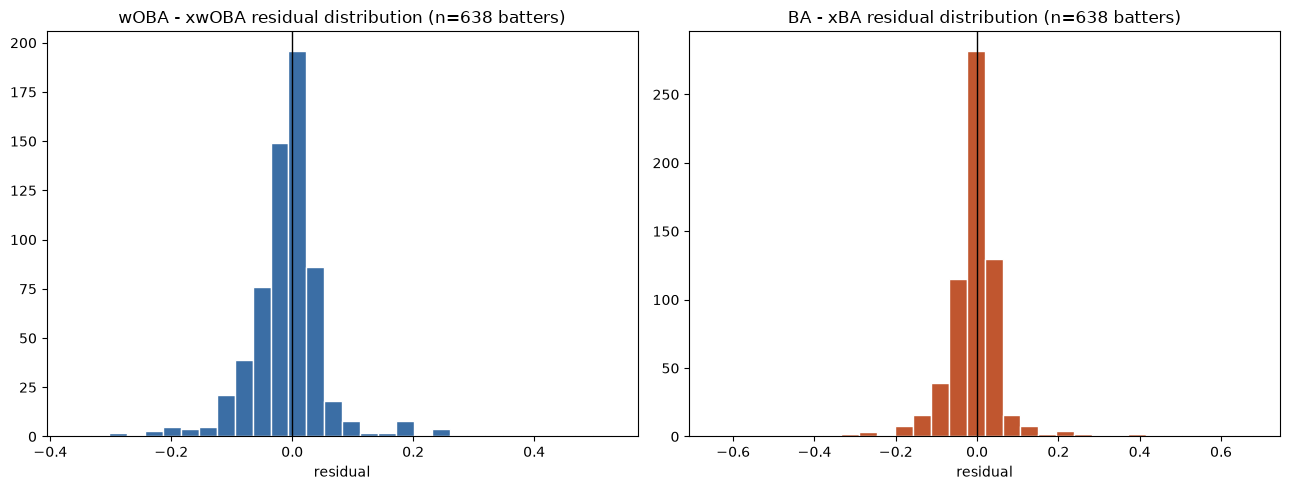

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].hist(woba_agg["woba_resid"], bins=30, color="#3b6ea5", edgecolor="white")
axes[0].axvline(0, color="black", lw=1)
axes[0].set_title(f"wOBA - xwOBA residual distribution (n={len(woba_agg)} batters)")
axes[0].set_xlabel("residual")

axes[1].hist(ba_agg["ba_resid"], bins=30, color="#c0562f", edgecolor="white")
axes[1].axvline(0, color="black", lw=1)
axes[1].set_title(f"BA - xBA residual distribution (n={len(ba_agg)} batters)")
axes[1].set_xlabel("residual")

plt.tight_layout()
plt.savefig(OUT_DIR / "xwoba_xba_residual_histograms.png", dpi=150)
plt.show()


### Residual vs. sample size

Residuals should shrink toward zero as PA/AB grows if the gap is mostly small-sample noise rather than a real, sustained skill (or model blind spot).

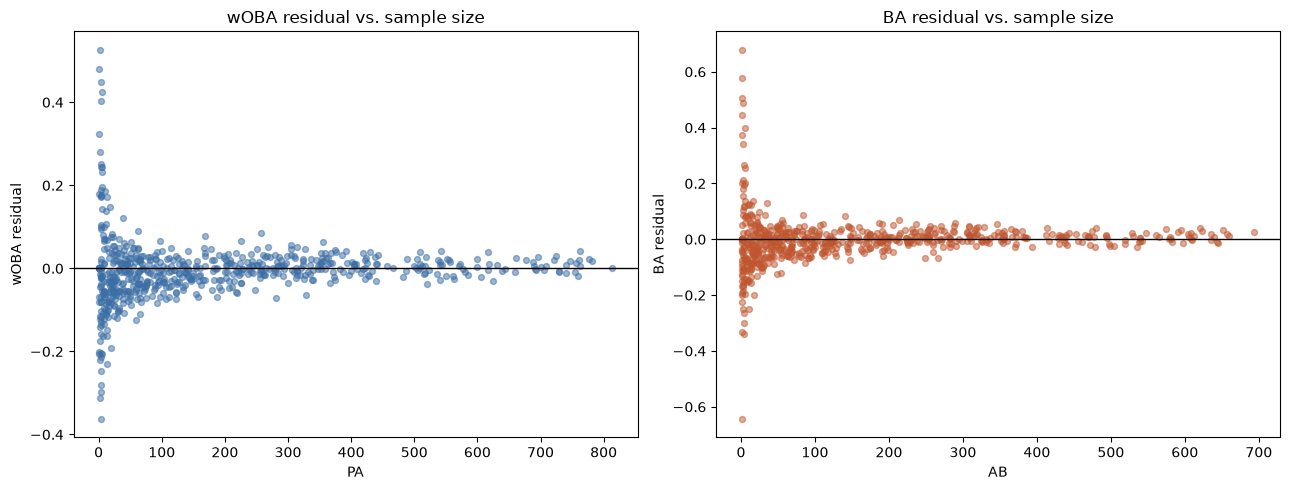

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(woba_agg["PA"], woba_agg["woba_resid"], alpha=0.5, s=18, color="#3b6ea5")
axes[0].axhline(0, color="black", lw=1)
axes[0].set_xlabel("PA")
axes[0].set_ylabel("wOBA residual")
axes[0].set_title("wOBA residual vs. sample size")

axes[1].scatter(ba_agg["AB"], ba_agg["ba_resid"], alpha=0.5, s=18, color="#c0562f")
axes[1].axhline(0, color="black", lw=1)
axes[1].set_xlabel("AB")
axes[1].set_ylabel("BA residual")
axes[1].set_title("BA residual vs. sample size")

plt.tight_layout()
plt.savefig(OUT_DIR / "xwoba_xba_residual_vs_samplesize.png", dpi=150)
plt.show()


## Save leaderboards

In [11]:
woba_agg.sort_values("woba_resid", ascending=False).to_csv(OUT_DIR / "woba_xwoba_residuals_by_batter.csv", index=False)
ba_agg.sort_values("ba_resid", ascending=False).to_csv(OUT_DIR / "ba_xba_residuals_by_batter.csv", index=False)
print("saved output/woba_xwoba_residuals_by_batter.csv")
print("saved output/ba_xba_residuals_by_batter.csv")


saved output/woba_xwoba_residuals_by_batter.csv
saved output/ba_xba_residuals_by_batter.csv


---
# Residuals by batted-ball tendency

Restricts to the *terminal, in-play* batted-ball events (the pitch that both ended
the PA and produced a batted-ball classification + trajectory). Only ~44% of
in-play terminal PAs have `batted_ball_type`/`direction`/`angle` populated
(36,558 of 83,430) — coverage looks roughly even across outcomes (out/single/
double/etc. are all missing at a similar rate), so the subset shouldn't be badly
biased, but it's a smaller sample than the full residual analysis above.

Pull/Air quadrant uses the same convention validated in
[fl_pull_x_air_paa_padlac_v2_clean.ipynb](fl_pull_x_air_paa_padlac_v2_clean.ipynb):
mirrored spray angle (`spray_pull`, pull-positive for both hands), pull cutoff
15°, air launch-angle cutoff 10°.


In [12]:
PULL_CUTOFF_DEG = 15
AIR_LA_MIN = 10

bbe = term[(term["pitch_call"] == "in_play") & term["direction"].notna() & term["angle"].notna()].copy()
bbe = bbe[bbe["batter_side"] != "undefined"]

bbe["spray_pull"] = np.where(bbe["batter_side"] == "right", -bbe["direction"], bbe["direction"])
bbe["is_pull"] = bbe["spray_pull"] > PULL_CUTOFF_DEG
bbe["is_air"] = bbe["angle"] >= AIR_LA_MIN
bbe["quadrant"] = np.select(
    [bbe["is_pull"] & bbe["is_air"], bbe["is_pull"] & ~bbe["is_air"],
     ~bbe["is_pull"] & bbe["is_air"]],
    ["Pull+Air", "Pull only", "Air only"],
    default="Neither",
)

print(f"{len(bbe):,} batted-ball events with direction/angle tracked")
print(f"Pull%: {bbe['is_pull'].mean():.3f}   Air%: {bbe['is_air'].mean():.3f}   (FL 2025 ref ~0.36 / ~0.565)")

bbe_woba = bbe[bbe["woba"].notna() & bbe["xwoba"].notna()]
bbe_ba = bbe[bbe["is_AB"] & bbe["xba"].notna()]
print(f"wOBA-eligible BBE: {len(bbe_woba):,}   BA-eligible BBE: {len(bbe_ba):,}")


80,773 batted-ball events with direction/angle tracked


Pull%: 0.387   Air%: 0.535   (FL 2025 ref ~0.36 / ~0.565)
wOBA-eligible BBE: 80,349   BA-eligible BBE: 79,193


## Residual by raw batted-ball type (GB/FB/LD/PU/...)

In [13]:
def resid_table(frame, actual_col, exp_col, group_col, hit_col=None):
    g = frame.groupby(group_col)
    out = g[exp_col].agg(n="size", expected="mean")
    if hit_col:
        out["actual"] = g[hit_col].mean()
    else:
        out["actual"] = g[actual_col].mean()
    out["residual"] = out["actual"] - out["expected"]
    return out.sort_values("residual", ascending=False)

bbt_woba = resid_table(bbe_woba, "woba", "xwoba", "batted_ball_type")
bbt_ba = resid_table(bbe_ba, None, "xba", "batted_ball_type", hit_col="is_hit")

print("--- wOBA vs xwOBA by batted_ball_type ---")
print(bbt_woba.round(3))
print()
print("--- BA vs xBA by batted_ball_type ---")
print(bbt_ba.round(3))


--- wOBA vs xwOBA by batted_ball_type ---


                      n  expected  actual  residual
batted_ball_type                                   
BUNT                178     0.204   0.569     0.365
BL                  574     0.592   0.880     0.287
SB                   30     0.181   0.413     0.232
CH                  548     0.175   0.353     0.178
LD                 7360     0.717   0.805     0.087
PU                 2027     0.095   0.089    -0.005
FB                 9921     0.408   0.402    -0.006
GB                14090     0.268   0.248    -0.020
FO                  570     0.028   0.003    -0.024



--- BA vs xBA by batted_ball_type ---
                      n  expected  actual  residual
batted_ball_type                                   
BUNT                174     0.218   0.609     0.391
BL                  574     0.611   0.901     0.289
SB                   30     0.191   0.433     0.243
CH                  548     0.184   0.367     0.183
LD                 7332     0.677   0.754     0.077
PU                 2023     0.095   0.089    -0.005
FB                 9443     0.283   0.278    -0.005
FO                  567     0.022   0.002    -0.020
GB                14089     0.274   0.254    -0.020


## Residual by Pull/Air quadrant

In [14]:
quad_woba = resid_table(bbe_woba, "woba", "xwoba", "quadrant")
quad_ba = resid_table(bbe_ba, None, "xba", "quadrant", hit_col="is_hit")

print("--- wOBA vs xwOBA by quadrant ---")
print(quad_woba.round(3))
print()
print("--- BA vs xBA by quadrant ---")
print(quad_ba.round(3))


--- wOBA vs xwOBA by quadrant ---
               n  expected  actual  residual
quadrant                                    
Pull+Air   12038     0.575   0.681     0.106
Neither    18151     0.324   0.342     0.018
Pull only  19068     0.269   0.256    -0.013
Air only   31092     0.424   0.386    -0.038

--- BA vs xBA by quadrant ---
               n  expected  actual  residual
quadrant                                    
Pull+Air   11812     0.464   0.527     0.063
Neither    18143     0.331   0.352     0.021
Air only   30182     0.358   0.344    -0.014
Pull only  19056     0.276   0.258    -0.017


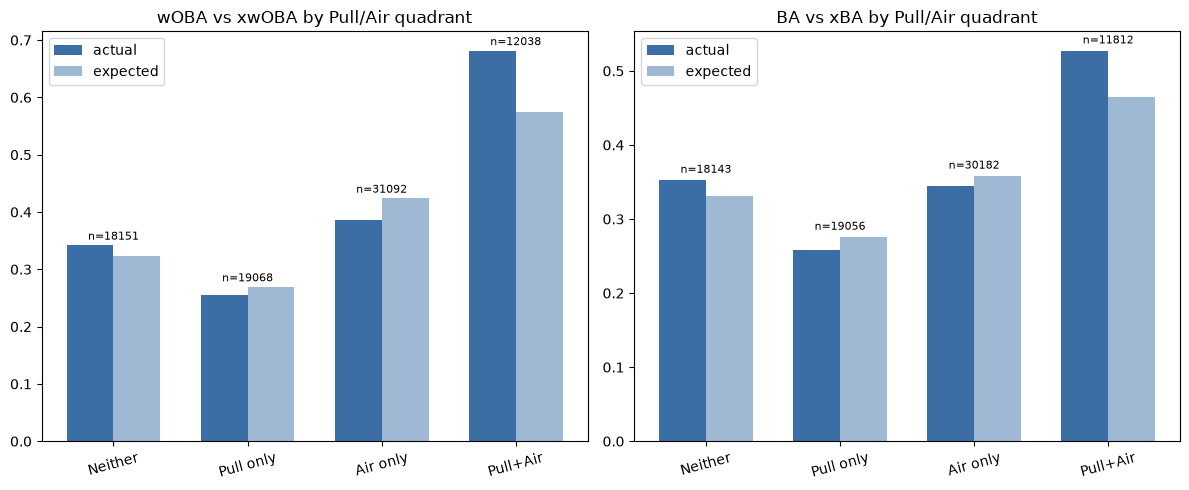

In [15]:
order = ["Neither", "Pull only", "Air only", "Pull+Air"]
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, tbl, title in [(axes[0], quad_woba.reindex(order), "wOBA vs xwOBA"),
                        (axes[1], quad_ba.reindex(order), "BA vs xBA")]:
    x = np.arange(len(tbl))
    width = 0.35
    ax.bar(x - width/2, tbl["actual"], width, label="actual", color="#3b6ea5")
    ax.bar(x + width/2, tbl["expected"], width, label="expected", color="#9fb8d4")
    for i, (_, row) in enumerate(tbl.iterrows()):
        ax.text(i, max(row["actual"], row["expected"]) + 0.01, f"n={int(row['n'])}",
                ha="center", fontsize=8)
    ax.set_xticks(x)
    ax.set_xticklabels(tbl.index, rotation=15)
    ax.set_title(f"{title} by Pull/Air quadrant")
    ax.legend()

plt.tight_layout()
plt.savefig(OUT_DIR / "xwoba_xba_by_quadrant.png", dpi=150)
plt.show()


## Batter-level: does a hitter's batted-ball tendency predict their residual?

Merge each qualified batter's Pull%/Air%/PullAir% (from the batted-ball subset)
with their overall wOBA/BA residual computed earlier, and check correlation.


In [16]:
MIN_BBE = 20

tendency = (
    bbe.groupby(["batter_id", "batter"])
    .agg(BBE=("is_pull", "size"), pull_pct=("is_pull", "mean"),
         air_pct=("is_air", "mean"),
         pull_air_pct=("quadrant", lambda s: (s == "Pull+Air").mean()),
         gb_pct=("batted_ball_type", lambda s: (s.dropna() == "GB").mean()),
         fb_pct=("batted_ball_type", lambda s: (s.dropna() == "FB").mean()))
    .reset_index()
)
tendency = tendency[tendency["BBE"] >= MIN_BBE]

tendency_woba = tendency.merge(woba_agg, on=["batter_id", "batter"], how="inner")
tendency_ba = tendency.merge(ba_agg, on=["batter_id", "batter"], how="inner")

print(f"{len(tendency_woba)} batters with >= {MIN_BBE} BBE, merged to wOBA residuals")

corr_cols = ["pull_pct", "air_pct", "pull_air_pct", "gb_pct", "fb_pct"]
print()
print("Correlation with wOBA residual:")
print(tendency_woba[corr_cols + ["woba_resid"]].corr()["woba_resid"].drop("woba_resid").round(3))
print()
print("Correlation with BA residual:")
print(tendency_ba[corr_cols + ["ba_resid"]].corr()["ba_resid"].drop("ba_resid").round(3))


466 batters with >= 20 BBE, merged to wOBA residuals

Correlation with wOBA residual:
pull_pct        0.067
air_pct         0.031
pull_air_pct    0.118
gb_pct         -0.097
fb_pct         -0.131
Name: woba_resid, dtype: float64

Correlation with BA residual:
pull_pct        0.009
air_pct         0.057
pull_air_pct    0.075
gb_pct         -0.123
fb_pct         -0.083
Name: ba_resid, dtype: float64


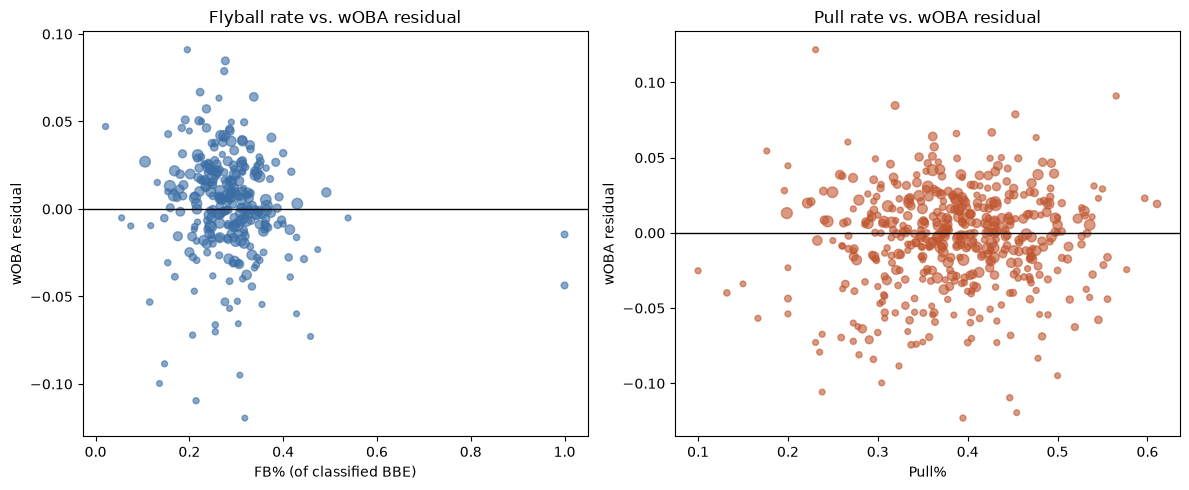

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(tendency_woba["fb_pct"], tendency_woba["woba_resid"],
                s=15 + 50 * (tendency_woba["PA"] / tendency_woba["PA"].max()),
                alpha=0.6, color="#3b6ea5")
axes[0].axhline(0, color="black", lw=1)
axes[0].set_xlabel("FB% (of classified BBE)")
axes[0].set_ylabel("wOBA residual")
axes[0].set_title("Flyball rate vs. wOBA residual")

axes[1].scatter(tendency_woba["pull_pct"], tendency_woba["woba_resid"],
                s=15 + 50 * (tendency_woba["PA"] / tendency_woba["PA"].max()),
                alpha=0.6, color="#c0562f")
axes[1].axhline(0, color="black", lw=1)
axes[1].set_xlabel("Pull%")
axes[1].set_ylabel("wOBA residual")
axes[1].set_title("Pull rate vs. wOBA residual")

plt.tight_layout()
plt.savefig(OUT_DIR / "xwoba_residual_vs_tendency.png", dpi=150)
plt.show()


## Save tendency + residual table

In [18]:
tendency_woba.merge(
    tendency_ba[["batter_id", "batter", "AB", "hits", "actual_ba", "exp_ba", "ba_resid"]],
    on=["batter_id", "batter"], how="left"
).sort_values("woba_resid", ascending=False).to_csv(
    OUT_DIR / "batted_ball_tendency_residuals_by_batter.csv", index=False
)
print("saved output/batted_ball_tendency_residuals_by_batter.csv")


saved output/batted_ball_tendency_residuals_by_batter.csv


---
# Batted-ball-level (event-level) residuals

Same `bbe` batted-ball events, but now looking at the raw per-event gap instead
of bucket/batter averages:

- `woba_resid` = `woba` − `xwoba` for every classified batted ball
- `ba_resid` = `is_hit` (0/1) − `xba` for every AB-eligible one

This is the highest-resolution view — bucket averages (batted_ball_type,
quadrant) are just local means of this surface.


In [19]:
bbe["woba_resid"] = bbe["woba"] - bbe["xwoba"]
bbe["ba_resid"] = np.where(bbe["is_AB"], bbe["is_hit"].astype(float) - bbe["xba"], np.nan)

print(bbe["woba_resid"].describe())


count    80349.000000
mean         0.002186
std          0.443231
min         -1.782000
25%         -0.228000
50%         -0.076000
75%          0.238000
max          1.871000
Name: woba_resid, dtype: float64


## Residual surface over exit velocity x launch angle

Binned mean `woba_resid` (color) across the actual EV/LA grid — shows where the model is under/overselling contact quality, at full resolution rather than the 4 pull/air buckets.

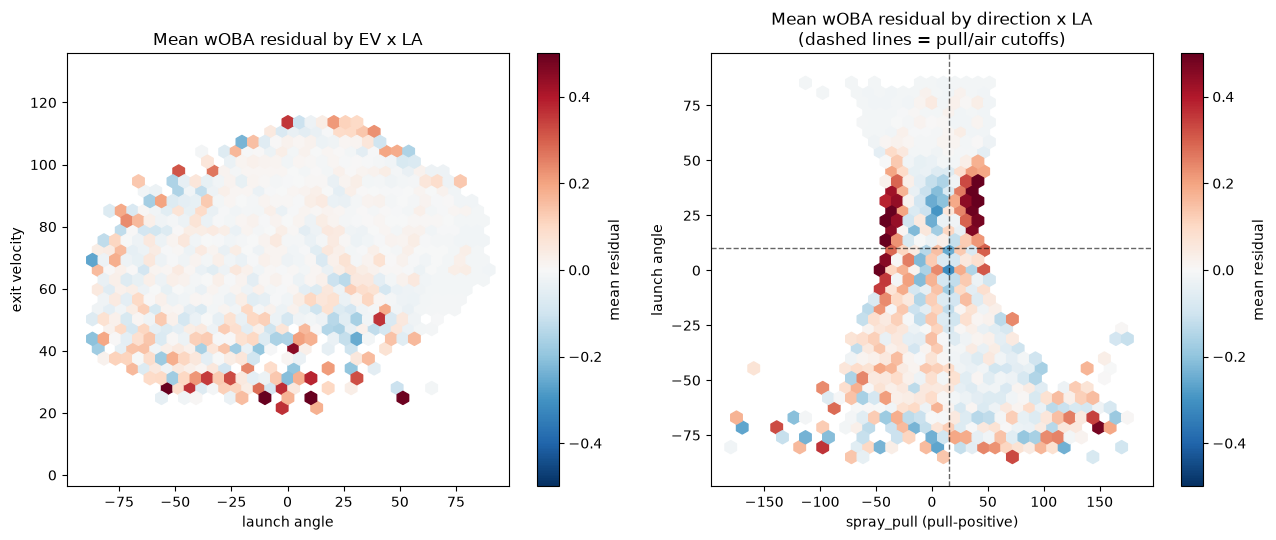

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

hb1 = axes[0].hexbin(bbe["angle"], bbe["exit_speed"], C=bbe["woba_resid"],
                      reduce_C_function=np.mean, gridsize=35, cmap="RdBu_r",
                      vmin=-0.5, vmax=0.5, mincnt=5)
axes[0].set_xlabel("launch angle")
axes[0].set_ylabel("exit velocity")
axes[0].set_title("Mean wOBA residual by EV x LA")
plt.colorbar(hb1, ax=axes[0], label="mean residual")

hb2 = axes[1].hexbin(bbe["spray_pull"], bbe["angle"], C=bbe["woba_resid"],
                      reduce_C_function=np.mean, gridsize=35, cmap="RdBu_r",
                      vmin=-0.5, vmax=0.5, mincnt=5)
axes[1].axvline(PULL_CUTOFF_DEG, color="black", lw=1, ls="--", alpha=0.6)
axes[1].axhline(AIR_LA_MIN, color="black", lw=1, ls="--", alpha=0.6)
axes[1].set_xlabel("spray_pull (pull-positive)")
axes[1].set_ylabel("launch angle")
axes[1].set_title("Mean wOBA residual by direction x LA\n(dashed lines = pull/air cutoffs)")
plt.colorbar(hb2, ax=axes[1], label="mean residual")

plt.tight_layout()
plt.savefig(OUT_DIR / "woba_residual_surface.png", dpi=150)
plt.show()


## Most extreme individual batted balls

"Luckiest" contact (weak/expected-out quality that became a big hit) vs. "unluckiest" contact (well-struck balls that turned into outs).

In [21]:
cols = ["batter", "batter_team", "date", "exit_speed", "angle", "direction",
        "batted_ball_type", "quadrant", "play_result", "woba", "xwoba", "woba_resid"]

extreme = bbe.dropna(subset=["woba_resid"]).sort_values("woba_resid")
print("--- 15 most \"unlucky\" batted balls (well hit, low actual value) ---")
print(extreme.head(15)[cols].to_string(index=False))
print()
print("--- 15 most \"lucky\" batted balls (weakly modeled, high actual value) ---")
print(extreme.tail(15)[cols].sort_values("woba_resid", ascending=False)[cols].to_string(index=False))


--- 15 most "unlucky" batted balls (well hit, low actual value) ---
            batter            batter_team       date  exit_speed     angle  direction batted_ball_type quadrant play_result  woba  xwoba  woba_resid
     Bobo, Brendan        Florence Y'alls 2025-08-02   107.06609 27.930300   5.781998              NaN Air only         out   0.0  1.782      -1.782
     Reed, Tyreque Washington Wild Things 2025-08-02   107.59654 27.817639 -13.826785              NaN Air only         out   0.0  1.770      -1.770
        Roby, Sean   Sussex County Miners 2025-06-20   108.05267 28.473844 -10.489034              NaN Air only         out   0.0  1.766      -1.766
     Reed, Tyreque Washington Wild Things 2025-06-12   106.34913 31.188225   2.166917              NaN Air only         out   0.0  1.720      -1.720
        Roby, Sean   Sussex County Miners 2026-05-23   106.94823 26.280516  -1.971338               FB Air only         out   0.0  1.719      -1.719
     Bender, Derek           Brockton 

## Save batted-ball-level residual table

In [22]:
save_cols = ["game_id", "date", "year", "batter", "batter_id", "batter_team", "batter_side",
             "pitcher", "pitcher_id", "pitcher_team",
             "exit_speed", "angle", "direction", "spray_pull", "is_pull", "is_air", "quadrant",
             "batted_ball_type", "play_result", "is_hit", "is_AB",
             "woba", "xwoba", "woba_resid", "xba", "ba_resid"]

bbe[save_cols].to_csv(OUT_DIR / "batted_ball_event_residuals.csv", index=False)
print(f"saved output/batted_ball_event_residuals.csv ({len(bbe):,} rows)")


saved output/batted_ball_event_residuals.csv (80,773 rows)


---
# Mississippi Mud Monsters (Trustmark Park) vs. rest of league

Re-pulled `home_team`/`away_team` (not in the original column set) to test the
park-factor hypothesis: `home_team == "Mississippi Mud Monsters"` maps 1:1 to
`stadium == "TrustmarkPark"` (27,406 pitches, no other team plays there), so
either filter works — using `home_team` below since it's the more explicit
"which park hosted this game" signal.


In [23]:
df2 = pd.read_parquet("2025_2026_pitches.parquet")  # reload with home_team/away_team
term2 = df2[df2["is_terminal_pitch"] == "1"].copy()
term2 = term2[~term2["play_result"].isin(["stolen_base", "caught_stealing"])]
term2["is_hit"] = term2["play_result"].isin(["single", "double", "triple", "home_run"])
term2["is_AB"] = ~(
    (term2["k_or_bb"] == "walk")
    | (term2["pitch_call"] == "hit_by_pitch")
    | (term2["play_result"] == "sacrifice")
)

is_mmm = term2["home_team"] == "Mississippi Mud Monsters"
print(f"MMM home PAs: {is_mmm.sum():,}   Rest-of-league PAs: {(~is_mmm).sum():,}")


MMM home PAs: 7,155   Rest-of-league PAs: 116,280


## League-level calibration: MMM home vs. rest

In [24]:
def calib(frame, label):
    w = frame[frame["woba"].notna() & frame["xwoba"].notna()]
    b = frame[frame["is_AB"] & frame["xba"].notna()]
    return pd.Series({
        "group": label,
        "PA_woba": len(w), "actual_woba": w["woba"].mean(), "exp_woba": w["xwoba"].mean(),
        "woba_resid": w["woba"].mean() - w["xwoba"].mean(),
        "AB_ba": len(b), "actual_ba": b["is_hit"].mean(), "exp_ba": b["xba"].mean(),
        "ba_resid": b["is_hit"].mean() - b["xba"].mean(),
    })

calib_tbl = pd.DataFrame([
    calib(term2[is_mmm], "MMM home (Trustmark Park)"),
    calib(term2[~is_mmm], "Rest of league"),
])
calib_tbl


,group,PA_woba,actual_woba,exp_woba,woba_resid,AB_ba,actual_ba,exp_ba,ba_resid
0,MMM home (Trustmark Park),7008,0.354815,0.373548,-0.018733,5918,0.269010,0.276506,-0.007496
1,Rest of league,113293,0.367486,0.364752,0.002734,96982,0.271659,0.267309,0.004350


## Batted-ball-level: rebuild pull/air quadrants split by home park

In [25]:
bbe2 = term2[(term2["pitch_call"] == "in_play") & term2["direction"].notna() & term2["angle"].notna()].copy()
bbe2 = bbe2[bbe2["batter_side"] != "undefined"]
bbe2["spray_pull"] = np.where(bbe2["batter_side"] == "right", -bbe2["direction"], bbe2["direction"])
bbe2["is_pull"] = bbe2["spray_pull"] > PULL_CUTOFF_DEG
bbe2["is_air"] = bbe2["angle"] >= AIR_LA_MIN
bbe2["quadrant"] = np.select(
    [bbe2["is_pull"] & bbe2["is_air"], bbe2["is_pull"] & ~bbe2["is_air"],
     ~bbe2["is_pull"] & bbe2["is_air"]],
    ["Pull+Air", "Pull only", "Air only"], default="Neither",
)
bbe2["woba_resid"] = bbe2["woba"] - bbe2["xwoba"]
bbe2["is_mmm_home"] = bbe2["home_team"] == "Mississippi Mud Monsters"

quad_cmp = (
    bbe2[bbe2["woba"].notna() & bbe2["xwoba"].notna()]
    .groupby(["is_mmm_home", "quadrant"])
    .agg(n=("woba_resid", "size"), actual=("woba", "mean"), expected=("xwoba", "mean"))
)
quad_cmp["residual"] = quad_cmp["actual"] - quad_cmp["expected"]
quad_cmp = quad_cmp.reindex(["Neither", "Pull only", "Air only", "Pull+Air"], level="quadrant")
quad_cmp.round(3)


n  actual  expected  residual
is_mmm_home quadrant                                    
False       Neither    17085   0.341     0.324     0.017
            Pull only  17896   0.256     0.269    -0.013
            Air only   29224   0.390     0.425    -0.034
            Pull+Air   11336   0.687     0.576     0.111
True        Neither     1066   0.348     0.322     0.026
            Pull only   1172   0.260     0.270    -0.010
            Air only    1868   0.315     0.408    -0.092
            Pull+Air     702   0.592     0.559     0.034

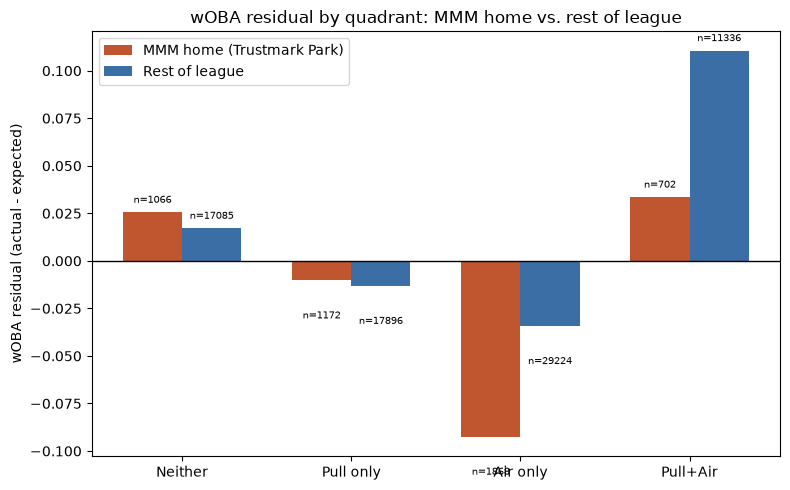

In [26]:
order = ["Neither", "Pull only", "Air only", "Pull+Air"]
mmm_q = quad_cmp.loc[True].reindex(order)
rest_q = quad_cmp.loc[False].reindex(order)

fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(len(order))
width = 0.35
ax.bar(x - width/2, mmm_q["residual"], width, label="MMM home (Trustmark Park)", color="#c0562f")
ax.bar(x + width/2, rest_q["residual"], width, label="Rest of league", color="#3b6ea5")
ax.axhline(0, color="black", lw=1)
for i, (n_mmm, n_rest) in enumerate(zip(mmm_q["n"], rest_q["n"])):
    ax.text(i - width/2, mmm_q["residual"].iloc[i] + (0.005 if mmm_q["residual"].iloc[i] >= 0 else -0.02), f"n={n_mmm}", ha="center", fontsize=7)
    ax.text(i + width/2, rest_q["residual"].iloc[i] + (0.005 if rest_q["residual"].iloc[i] >= 0 else -0.02), f"n={n_rest}", ha="center", fontsize=7)
ax.set_xticks(x)
ax.set_xticklabels(order)
ax.set_ylabel("wOBA residual (actual - expected)")
ax.set_title("wOBA residual by quadrant: MMM home vs. rest of league")
ax.legend()
plt.tight_layout()
plt.savefig(OUT_DIR / "mmm_vs_league_quadrant_residual.png", dpi=150)
plt.show()


## Cheap-homer check: is Trustmark Park producing homers on weaker contact?

Directly tests the short-fence hypothesis: among fly balls (LA >= 10), what's
the actual home-run rate at low-to-moderate exit velocity (< 95 mph, i.e. not
"hard hit"), MMM home vs. rest of league?


In [27]:
fb = bbe2[(bbe2["is_air"]) & (bbe2["exit_speed"] < 95) & bbe2["exit_speed"].notna()]
hr_rate = fb.groupby("is_mmm_home").apply(
    lambda g: pd.Series({"n_fly_balls": len(g), "hr_rate": (g["play_result"] == "home_run").mean()}),
    include_groups=False,
)
hr_rate.index = ["Rest of league", "MMM home"]
hr_rate


,n_fly_balls,hr_rate
Rest of league,28713.0,0.012468
MMM home,1909.0,0.000000


---
# Batter deep dive: Kyle Booker, 2025 vs. 2026

Same `batter_id` (694463) and team (Mississippi Mud Monsters) both years —
380 PA in 2025, 396 in 2026 — so a clean year-over-year split, no
`batter_id`-per-season merge issue like Ranko Stefanovic had.


In [28]:
kyle_all = df[df["batter"] == "Booker, Kyle"].copy()
kyle_term = term[term["batter"] == "Booker, Kyle"].copy()

print(kyle_term.groupby("year").size().rename("PA"))


year
2025    380
2026    396
Name: PA, dtype: int64


## Outcome summary: wOBA/xwOBA and BA/xBA by year

In [29]:
def year_calib(frame):
    w = frame[frame["woba"].notna() & frame["xwoba"].notna()]
    b = frame[frame["is_AB"] & frame["xba"].notna()]
    return pd.Series({
        "PA": len(frame), "PA_woba": len(w),
        "actual_woba": w["woba"].mean(), "exp_woba": w["xwoba"].mean(),
        "woba_resid": w["woba"].mean() - w["xwoba"].mean(),
        "AB": len(b), "hits": b["is_hit"].sum(),
        "actual_ba": b["is_hit"].mean(), "exp_ba": b["xba"].mean(),
        "ba_resid": b["is_hit"].mean() - b["xba"].mean(),
    })

kyle_by_year = kyle_term.groupby("year").apply(year_calib, include_groups=False)
kyle_by_year.loc["change (26-25)"] = kyle_by_year.loc[2026] - kyle_by_year.loc[2025]
kyle_by_year.round(3)


,PA,PA_woba,actual_woba,exp_woba,woba_resid,AB,hits,actual_ba,exp_ba,ba_resid
year,,,,,,,,,,
2025,380.0,374.0,0.390,0.394,-0.003,321.0,98.0,0.305,0.301,0.004
2026,396.0,388.0,0.384,0.368,0.016,339.0,101.0,0.298,0.277,0.021
change (26-25),16.0,14.0,-0.006,-0.026,0.019,18.0,3.0,-0.007,-0.024,0.017


## Plate discipline by year (all pitches seen, not just PA-ending)

In [30]:
def discipline(frame):
    return pd.Series({
        "pitches": len(frame),
        "swing_pct": frame["swing"].mean(),
        "zone_pct": 1 - frame["outside_zone"].mean(),
        "chase_pct": frame.loc[frame["outside_zone"] == 1, "chase"].mean(),
        "whiff_pct": frame.loc[frame["swing"] == 1, "whiff"].mean(),
        "csoe": frame["csoe"].mean(),
        "avg_batspeed": frame["batspeed"].mean(),
    })

kyle_discipline = kyle_all.groupby("year").apply(discipline, include_groups=False)
kyle_discipline.loc["change (26-25)"] = kyle_discipline.loc[2026] - kyle_discipline.loc[2025]
kyle_discipline.round(3)


,pitches,swing_pct,zone_pct,chase_pct,whiff_pct,csoe,avg_batspeed
year,,,,,,,
2025,1489.0,0.437,0.466,0.240,0.264,-0.001,54.644
2026,1509.0,0.469,0.475,0.262,0.274,-0.013,54.549
change (26-25),20.0,0.031,0.009,0.022,0.010,-0.011,-0.095


## Batted-ball profile by year

In [31]:
kyle_bbe = bbe[bbe["batter"] == "Booker, Kyle"].copy()

def bb_profile(frame):
    return pd.Series({
        "BBE": len(frame),
        "avg_exit_speed": frame["exit_speed"].mean(),
        "avg_angle": frame["angle"].mean(),
        "hard_hit_pct": (frame["exit_speed"] >= 95).mean(),
        "pull_pct": frame["is_pull"].mean(),
        "air_pct": frame["is_air"].mean(),
        "pull_air_pct": (frame["quadrant"] == "Pull+Air").mean(),
        "gb_pct": (frame["batted_ball_type"].dropna() == "GB").mean(),
        "fb_pct": (frame["batted_ball_type"].dropna() == "FB").mean(),
        "ld_pct": (frame["batted_ball_type"].dropna() == "LD").mean(),
        "type_tagged_n": frame["batted_ball_type"].notna().sum(),
    })

kyle_bb_by_year = kyle_bbe.groupby("year").apply(bb_profile, include_groups=False)
kyle_bb_by_year.loc["change (26-25)"] = kyle_bb_by_year.loc[2026] - kyle_bb_by_year.loc[2025]
kyle_bb_by_year.round(3)


,BBE,avg_exit_speed,avg_angle,hard_hit_pct,pull_pct,air_pct,pull_air_pct,gb_pct,fb_pct,ld_pct,type_tagged_n
year,,,,,,,,,,,
2025,256.0,84.753,7.457,0.297,0.328,0.520,0.117,NaN,NaN,NaN,0.0
2026,269.0,85.131,0.389,0.309,0.372,0.409,0.089,0.492,0.212,0.203,236.0
change (26-25),13.0,0.378,-7.068,0.012,0.044,-0.111,-0.028,NaN,NaN,NaN,236.0


## Which specific batted balls are driving the xwOBA gap each year

In [32]:
cols = ["date", "exit_speed", "angle", "spray_pull", "batted_ball_type", "quadrant",
        "play_result", "woba", "xwoba", "woba_resid"]

for yr in [2025, 2026]:
    sub = kyle_bbe[(kyle_bbe["year"] == yr) & kyle_bbe["woba_resid"].notna()].sort_values("woba_resid")
    print(f"--- {yr}: biggest under-performers (well hit, low value) ---")
    print(sub.head(5)[cols].to_string(index=False))
    print(f"--- {yr}: biggest over-performers (weak model value, actually valuable) ---")
    print(sub.tail(5)[cols].sort_values("woba_resid", ascending=False)[cols].to_string(index=False))
    print(f"{yr} total woba_resid sum across BBE: {sub['woba_resid'].sum():.3f}  (n={len(sub)})")
    print()


--- 2025: biggest under-performers (well hit, low value) ---
      date  exit_speed     angle  spray_pull batted_ball_type quadrant play_result  woba  xwoba  woba_resid
2025-08-20   101.38309 27.421780   -2.400609              NaN Air only         out   0.0  1.416      -1.416
2025-08-28   105.94395 20.061584   22.397068              NaN Pull+Air         out   0.0  1.097      -1.097
2025-06-29   100.17061 32.910227    1.609758              NaN Air only         out   0.0  1.031      -1.031
2025-08-07   100.32265 22.685054   -3.661172              NaN Air only         out   0.0  0.988      -0.988
2025-05-18    98.87393 26.190822  -15.226144              NaN Air only         out   0.0  0.957      -0.957
--- 2025: biggest over-performers (weak model value, actually valuable) ---
      date  exit_speed     angle  spray_pull batted_ball_type quadrant play_result  woba  xwoba  woba_resid
2025-06-03    91.86015 29.487735  -21.991647              NaN Air only    home_run 1.895  0.353       1.542

## Contact quality: EV x LA, 2025 vs. 2026

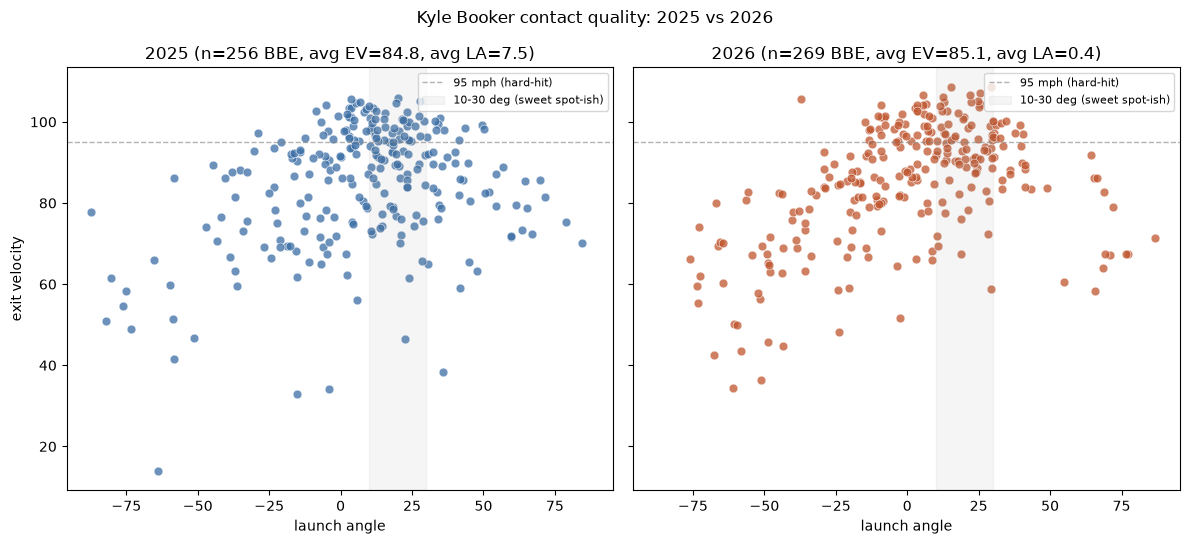

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), sharex=True, sharey=True)
for ax, yr, color in zip(axes, [2025, 2026], ["#3b6ea5", "#c0562f"]):
    sub = kyle_bbe[kyle_bbe["year"] == yr]
    ax.scatter(sub["angle"], sub["exit_speed"], s=40, alpha=0.75, color=color,
               edgecolors="white", linewidths=0.5)
    ax.axhline(95, color="gray", ls="--", lw=1, alpha=0.6, label="95 mph (hard-hit)")
    ax.axvspan(10, 30, color="gray", alpha=0.08, label="10-30 deg (sweet spot-ish)")
    ax.set_title(f"{yr} (n={len(sub)} BBE, avg EV={sub['exit_speed'].mean():.1f}, avg LA={sub['angle'].mean():.1f})")
    ax.set_xlabel("launch angle")
    ax.legend(fontsize=8, loc="upper right")
axes[0].set_ylabel("exit velocity")
plt.suptitle("Kyle Booker contact quality: 2025 vs 2026")
plt.tight_layout()
plt.savefig(OUT_DIR / "kyle_booker_ev_la.png", dpi=150)
plt.show()


## wOBA vs. xwOBA trend over time

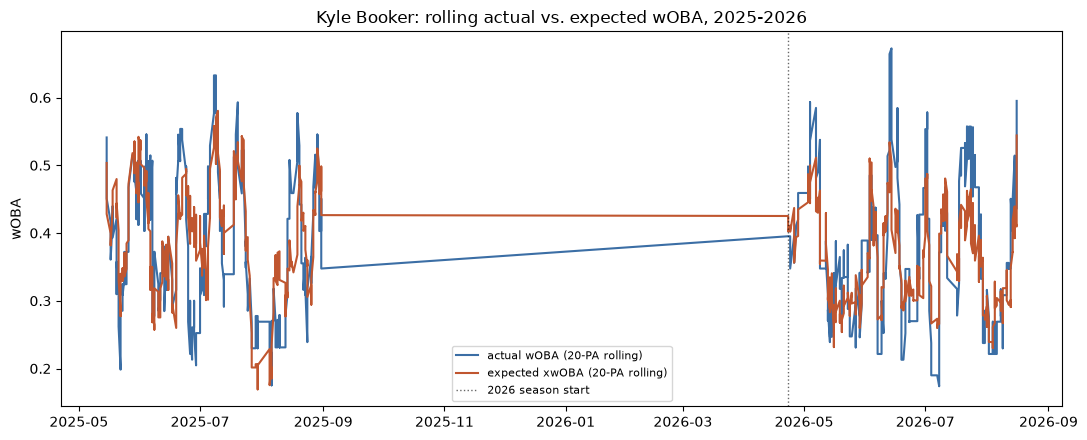

In [34]:
kw = kyle_term[kyle_term["woba"].notna() & kyle_term["xwoba"].notna()].sort_values("date").copy()
kw["date_dt"] = pd.to_datetime(kw["date"])
kw["actual_roll"] = kw["woba"].rolling(20, min_periods=10).mean()
kw["exp_roll"] = kw["xwoba"].rolling(20, min_periods=10).mean()

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(kw["date_dt"], kw["actual_roll"], label="actual wOBA (20-PA rolling)", color="#3b6ea5")
ax.plot(kw["date_dt"], kw["exp_roll"], label="expected xwOBA (20-PA rolling)", color="#c0562f")
season_break = kw.loc[kw["year"] == 2026, "date_dt"].min()
if pd.notna(season_break):
    ax.axvline(season_break, color="black", ls=":", lw=1, alpha=0.6, label="2026 season start")
ax.set_ylabel("wOBA")
ax.set_title("Kyle Booker: rolling actual vs. expected wOBA, 2025-2026")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(OUT_DIR / "kyle_booker_woba_trend.png", dpi=150)
plt.show()


---
# Kyle Booker: what actually changed, 2025 -> 2026

Walks/strikeouts, batted-ball shape (both the raw type tag where available and
a launch-angle-bucket version that works identically in both years since
`batted_ball_type` is 2026-only), the pull/air quadrant split, and home
(Trustmark Park) vs. away.


In [35]:
kyle_term_full = term[term["batter"] == "Booker, Kyle"].copy()
kyle_term_full["is_home"] = kyle_term_full["batter_team"] == kyle_term_full["home_team"]
kyle_bbe_full = bbe[bbe["batter"] == "Booker, Kyle"].copy()
kyle_bbe_full["is_home"] = kyle_bbe_full["batter_team"] == kyle_bbe_full["home_team"]


## Walks & strikeouts: rate and value, by year

BB/K are deterministic-weight events (no contact-quality model needed), so actual should equal expected almost exactly here — useful as a control against the batted-ball categories below.

In [36]:
def bb_k_rate(frame):
    pa = len(frame)
    k_mask = frame["k_or_bb"] == "strikeout"
    bb_mask = frame["k_or_bb"] == "walk"
    return pd.Series({
        "PA": pa,
        "K_pct": k_mask.mean(), "BB_pct": bb_mask.mean(),
        "K_actual_woba": frame.loc[k_mask, "woba"].mean(), "K_exp_xwoba": frame.loc[k_mask, "xwoba"].mean(),
        "BB_actual_woba": frame.loc[bb_mask, "woba"].mean(), "BB_exp_xwoba": frame.loc[bb_mask, "xwoba"].mean(),
    })

kyle_bbk = kyle_term_full.groupby("year").apply(bb_k_rate, include_groups=False)
kyle_bbk.loc["change (26-25)"] = kyle_bbk.loc[2026] - kyle_bbk.loc[2025]
kyle_bbk.round(3)


,PA,K_pct,BB_pct,K_actual_woba,K_exp_xwoba,BB_actual_woba,BB_exp_xwoba
year,,,,,,,
2025,380.0,0.176,0.129,0.0,0.0,0.785,0.785
2026,396.0,0.194,0.091,0.0,0.0,0.785,0.785
change (26-25),16.0,0.018,-0.038,0.0,0.0,0.000,0.000


## Batted-ball shape by year: launch-angle buckets (comparable both years)

Since `batted_ball_type` only exists for 2026, using LA buckets instead so 2025 and 2026 are measured the same way: GB-like (<10&deg;), LD-like (10-25&deg;), FB-like (25-50&deg;), PU-like (&gt;50&deg;).

In [37]:
def la_bucket(a):
    return pd.cut(a, bins=[-91, 10, 25, 50, 91], labels=["GB-like (<10)", "LD-like (10-25)", "FB-like (25-50)", "PU-like (>50)"])

kyle_bbe_full["la_bucket"] = la_bucket(kyle_bbe_full["angle"])

la_tbl = (
    kyle_bbe_full[kyle_bbe_full["woba"].notna() & kyle_bbe_full["xwoba"].notna()]
    .groupby(["year", "la_bucket"], observed=True)
    .agg(n=("woba", "size"), actual=("woba", "mean"), expected=("xwoba", "mean"))
)
la_tbl["residual"] = la_tbl["actual"] - la_tbl["expected"]
la_tbl.round(3)


n  actual  expected  residual
year la_bucket                                       
2025 GB-like (<10)    122   0.312     0.297     0.015
     LD-like (10-25)   72   0.719     0.710     0.009
     FB-like (25-50)   44   0.346     0.423    -0.077
     PU-like (>50)     17   0.000     0.024    -0.024
2026 GB-like (<10)    155   0.322     0.279     0.042
     LD-like (10-25)   54   0.734     0.711     0.023
     FB-like (25-50)   43   0.537     0.570    -0.034
     PU-like (>50)     13   0.000     0.018    -0.018

### Raw batted_ball_type tag (2026 only, for reference)

In [38]:
kbt = (
    kyle_bbe_full[(kyle_bbe_full["year"] == 2026) & kyle_bbe_full["woba"].notna() & kyle_bbe_full["xwoba"].notna()]
    .groupby("batted_ball_type")
    .agg(n=("woba", "size"), actual=("woba", "mean"), expected=("xwoba", "mean"))
)
kbt["residual"] = kbt["actual"] - kbt["expected"]
kbt.sort_values("residual", ascending=False).round(3)


,n,actual,expected,residual
batted_ball_type,,,,
BL,1,0.953,0.742,0.211
LD,48,0.959,0.750,0.208
CH,11,0.347,0.172,0.174
FO,4,0.000,0.016,-0.016
PU,4,0.000,0.016,-0.016
GB,115,0.218,0.240,-0.022
FB,50,0.386,0.508,-0.122


## Pull/Air quadrant, actual vs. expected, by year

In [39]:
quad_by_year = (
    kyle_bbe_full[kyle_bbe_full["woba"].notna() & kyle_bbe_full["xwoba"].notna()]
    .groupby(["year", "quadrant"])
    .agg(n=("woba", "size"), actual=("woba", "mean"), expected=("xwoba", "mean"))
)
quad_by_year["residual"] = quad_by_year["actual"] - quad_by_year["expected"]
quad_by_year = quad_by_year.reindex(["Neither", "Pull only", "Air only", "Pull+Air"], level="quadrant")
quad_by_year.round(3)


n  actual  expected  residual
year quadrant                                  
2025 Neither     68   0.364     0.352     0.013
     Pull only   54   0.247     0.229     0.018
     Air only   103   0.505     0.528    -0.023
     Pull+Air    30   0.497     0.525    -0.028
2026 Neither     80   0.405     0.337     0.069
     Pull only   75   0.233     0.219     0.014
     Air only    86   0.508     0.533    -0.025
     Pull+Air    24   0.792     0.721     0.071

## Home (Trustmark Park) vs. away, by year

In [40]:
def home_away_calib(frame):
    w = frame[frame["woba"].notna() & frame["xwoba"].notna()]
    b = frame[frame["is_AB"] & frame["xba"].notna()]
    return pd.Series({
        "PA": len(frame),
        "actual_woba": w["woba"].mean(), "exp_woba": w["xwoba"].mean(),
        "woba_resid": w["woba"].mean() - w["xwoba"].mean(),
        "actual_ba": b["is_hit"].mean(), "exp_ba": b["xba"].mean(),
        "ba_resid": b["is_hit"].mean() - b["xba"].mean(),
    })

home_away = kyle_term_full.groupby(["year", "is_home"]).apply(home_away_calib, include_groups=False)
home_away.round(3)


PA  actual_woba  exp_woba  woba_resid  actual_ba  exp_ba  \
year is_home                                                                
2025 False    214.0        0.382     0.363       0.019      0.297   0.278   
     True     166.0        0.401     0.434      -0.033      0.317   0.331   
2026 False    172.0        0.352     0.358      -0.006      0.265   0.274   
     True     224.0        0.408     0.376       0.032      0.323   0.279   

              ba_resid  
year is_home            
2025 False       0.019  
     True       -0.015  
2026 False      -0.009  
     True        0.044

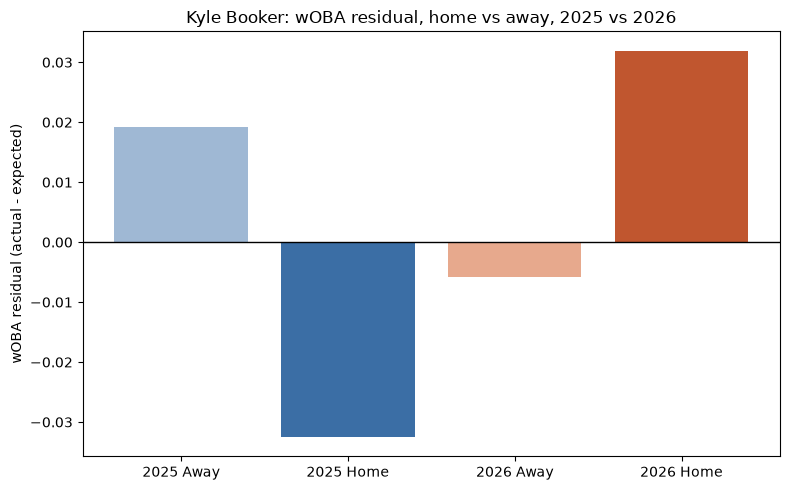

In [41]:
fig, ax = plt.subplots(figsize=(8, 5))
labels = ["2025 Away", "2025 Home", "2026 Away", "2026 Home"]
vals = [
    home_away.loc[(2025, False), "woba_resid"], home_away.loc[(2025, True), "woba_resid"],
    home_away.loc[(2026, False), "woba_resid"], home_away.loc[(2026, True), "woba_resid"],
]
colors = ["#9fb8d4", "#3b6ea5", "#e7a98d", "#c0562f"]
ax.bar(labels, vals, color=colors)
ax.axhline(0, color="black", lw=1)
ax.set_ylabel("wOBA residual (actual - expected)")
ax.set_title("Kyle Booker: wOBA residual, home vs away, 2025 vs 2026")
plt.tight_layout()
plt.savefig(OUT_DIR / "kyle_booker_home_away_resid.png", dpi=150)
plt.show()


## Batted-ball profile: home vs. away, by year

In [42]:
def bb_profile_ha(frame):
    return pd.Series({
        "BBE": len(frame),
        "avg_exit_speed": frame["exit_speed"].mean(),
        "avg_angle": frame["angle"].mean(),
        "hard_hit_pct": (frame["exit_speed"] >= 95).mean(),
        "pull_pct": frame["is_pull"].mean(),
        "air_pct": frame["is_air"].mean(),
    })

kyle_bbe_full.groupby(["year", "is_home"]).apply(bb_profile_ha, include_groups=False).round(3)


BBE  avg_exit_speed  avg_angle  hard_hit_pct  pull_pct  \
year is_home                                                             
2025 False    140.0          82.808      6.083         0.243     0.343   
     True     116.0          87.100      9.116         0.362     0.310   
2026 False    115.0          83.975     -4.526         0.339     0.374   
     True     154.0          85.995      4.059         0.286     0.370   

              air_pct  
year is_home           
2025 False      0.507  
     True       0.534  
2026 False      0.374  
     True       0.435

---
# Kyle Booker: swing decisions, 2025 vs. 2026

All pitches he saw (not just PA-ending), split by zone location, count
leverage, and pitch type.


In [43]:
kyle_pitches = df[df["batter"] == "Booker, Kyle"].copy()
kyle_pitches["in_zone"] = kyle_pitches["outside_zone"] == 0
kyle_pitches["count_state"] = np.select(
    [kyle_pitches["strikes"] == 2,
     kyle_pitches["balls"] > kyle_pitches["strikes"],
     kyle_pitches["balls"] < kyle_pitches["strikes"]],
    ["two_strikes", "ahead_in_count", "behind_in_count"],
    default="even",
)
# two_strikes takes priority over the count-leverage label
kyle_pitches.loc[kyle_pitches["strikes"] == 2, "count_state"] = "two_strikes"
print(kyle_pitches.groupby("year")["count_state"].value_counts(normalize=True).unstack().round(3))


count_state  ahead_in_count  behind_in_count   even  two_strikes
year                                                            
2025                  0.273            0.117  0.365        0.245
2026                  0.251            0.117  0.355        0.278


## Z-Swing% / O-Swing% (chase) / whiff% / contact%, by year

In [44]:
def swing_profile(frame):
    z = frame[frame["in_zone"]]
    o = frame[~frame["in_zone"]]
    swings = frame[frame["swing"] == 1]
    return pd.Series({
        "pitches": len(frame),
        "zone_pct": frame["in_zone"].mean(),
        "swing_pct": frame["swing"].mean(),
        "z_swing_pct": z["swing"].mean(),
        "o_swing_pct (chase)": o["swing"].mean(),
        "whiff_pct (per swing)": swings["whiff"].mean(),
        "contact_pct (per swing)": 1 - swings["whiff"].mean(),
        "csoe": frame["csoe"].mean(),
        "avg_batspeed_on_swings": swings["batspeed"].mean(),
    })

swing_by_year = kyle_pitches.groupby("year").apply(swing_profile, include_groups=False)
swing_by_year.loc["change (26-25)"] = swing_by_year.loc[2026] - swing_by_year.loc[2025]
swing_by_year.round(3)


,pitches,zone_pct,swing_pct,z_swing_pct,o_swing_pct (chase),whiff_pct (per swing),contact_pct (per swing),csoe,avg_batspeed_on_swings
year,,,,,,,,,
2025,1489.0,0.461,0.437,0.668,0.239,0.264,0.736,-0.001,54.644
2026,1509.0,0.475,0.469,0.696,0.263,0.274,0.726,-0.013,54.549
change (26-25),20.0,0.014,0.031,0.028,0.023,0.010,-0.010,-0.011,-0.095


## Swing decisions by count leverage, by year

In [45]:
order = ["ahead_in_count", "even", "behind_in_count", "two_strikes"]

count_swing = (
    kyle_pitches.groupby(["year", "count_state"])
    .apply(swing_profile, include_groups=False)[["pitches", "swing_pct", "o_swing_pct (chase)", "whiff_pct (per swing)"]]
)
count_swing.reindex(order, level="count_state").round(3)


pitches  swing_pct  o_swing_pct (chase)  \
year count_state                                                
2025 ahead_in_count     406.0      0.433                0.213   
     even               544.0      0.349                0.156   
     behind_in_count    174.0      0.437                0.265   
     two_strikes        365.0      0.573                0.366   
2026 ahead_in_count     379.0      0.480                0.202   
     even               535.0      0.355                0.181   
     behind_in_count    176.0      0.511                0.352   
     two_strikes        419.0      0.585                0.361   

                      whiff_pct (per swing)  
year count_state                             
2025 ahead_in_count                   0.256  
     even                             0.295  
     behind_in_count                  0.329  
     two_strikes                      0.220  
2026 ahead_in_count                   0.209  
     even                             0.295  
     behind_in_count                  0.400  
     two_strikes                      0.261

## Swing/whiff rate by plate location: 2025 vs. 2026

Hexbin heatmaps over `plate_x`/`plate_z` — left pair is swing rate (does he offer at it), right pair is whiff rate among swings (does he miss it). Batter's-eye view (positive plate_x = away from a RHH... check `batter_side` — Kyle is used as-is here, not mirrored, since it's a single batter).

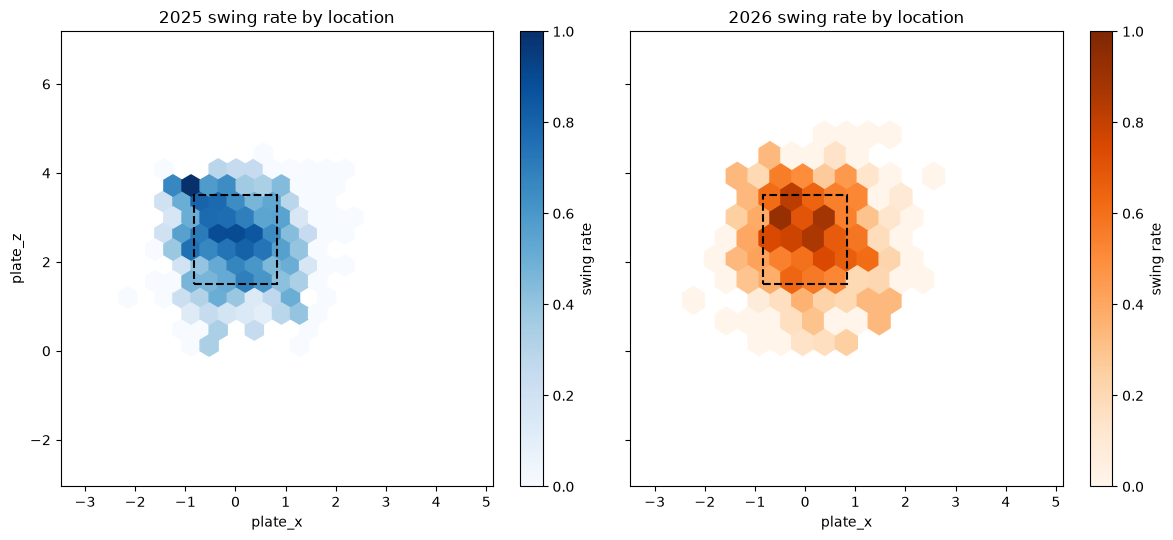

In [46]:
kp = kyle_pitches[kyle_pitches["plate_x"].notna() & kyle_pitches["plate_z"].notna()]

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), sharex=True, sharey=True)
for ax, yr, color in zip(axes, [2025, 2026], ["Blues", "Oranges"]):
    sub = kp[kp["year"] == yr]
    hb = ax.hexbin(sub["plate_x"], sub["plate_z"], C=sub["swing"], reduce_C_function=np.mean,
                    gridsize=18, cmap=color, vmin=0, vmax=1, mincnt=3)
    ax.add_patch(plt.Rectangle((-0.83, 1.5), 1.66, 2.0, fill=False, edgecolor="black", lw=1.5, ls="--"))
    ax.set_title(f"{yr} swing rate by location")
    ax.set_xlabel("plate_x")
    plt.colorbar(hb, ax=ax, label="swing rate")
axes[0].set_ylabel("plate_z")
plt.tight_layout()
plt.savefig(OUT_DIR / "kyle_booker_swing_rate_location.png", dpi=150)
plt.show()


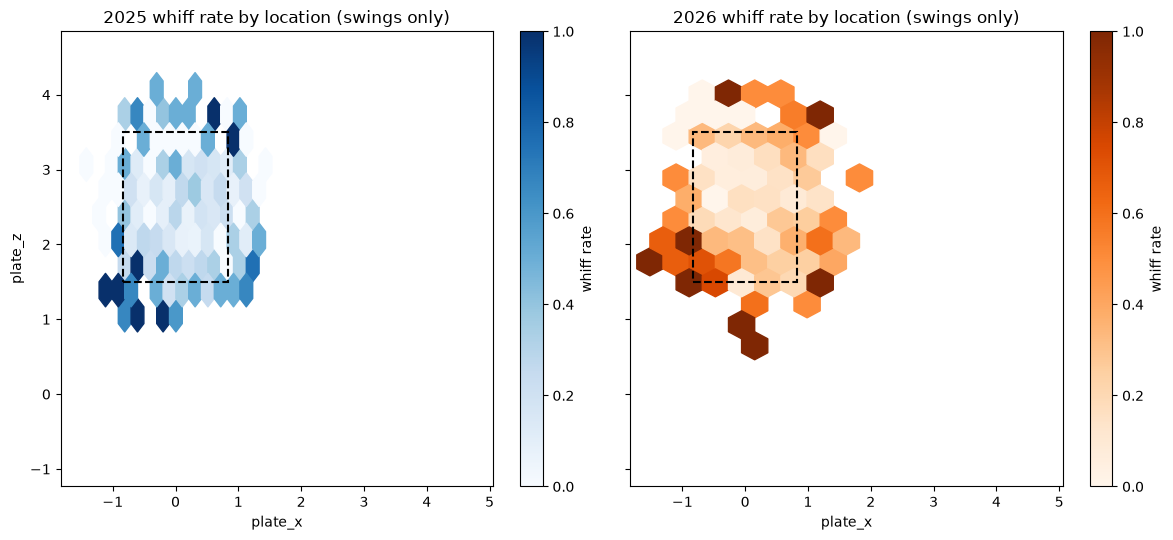

In [47]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), sharex=True, sharey=True)
for ax, yr, color in zip(axes, [2025, 2026], ["Blues", "Oranges"]):
    sub = kp[(kp["year"] == yr) & (kp["swing"] == 1)]
    hb = ax.hexbin(sub["plate_x"], sub["plate_z"], C=sub["whiff"], reduce_C_function=np.mean,
                    gridsize=15, cmap=color, vmin=0, vmax=1, mincnt=2)
    ax.add_patch(plt.Rectangle((-0.83, 1.5), 1.66, 2.0, fill=False, edgecolor="black", lw=1.5, ls="--"))
    ax.set_title(f"{yr} whiff rate by location (swings only)")
    ax.set_xlabel("plate_x")
    plt.colorbar(hb, ax=ax, label="whiff rate")
axes[0].set_ylabel("plate_z")
plt.tight_layout()
plt.savefig(OUT_DIR / "kyle_booker_whiff_rate_location.png", dpi=150)
plt.show()


## Swing decisions by pitch type, by year

In [48]:
pt_swing = (
    kyle_pitches.groupby(["year", "pitch_type"])
    .apply(swing_profile, include_groups=False)[["pitches", "swing_pct", "o_swing_pct (chase)", "whiff_pct (per swing)"]]
)
pt_swing = pt_swing[pt_swing["pitches"] >= 15]
pt_swing.round(3)


pitches  swing_pct  o_swing_pct (chase)  \
year pitch_type                                            
2025 changeup      244.0      0.434                0.273   
     curveball     140.0      0.364                0.185   
     cutter         73.0      0.466                0.273   
     four_seam     542.0      0.452                0.242   
     sinker        192.0      0.385                0.141   
     slider        237.0      0.494                0.287   
     sweeper        19.0      0.632                0.444   
2026 changeup      260.0      0.446                0.259   
     curveball     195.0      0.364                0.237   
     cutter         34.0      0.618                0.308   
     four_seam     439.0      0.547                0.301   
     sinker        214.0      0.439                0.259   
     slider        274.0      0.456                0.240   
     splitter       49.0      0.429                0.257   
     sweeper        23.0      0.391                0.182   

                 whiff_pct (per swing)  
year pitch_type                         
2025 changeup                    0.368  
     curveball                   0.333  
     cutter                      0.382  
     four_seam                   0.171  
     sinker                      0.189  
     slider                      0.325  
     sweeper                     0.500  
2026 changeup                    0.310  
     curveball                   0.408  
     cutter                      0.429  
     four_seam                   0.158  
     sinker                      0.181  
     slider                      0.376  
     splitter                    0.571  
     sweeper                     0.556

## Does he swing just as hard when chasing as when he's in the zone?

In [49]:
kp_swings = kyle_pitches[kyle_pitches["swing"] == 1].copy()
bs_by_zone = kp_swings.groupby(["year", "in_zone"])["batspeed"].agg(["size", "mean"])
bs_by_zone.round(2)


size   mean
year in_zone             
2025 False     192  50.56
     True      459  55.76
2026 False     208  47.23
     True      499  56.71

---
# Is the pressure-count decline about what he's seeing, or what he's doing?

Standard mix-vs-rate (shift-share) decomposition, restricted to
`behind_in_count` + `two_strikes` (the two states that got worse). Splits the
2025->2026 change in chase%/whiff% into:

- **mix effect** = change from seeing a different frequency of pitch types /
  locations, holding his swing/whiff rate fixed at the 2025 level
- **rate effect** = change from doing something different against the same
  pitch type / location, holding the 2026 frequency mix fixed

`zone_region` is an approximate 3-tier bucket (Heart / Shadow / Chase) built
from `plate_x`/`plate_z`, calibrated against where `outside_zone` actually
flips in the full league sample -- not his personal dynamic zone (`sz_top`/
`sz_bot`/etc. weren't pulled), so treat boundaries as approximate.


In [50]:
pressure_mask = kyle_pitches["count_state"].isin(["behind_in_count", "two_strikes"])
pressure = kyle_pitches[pressure_mask].copy()

pt_map = {"four_seam": "four_seam", "sinker": "sinker", "slider": "slider",
          "changeup": "changeup", "curveball": "curveball"}
pressure["pt_group"] = pressure["pitch_type"].map(pt_map).fillna("other")

def zone_region(row):
    x, z = row["plate_x"], row["plate_z"]
    if pd.isna(x) or pd.isna(z):
        return np.nan
    if abs(x) <= 0.44 and 1.9 <= z <= 3.0:
        return "Heart"
    if abs(x) <= 1.15 and 1.1 <= z <= 3.8:
        return "Shadow"
    return "Chase"

pressure["zone_region"] = pressure.apply(zone_region, axis=1)
print(f"pressure-count pitches: {(pressure['year']==2025).sum()} (2025), {(pressure['year']==2026).sum()} (2026)")


pressure-count pitches: 539 (2025), 595 (2026)


In [51]:
def mix_rate_decompose(frame, group_col, event_col, label):
    tab = frame.groupby(["year", group_col]).agg(n=(event_col, "size"), rate=(event_col, "mean")).reset_index()
    n0 = tab[tab.year == 2025].set_index(group_col)["n"]
    n1 = tab[tab.year == 2026].set_index(group_col)["n"]
    r0 = tab[tab.year == 2025].set_index(group_col)["rate"]
    r1 = tab[tab.year == 2026].set_index(group_col)["rate"]
    groups = sorted(set(n0.index) | set(n1.index))
    n0, n1 = n0.reindex(groups, fill_value=0), n1.reindex(groups, fill_value=0)
    r0, r1 = r0.reindex(groups), r1.reindex(groups)
    f0, f1 = n0 / n0.sum(), n1 / n1.sum()
    r0f, r1f = r0.fillna(r1), r1.fillna(r0)  # avoid spurious rate-effect from 0-sample cells

    overall0 = (f0 * r0f.fillna(0)).sum()
    overall1 = (f1 * r1f.fillna(0)).sum()
    mix_effect = ((f1 - f0) * r0f.fillna(0)).sum()
    rate_effect = (f1 * (r1f - r0f)).fillna(0).sum()

    tbl = pd.DataFrame({"freq_2025": f0.round(3), "freq_2026": f1.round(3),
                         "rate_2025": r0.round(3), "rate_2026": r1.round(3)})
    print(f"--- {label} ---")
    print(tbl)
    print(f"overall: {overall0:.3f} -> {overall1:.3f}  (diff {overall1-overall0:+.3f})")
    print(f"  mix effect  (different pitches/locations seen): {mix_effect:+.3f}")
    print(f"  rate effect (different swing decision/contact):  {rate_effect:+.3f}")
    print()
    return {"label": label, "diff": overall1 - overall0, "mix": mix_effect, "rate": rate_effect}

ooz = pressure[~pressure["in_zone"]]      # denominator for chase% = out-of-zone pitches
swings = pressure[pressure["swing"] == 1]  # denominator for whiff% = swings

results = [
    mix_rate_decompose(ooz, "pt_group", "swing", "Chase% by pitch type"),
    mix_rate_decompose(ooz, "zone_region", "swing", "Chase% by zone region"),
    mix_rate_decompose(swings, "pt_group", "whiff", "Whiff% by pitch type"),
    mix_rate_decompose(swings, "zone_region", "whiff", "Whiff% by zone region"),
]


--- Chase% by pitch type ---
           freq_2025  freq_2026  rate_2025  rate_2026
pt_group                                             
changeup       0.274      0.181      0.310      0.371
curveball      0.119      0.163      0.342      0.375
four_seam      0.267      0.219      0.353      0.440
other          0.085      0.114      0.407      0.308
sinker         0.091      0.102      0.241      0.286
slider         0.164      0.222      0.327      0.316
overall: 0.330 -> 0.359  (diff +0.028)
  mix effect  (different pitches/locations seen): +0.002
  rate effect (different swing decision/contact):  +0.026

--- Chase% by zone region ---
             freq_2025  freq_2026  rate_2025  rate_2026
zone_region                                            
Chase            0.658      0.708      0.197      0.235
Shadow           0.342      0.292      0.593      0.660
overall: 0.332 -> 0.359  (diff +0.026)
  mix effect  (different pitches/locations seen): -0.020
  rate effect (different swing dec

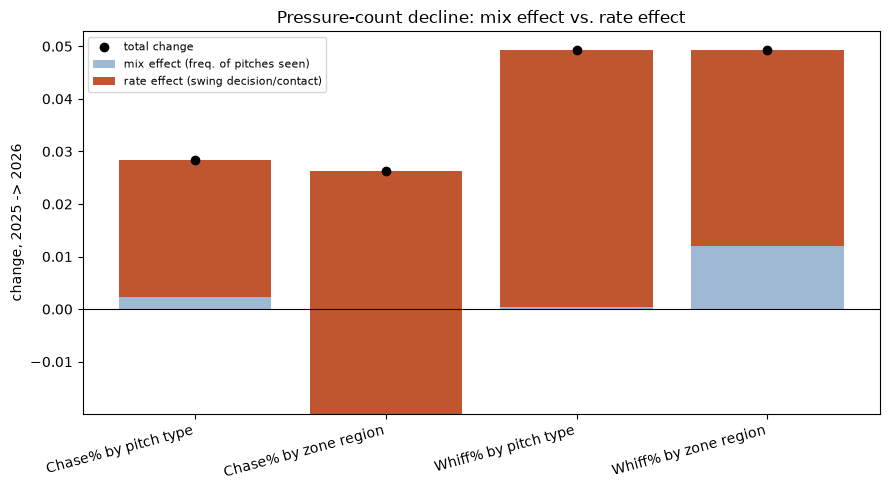

In [52]:
res_df = pd.DataFrame(results).set_index("label")
fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(res_df))
ax.bar(x, res_df["mix"], label="mix effect (freq. of pitches seen)", color="#9fb8d4")
ax.bar(x, res_df["rate"], bottom=res_df["mix"], label="rate effect (swing decision/contact)", color="#c0562f")
ax.scatter(x, res_df["diff"], color="black", zorder=5, label="total change")
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(x)
ax.set_xticklabels(res_df.index, rotation=15, ha="right")
ax.set_ylabel("change, 2025 -> 2026")
ax.set_title("Pressure-count decline: mix effect vs. rate effect")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(OUT_DIR / "kyle_booker_mix_rate_decomposition.png", dpi=150)
plt.show()


**Conclusion:** across all four breakdowns, the rate effect dominates -- in
some cases it's *larger* than the total observed change, partially offset by
a slightly favorable mix shift (fewer Shadow-zone pitches, fewer four-seamers,
which on their own would have pushed chase/whiff *down*). Pitchers aren't
meaningfully attacking him with a different pitch mix or location profile when
he's behind/two-strikes -- he's making worse decisions and worse contact
against essentially the same stuff he saw in 2025.


---
# League-wide: did fastball/breaking/offspeed usage change, 2025 -> 2026?

Grouping: Fastball = four_seam/sinker/cutter, Breaking = slider/curveball/
sweeper, Offspeed = changeup/splitter. ~1-2% of pitches are unclassified
(knuckleball, `not_him`, blank) and dropped from the shares below.


In [53]:
FASTBALL_TYPES = {"four_seam", "sinker", "cutter", "fastball"}
BREAKING_TYPES = {"slider", "curveball", "sweeper"}
OFFSPEED_TYPES = {"changeup", "splitter"}

def pt_group(pt):
    if pt in FASTBALL_TYPES: return "Fastball"
    if pt in BREAKING_TYPES: return "Breaking"
    if pt in OFFSPEED_TYPES: return "Offspeed"
    return "Other/Unknown"

league = df.copy()
league["pt_group"] = league["pitch_type"].map(pt_group)
league["count_state"] = np.select(
    [league["strikes"] == 2, league["balls"] > league["strikes"], league["balls"] < league["strikes"]],
    ["two_strikes", "ahead_in_count", "behind_in_count"], default="even",
)
league.loc[league["strikes"] == 2, "count_state"] = "two_strikes"
league_classified = league[league["pt_group"] != "Other/Unknown"]

print(f"{(league['pt_group']=='Other/Unknown').mean():.3%} of league pitches unclassified (dropped below)")
overall_share = (
    league_classified.groupby("year")["pt_group"]
    .value_counts(normalize=True).unstack()[["Fastball", "Breaking", "Offspeed"]]
)
overall_share.round(4)


1.736% of league pitches unclassified (dropped below)


pt_group,Fastball,Breaking,Offspeed
year,,,
2025,0.5591,0.2851,0.1558
2026,0.5308,0.2973,0.1719


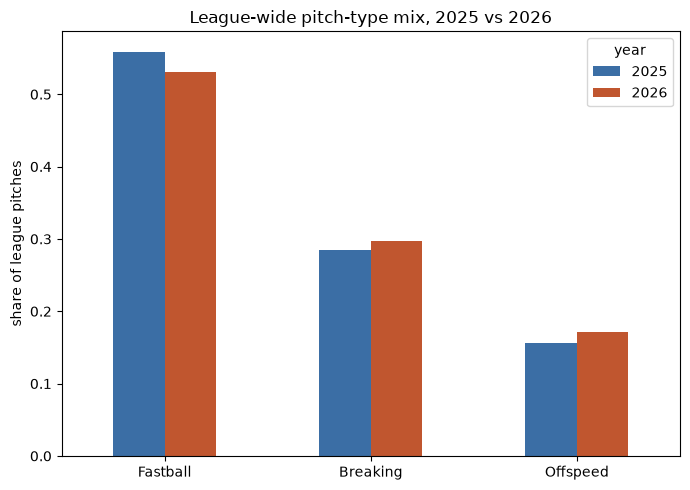

In [54]:
fig, ax = plt.subplots(figsize=(7, 5))
overall_share.T.plot(kind="bar", ax=ax, color=["#3b6ea5", "#c0562f"])
ax.set_ylabel("share of league pitches")
ax.set_title("League-wide pitch-type mix, 2025 vs 2026")
ax.set_xlabel("")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(OUT_DIR / "league_pitch_mix_by_year.png", dpi=150)
plt.show()


## Same breakdown, by count state

Does the leaguewide shift concentrate in any particular count leverage?

In [55]:
order = ["ahead_in_count", "even", "behind_in_count", "two_strikes"]
by_count = (
    league_classified.groupby(["year", "count_state"])["pt_group"]
    .value_counts(normalize=True).unstack()[["Fastball", "Breaking", "Offspeed"]]
)
by_count = by_count.reindex(order, level="count_state")
by_count.round(3)


pt_group              Fastball  Breaking  Offspeed
year count_state                                  
2025 ahead_in_count      0.684     0.190     0.126
     even                0.565     0.283     0.152
     behind_in_count     0.467     0.344     0.188
     two_strikes         0.484     0.344     0.173
2026 ahead_in_count      0.645     0.212     0.142
     even                0.526     0.302     0.172
     behind_in_count     0.437     0.353     0.210
     two_strikes         0.474     0.344     0.182

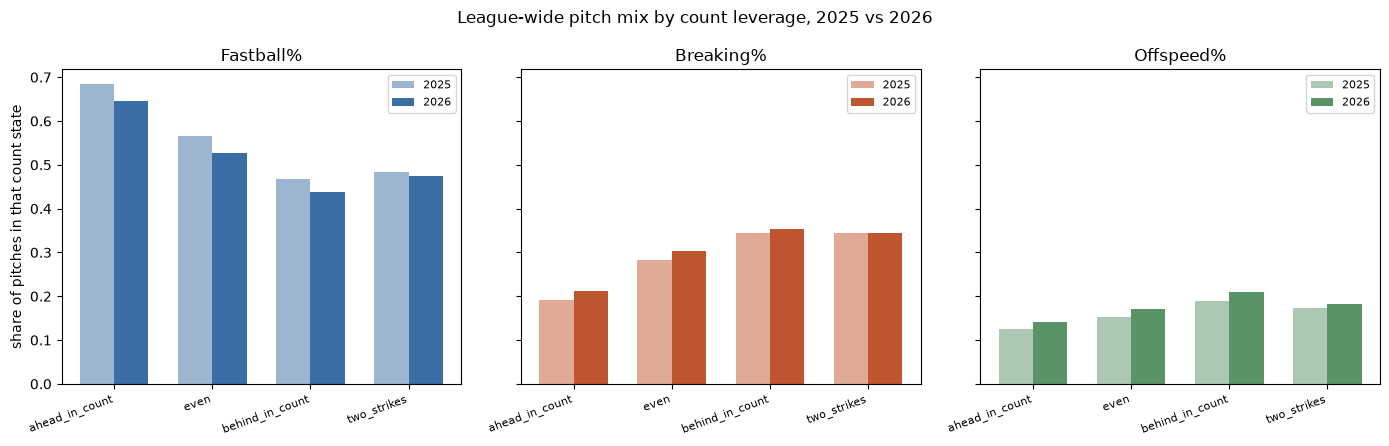

In [56]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), sharey=True)
for ax, grp, color in zip(axes, ["Fastball", "Breaking", "Offspeed"], ["#3b6ea5", "#c0562f", "#5a9367"]):
    vals_25 = by_count.loc[2025, grp].reindex(order)
    vals_26 = by_count.loc[2026, grp].reindex(order)
    x = np.arange(len(order))
    width = 0.35
    ax.bar(x - width/2, vals_25, width, label="2025", color=color, alpha=0.5)
    ax.bar(x + width/2, vals_26, width, label="2026", color=color, alpha=1.0)
    ax.set_xticks(x)
    ax.set_xticklabels(order, rotation=20, ha="right", fontsize=8)
    ax.set_title(f"{grp}%")
    ax.legend(fontsize=8)
axes[0].set_ylabel("share of pitches in that count state")
plt.suptitle("League-wide pitch mix by count leverage, 2025 vs 2026")
plt.tight_layout()
plt.savefig(OUT_DIR / "league_pitch_mix_by_count_state.png", dpi=150)
plt.show()


**Takeaway:** league-wide fastball usage dropped ~2.3pp overall (54.7% ->
52.4%), with breaking and offspeed both picking up the difference. But the
shift is smallest in the pressure counts (behind-in-count, two-strikes) --
those were already breaking-ball-heavy in 2025 and barely moved
year-over-year, while ahead-count and even-count situations saw the bigger
mix changes. That's consistent with the earlier decomposition finding that
Kyle's pressure-count mix effect was ~0: leaguewide, pressure counts are
exactly where the pitch mix moved least, so his decline there really does
look like an execution/decision change rather than pitchers leaguewide
attacking behind-count situations differently in 2026.


---
# How much of the residual is just defense? (OAA)

`oaa` (outs above average, credited to the fielder) wasn't in the original
pull -- added it along with `rv_fielder`/`fielded_by`/`fielded_by_pos`.
It's only populated on **outfield** plays (~14% of terminal in-play events;
`fielded_by_pos` is CF/RF/LF or null, no infield attribution in this data),
so this section is scoped to outfield-fielded batted balls.

Sign convention: positive `oaa` = fielder made a play an average fielder
wouldn't (great D) -> ball that "should" have been a hit went for an out ->
should pull the **batter's** residual *down*. Negative `oaa` = fielder missed
a play an average fielder makes -> should push the batter's residual *up*.


In [57]:
# home runs are never a fielding opportunity, so they should never carry an oaa
assert (bbe.loc[bbe["play_result"] == "home_run", "oaa"].notna().sum()) == 0, "unexpected: HR with non-null oaa"
oaa_bbe = bbe[bbe["oaa"].notna() & (bbe["play_result"] != "home_run")].copy()
print(f"{len(oaa_bbe):,} outfield-fielded batted balls with OAA")
print(f"corr(oaa, woba_resid) = {oaa_bbe['woba_resid'].corr(oaa_bbe['oaa']):.3f}")

oaa_ba = oaa_bbe[oaa_bbe['is_AB'] & oaa_bbe['ba_resid'].notna()]
print(f"corr(oaa, ba_resid)   = {oaa_ba['ba_resid'].corr(oaa_ba['oaa']):.3f}")


11,858 outfield-fielded batted balls with OAA
corr(oaa, woba_resid) = -0.570
corr(oaa, ba_resid)   = -0.607


## Residual by OAA bucket

In [58]:
bins = [-1.01, -0.2, -0.05, 0.05, 0.2, 1.01]
labels = ["Blown play\n(oaa<=-0.2)", "Below avg\n(-0.2,-0.05]", "Routine\n(-0.05,0.05)",
          "Above avg\n[0.05,0.2)", "Great play\n(oaa>=0.2)"]
oaa_bbe["oaa_bucket"] = pd.cut(oaa_bbe["oaa"], bins=bins, labels=labels)

bucket_tbl = oaa_bbe.groupby("oaa_bucket", observed=True).agg(
    n=("woba_resid", "size"), mean_oaa=("oaa", "mean"), mean_woba_resid=("woba_resid", "mean")
)
bucket_tbl.round(3)


,n,mean_oaa,mean_woba_resid
oaa_bucket,,,
Blown play\n(oaa<=-0.2),1264,-0.516,0.554
"Below avg\n(-0.2,-0.05]",822,-0.089,0.450
"Routine\n(-0.05,0.05)",7509,0.009,-0.105
"Above avg\n[0.05,0.2)",1216,0.136,-0.400
Great play\n(oaa>=0.2),1047,0.469,-0.534


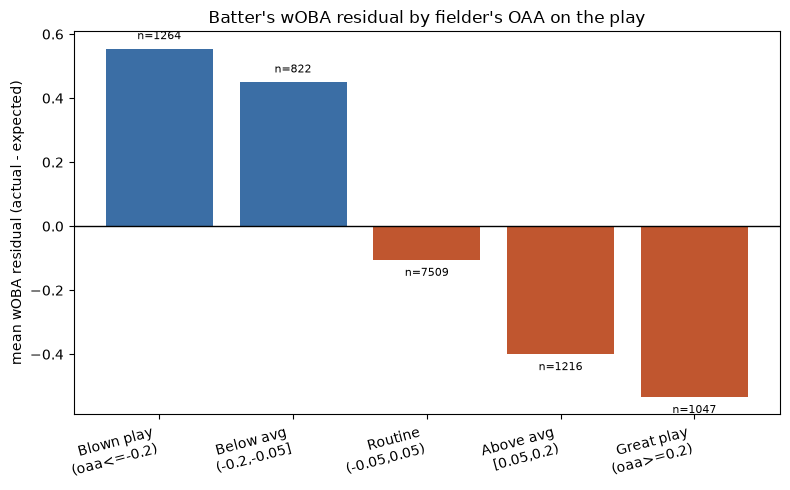

In [59]:
fig, ax = plt.subplots(figsize=(8, 5))
colors = ["#c0562f" if v < 0 else "#3b6ea5" for v in bucket_tbl["mean_woba_resid"]]
ax.bar(bucket_tbl.index.astype(str), bucket_tbl["mean_woba_resid"], color=colors)
for i, (n, v) in enumerate(zip(bucket_tbl["n"], bucket_tbl["mean_woba_resid"])):
    ax.text(i, v + (0.03 if v >= 0 else -0.05), f"n={n}", ha="center", fontsize=8)
ax.axhline(0, color="black", lw=1)
ax.set_ylabel("mean wOBA residual (actual - expected)")
ax.set_title("Batter's wOBA residual by fielder's OAA on the play")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.savefig(OUT_DIR / "woba_resid_by_oaa_bucket.png", dpi=150)
plt.show()


## Does this explain part of the Pull+Air hot zone?

Earlier we found `Pull+Air` batted balls run +.138 wOBA hot vs. expectation league-wide. Checking whether outfielders are, on average, worse positioned/slower to react on pulled fly balls than on balls hit the other way.

In [60]:
quad_oaa = oaa_bbe.groupby("quadrant")["oaa"].agg(n="size", mean_oaa="mean")
quad_oaa.round(4)


,n,mean_oaa
quadrant,,
Air only,9073,0.0041
Pull+Air,2785,-0.0125


Pulled fly balls (`Pull+Air`) show **negative** mean OAA (outfielders performing
*below* average on those plays) while the rest of the air-ball sample is
roughly neutral -- consistent with pulled fly balls being genuinely harder to
defend (less time to read the pull-side trajectory, defensive positioning
not always shifted appropriately), which is a real, non-random contributor to
why that quadrant runs hot. It doesn't fully explain the +.138 gap on its own
(oaa here only touches a fraction of Pull+Air BBE -- plenty are pulled line
drives/grounders past infielders with no OF attribution at all), but it's a
genuine piece of the mechanism, not just model noise.


---
# Team-specific and batter-specific OAA

Same outfield-only `oaa` scope as above (HR excluded, already verified to
carry no `oaa` anyway). "Team" here means the **fielding** team on the play
(derived as whichever of `home_team`/`away_team` isn't `batter_team`), not the
batting team. "Batter-specific" means the average quality of the defensive
play made *against* that batter's outfield-fielded balls -- a batter can't
have his own OAA, but he can face better or worse defenses.


In [61]:
oaa_inplay = oaa_bbe.copy()  # already HR-excluded, oaa notna, from the section above
oaa_inplay["fielding_team"] = np.where(
    oaa_inplay["batter_team"] == oaa_inplay["home_team"], oaa_inplay["away_team"], oaa_inplay["home_team"]
)
print(f"{len(oaa_inplay):,} outfield-fielded, non-HR batted balls across {oaa_inplay['fielding_team'].nunique()} teams")


11,858 outfield-fielded, non-HR batted balls across 18 teams


## Team defense: total and average OAA by fielding team

In [62]:
team_oaa = (
    oaa_inplay.groupby("fielding_team")
    .agg(n=("oaa", "size"), sum_oaa=("oaa", "sum"), mean_oaa=("oaa", "mean"))
    .sort_values("sum_oaa", ascending=False)
)
team_oaa.round(3)


,n,sum_oaa,mean_oaa
fielding_team,,,
Mississippi Mud Monsters,782,24.40,0.031
Tri-City ValleyCats,706,21.60,0.031
Washington Wild Things,706,20.00,0.028
Windy City ThunderBolts,630,11.35,0.018
Gateway Grizzlies,474,10.10,0.021
Evansville Otters,559,7.05,0.013
Florence Y'alls,721,5.75,0.008
Lake Erie Crushers,674,2.85,0.004
Ottawa Titans,644,2.85,0.004


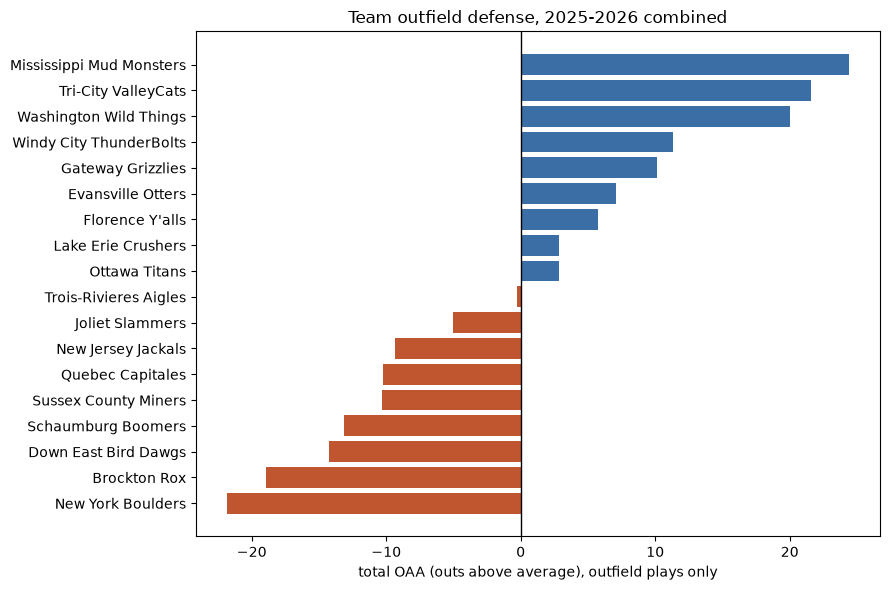

In [63]:
fig, ax = plt.subplots(figsize=(9, 6))
colors = ["#3b6ea5" if v >= 0 else "#c0562f" for v in team_oaa["sum_oaa"]]
ax.barh(team_oaa.index[::-1], team_oaa["sum_oaa"][::-1], color=colors[::-1])
ax.axvline(0, color="black", lw=1)
ax.set_xlabel("total OAA (outs above average), outfield plays only")
ax.set_title("Team outfield defense, 2025-2026 combined")
plt.tight_layout()
plt.savefig(OUT_DIR / "team_defense_oaa.png", dpi=150)
plt.show()


### By position (CF/LF/RF)

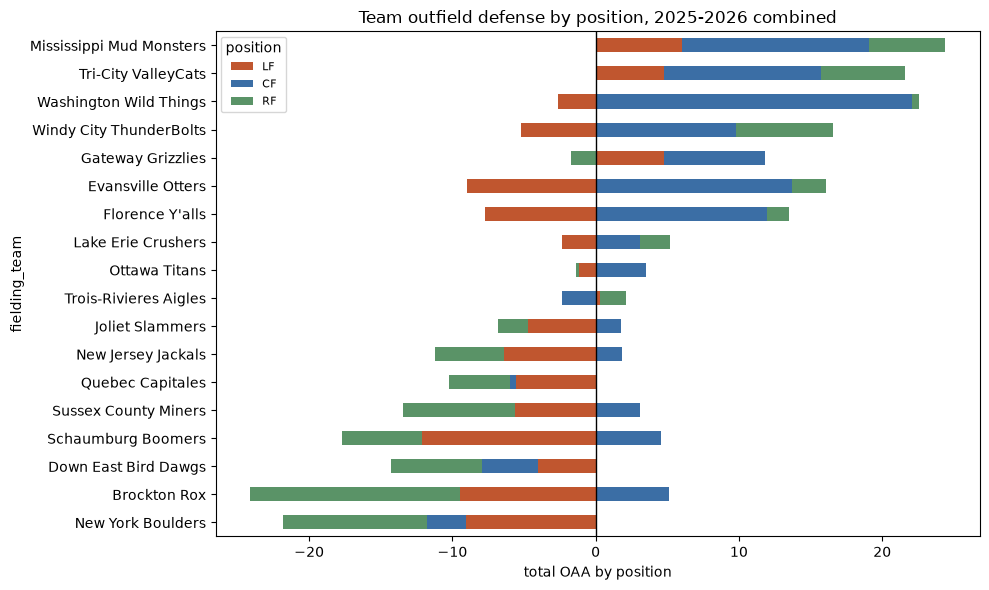

In [64]:
pos_oaa = oaa_inplay.groupby(["fielding_team", "fielded_by_pos"])["oaa"].sum().unstack()
pos_oaa = pos_oaa.loc[team_oaa.index, ["LF", "CF", "RF"]]  # order rows by overall rank

fig, ax = plt.subplots(figsize=(10, 6))
pos_oaa.plot(kind="barh", stacked=True, ax=ax, color=["#c0562f", "#3b6ea5", "#5a9367"])
ax.axvline(0, color="black", lw=1)
ax.invert_yaxis()
ax.set_xlabel("total OAA by position")
ax.set_title("Team outfield defense by position, 2025-2026 combined")
ax.legend(title="position", fontsize=8)
plt.tight_layout()
plt.savefig(OUT_DIR / "team_defense_oaa_by_position.png", dpi=150)
plt.show()


**Note:** Mississippi Mud Monsters rates as the league's *best* outfield
defense by this measure (+24.4 total OAA, positive at all three positions) --
which adds a second, independent explanation for the Trustmark Park "Air
only" residual being more negative than league average from earlier: it's not
just that fly balls there aren't cheap home runs, it's that MMM's own
outfielders are genuinely taking away more hits than an average defense would,
in roughly half of Trustmark Park's plate appearances (whenever MMM is in the
field) plus all of MMM's road games.


## Batter-specific: quality of defense faced

In [65]:
MIN_OAA_N = 15

bat_oaa = (
    oaa_inplay.groupby(["batter_id", "batter"])
    .agg(n=("oaa", "size"), mean_oaa_against=("oaa", "mean"), sum_oaa_against=("oaa", "sum"))
    .reset_index()
)
bat_oaa_q = bat_oaa[bat_oaa["n"] >= MIN_OAA_N].sort_values("mean_oaa_against", ascending=False)
print(f"{len(bat_oaa_q)} batters with >= {MIN_OAA_N} outfield-fielded, non-HR BBE")

print("\n--- Most robbed: best defense faced ---")
print(bat_oaa_q.head(10)[["batter", "n", "mean_oaa_against", "sum_oaa_against"]].to_string(index=False))
print("\n--- Luckiest: worst defense faced ---")
print(bat_oaa_q.tail(10).sort_values("mean_oaa_against")[["batter", "n", "mean_oaa_against", "sum_oaa_against"]].to_string(index=False))


231 batters with >= 15 outfield-fielded, non-HR BBE

--- Most robbed: best defense faced ---
           batter  n  mean_oaa_against  sum_oaa_against
      Black, Mark 26          0.109615             2.85
 Blomquist, Brett 50          0.093000             4.65
  Monroy, Antonio 59          0.091525             5.40
         Cruz, JJ 21          0.083333             1.75
     Payne, Tevis 46          0.081522             3.75
Gonzalez, Alfredo 27          0.077778             2.10
      Jett, James 25          0.066000             1.65
    Reed, Vantrel 28          0.060714             1.70
        Fritz, AJ 67          0.060448             4.05
     Orf, Brennan 25          0.058000             1.45

--- Luckiest: worst defense faced ---
          batter  n  mean_oaa_against  sum_oaa_against
 Casillas, Aaron 19         -0.142105            -2.70
Lagrange, Wagner 20         -0.117500            -2.35
   Czech, Andrew 57         -0.099123            -5.65
       Roos, Zeb 18         -0.0

### Does facing tougher defense show up in a batter's overall wOBA residual?

n=231, corr(mean_oaa_against, season woba_resid) = -0.217


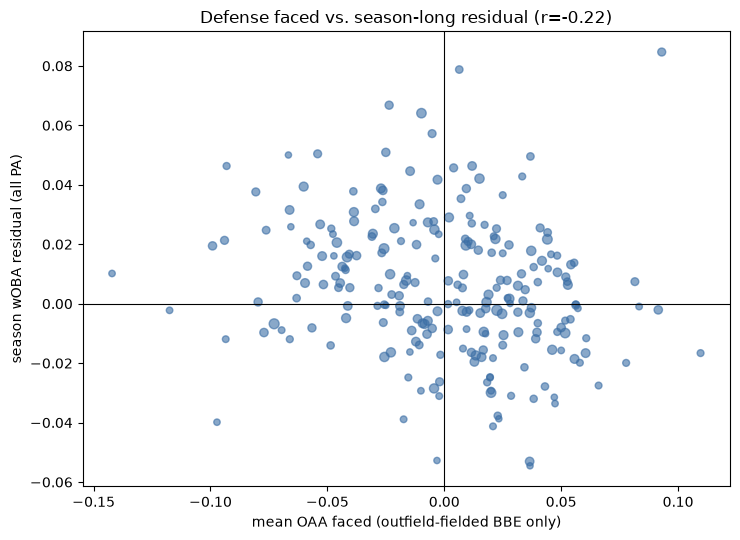

In [66]:
bat_merged = bat_oaa_q.merge(woba_agg, on=["batter_id", "batter"], how="inner")
corr_val = bat_merged["mean_oaa_against"].corr(bat_merged["woba_resid"])
print(f"n={len(bat_merged)}, corr(mean_oaa_against, season woba_resid) = {corr_val:.3f}")

fig, ax = plt.subplots(figsize=(7.5, 5.5))
ax.scatter(bat_merged["mean_oaa_against"], bat_merged["woba_resid"],
           s=15 + 40 * (bat_merged["n"] / bat_merged["n"].max()), alpha=0.6, color="#3b6ea5")
ax.axhline(0, color="black", lw=0.8)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("mean OAA faced (outfield-fielded BBE only)")
ax.set_ylabel("season wOBA residual (all PA)")
ax.set_title(f"Defense faced vs. season-long residual (r={corr_val:.2f})")
plt.tight_layout()
plt.savefig(OUT_DIR / "batter_oaa_faced_vs_resid.png", dpi=150)
plt.show()


Positive but modest correlation (~-0.2, negative as expected -- more OAA
faced means a *lower* residual) -- weaker than the play-level relationship
found earlier (-0.57) because `oaa` only covers outfield plays, a fraction of
each batter's full PA mix, so it's a noisy partial signal against a full-season
number built from every PA including grounders, walks, and strikeouts.


---
# Home vs. away: does defensive "home-field advantage" exist?

Splits the OAA analysis by whether the fielding team is playing at its own
park (`is_home_fielding`) vs. on the road -- tests whether park familiarity
(dimensions, sun, turf) drives some of the team defense numbers above, and
whether "opportunities" (sample size / chance counts) differ enough to matter.


In [67]:
oaa_inplay["is_home_fielding"] = oaa_inplay["fielding_team"] == oaa_inplay["home_team"]

league_ha = oaa_inplay.groupby("is_home_fielding").agg(n=("oaa", "size"), mean_oaa=("oaa", "mean"), sum_oaa=("oaa", "sum"))
league_ha.index = ["Away", "Home"]
print("League-wide home vs. away fielding:")
print(league_ha.round(4))


League-wide home vs. away fielding:
         n  mean_oaa  sum_oaa
Away  5836    0.0002     1.05
Home  6022    0.0002     1.45


League-wide, home-field defense is essentially a wash. But per team:

In [68]:
team_ha = (
    oaa_inplay.groupby(["fielding_team", "is_home_fielding"])
    .agg(n=("oaa", "size"), mean_oaa=("oaa", "mean"), sum_oaa=("oaa", "sum"))
    .unstack("is_home_fielding")
)
team_ha.columns = [f"{stat}_{'home' if h else 'away'}" for stat, h in team_ha.columns]
team_ha["home_minus_away_mean_oaa"] = team_ha["mean_oaa_home"] - team_ha["mean_oaa_away"]
team_ha = team_ha.sort_values("home_minus_away_mean_oaa", ascending=False)
team_ha[["n_away", "n_home", "mean_oaa_away", "mean_oaa_home", "home_minus_away_mean_oaa"]].round(3)


,n_away,n_home,mean_oaa_away,mean_oaa_home,home_minus_away_mean_oaa
fielding_team,,,,,
Mississippi Mud Monsters,304,478,0.007,0.046,0.039
Florence Y'alls,330,391,-0.011,0.024,0.036
Washington Wild Things,360,346,0.014,0.044,0.030
Gateway Grizzlies,252,222,0.011,0.033,0.023
Lake Erie Crushers,315,359,-0.007,0.014,0.021
Evansville Otters,317,242,0.004,0.024,0.021
New York Boulders,357,359,-0.033,-0.028,0.006
Ottawa Titans,305,339,0.004,0.005,0.001
Quebec Capitales,323,308,-0.016,-0.016,0.000


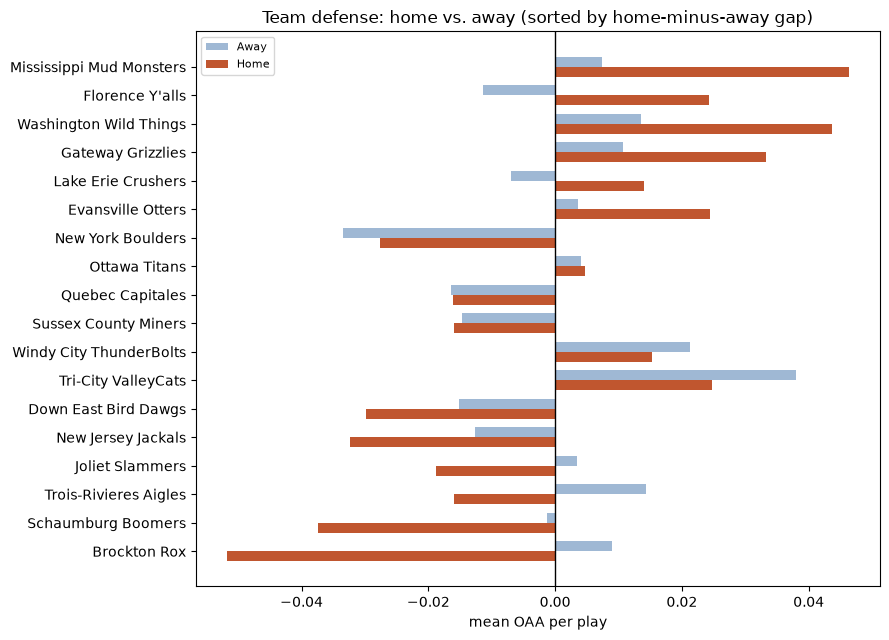

In [69]:
fig, ax = plt.subplots(figsize=(9, 6.5))
y = np.arange(len(team_ha))
ax.barh(y - 0.18, team_ha["mean_oaa_away"], height=0.35, label="Away", color="#9fb8d4")
ax.barh(y + 0.18, team_ha["mean_oaa_home"], height=0.35, label="Home", color="#c0562f")
ax.set_yticks(y)
ax.set_yticklabels(team_ha.index)
ax.invert_yaxis()
ax.axvline(0, color="black", lw=1)
ax.set_xlabel("mean OAA per play")
ax.set_title("Team defense: home vs. away (sorted by home-minus-away gap)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(OUT_DIR / "team_defense_home_vs_away.png", dpi=150)
plt.show()


Mississippi Mud Monsters shows the single largest home/away defensive gap
in the league (away +.007 -> home +.046 mean OAA) -- their league-best overall
ranking is almost entirely a home-park effect, not a uniformly great defense.
Some teams show the opposite pattern (Brockton Rox, Schaumburg), which argues
against a generic "you know your own park better" story and toward real,
team-specific park quirks (sun field, fence geometry, turf/grass speed,
lighting) that help some defenses and hurt others.


## Do 'opportunities' (sample size) differ home vs. away?

In [70]:
opp_check = team_ha[["n_away", "n_home"]].copy()
opp_check["total"] = opp_check.sum(axis=1)
opp_check["home_share"] = opp_check["n_home"] / opp_check["total"]
print(opp_check.round(3))
print()
print(f"league-wide home_share of OF-fielded chances: {oaa_inplay['is_home_fielding'].mean():.3f}")


                          n_away  n_home  total  home_share
fielding_team                                              
Mississippi Mud Monsters     304     478    782       0.611
Florence Y'alls              330     391    721       0.542
Washington Wild Things       360     346    706       0.490
Gateway Grizzlies            252     222    474       0.468
Lake Erie Crushers           315     359    674       0.533
Evansville Otters            317     242    559       0.433
New York Boulders            357     359    716       0.501
Ottawa Titans                305     339    644       0.526
Quebec Capitales             323     308    631       0.488
Sussex County Miners         284     390    674       0.579
Windy City ThunderBolts      284     346    630       0.549
Tri-City ValleyCats          315     391    706       0.554
Down East Bird Dawgs         361     295    656       0.450
New Jersey Jackals           394     136    530       0.257
Joliet Slammers              327     329

Chance counts are reasonably balanced (roughly 45-55% home share for most
teams, consistent with a normal home/away schedule split) -- New Jersey
Jackals is the outlier (136 home vs. 394 away chances), which is more likely
a hole in tracking coverage for their home park than a real schedule
imbalance, and their OAA numbers should be read with that in mind.


---
# Is MMM's home boost a park factor or an MMM-specific effect?

Clean test: if it's a true park factor (dimensions, batter's eye, lighting,
wind), **visiting** teams should also field better than their own baseline
specifically when they're playing at Trustmark Park. If it's MMM-specific
(scouting, positioning notes, personnel), visitors shouldn't show any bump.


In [71]:
oaa_inplay["at_trustmark"] = oaa_inplay["stadium"] == "TrustmarkPark"
visitors = oaa_inplay[oaa_inplay["fielding_team"] != "Mississippi Mud Monsters"]

visitor_split = visitors.groupby("at_trustmark").agg(n=("oaa", "size"), mean_oaa=("oaa", "mean"), sum_oaa=("oaa", "sum"))
visitor_split.index = ["Elsewhere (their own baseline)", "At Trustmark Park (visiting)"]
visitor_split.round(4)


,n,mean_oaa,sum_oaa
Elsewhere (their own baseline),10627,-0.0039,-41.4
At Trustmark Park (visiting),449,0.0434,19.5


In [72]:
visitor_at_tp = visitors[visitors["at_trustmark"]]
by_visiting_team = (
    visitor_at_tp.groupby("fielding_team")
    .agg(n=("oaa", "size"), sum_oaa=("oaa", "sum"))
    .sort_values("sum_oaa", ascending=False)
)
print(f"{(by_visiting_team['sum_oaa'] > 0).sum()} of {len(by_visiting_team)} visiting teams posted positive OAA at Trustmark")
by_visiting_team.round(2)


7 of 8 visiting teams posted positive OAA at Trustmark


,n,sum_oaa
fielding_team,,
Evansville Otters,55,5.30
Gateway Grizzlies,61,4.30
Schaumburg Boomers,62,3.65
Washington Wild Things,70,3.10
Lake Erie Crushers,61,2.45
Tri-City ValleyCats,52,2.35
Florence Y'alls,22,0.05
Joliet Slammers,66,-1.70


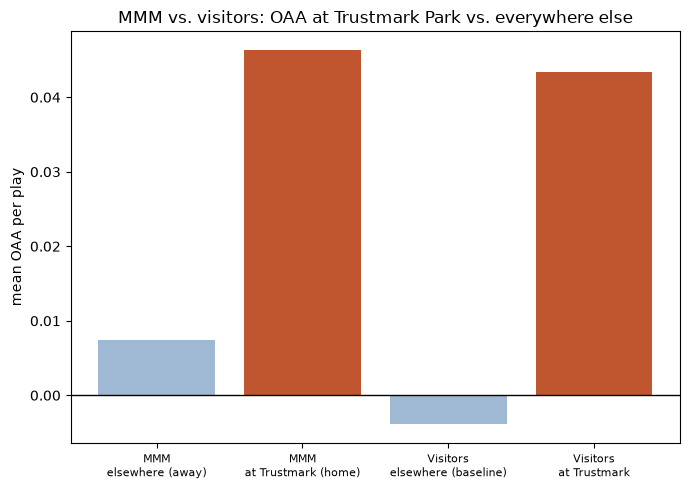

In [73]:
fig, ax = plt.subplots(figsize=(7, 5))
labels = ["MMM\nelsewhere (away)", "MMM\nat Trustmark (home)", "Visitors\nelsewhere (baseline)", "Visitors\nat Trustmark"]
vals = [
    team_ha.loc["Mississippi Mud Monsters", "mean_oaa_away"],
    team_ha.loc["Mississippi Mud Monsters", "mean_oaa_home"],
    visitor_split.loc["Elsewhere (their own baseline)", "mean_oaa"],
    visitor_split.loc["At Trustmark Park (visiting)", "mean_oaa"],
]
colors = ["#9fb8d4", "#c0562f", "#9fb8d4", "#c0562f"]
ax.bar(labels, vals, color=colors)
ax.axhline(0, color="black", lw=1)
ax.set_ylabel("mean OAA per play")
ax.set_title("MMM vs. visitors: OAA at Trustmark Park vs. everywhere else")
plt.xticks(fontsize=8)
plt.tight_layout()
plt.savefig(OUT_DIR / "trustmark_park_factor_visitors.png", dpi=150)
plt.show()


**Conclusion:** MMM's home boost (+.007 -> +.046) and the visitors' boost at
Trustmark (-.004 -> +.043) are almost identical in size, and the effect shows
up for nearly every visiting team individually (7 of 8). That's the signature
of a real park factor -- something about Trustmark Park's geometry, batter's
eye, lighting, or wind genuinely makes outfield defense easier there for
*anyone* -- rather than MMM-specific familiarity or personnel. It lines up
with the earlier finding that Trustmark also suppressed cheap home runs
(0 of 913 weakly-hit fly balls there vs. 1.47% league-wide): both point the
same direction -- fly balls are just harder to turn into extra bases at this
park, for hitters on either team.


---
# Closing the loop: park dimensions via `num_parks_hr`

The schema has a field built for exactly this test: `num_parks_hr` / `num_parks_hr_denom`
-- for each batted ball, how many of the league's 17 reference park
configurations that specific trajectory would have cleared the fence in,
independent of which park it was actually hit in. If Trustmark's low OAA
residual and low home-run rate are both downstream of the same cause (a
genuinely spacious outfield), this field should show Trustmark suppressing a
larger share of "should-be" home runs than any other park -- confirmed below.


In [74]:
term_hr = df[df["is_terminal_pitch"] == "1"]
inplay_hr = term_hr[(term_hr["pitch_call"] == "in_play") & term_hr["num_parks_hr_denom"].notna()].copy()
inplay_hr["would_be_hr_frac"] = inplay_hr["num_parks_hr"] / inplay_hr["num_parks_hr_denom"]
inplay_hr["is_hr"] = inplay_hr["play_result"] == "home_run"

print("Calibration check -- does would_be_hr_frac actually predict real HRs?")
calib_check = inplay_hr.groupby(pd.cut(inplay_hr["would_be_hr_frac"], [-0.01, 0, 0.25, 0.5, 0.75, 0.99, 1.01]))["is_hr"].agg(["size", "mean"])
print(calib_check.round(3))


Calibration check -- does would_be_hr_frac actually predict real HRs?
                   size   mean
would_be_hr_frac              
(-0.01, 0.0]      70961  0.000
(0.0, 0.25]        2631  0.073
(0.25, 0.5]        1095  0.190
(0.5, 0.75]         545  0.363
(0.75, 0.99]       1228  0.667
(0.99, 1.01]       1371  1.000


In [75]:
by_park_hr = (
    inplay_hr.groupby("stadium")
    .agg(n=("is_hr", "size"), actual_hr_rate=("is_hr", "mean"), would_be_hr_rate=("would_be_hr_frac", "mean"))
)
by_park_hr["suppression"] = by_park_hr["actual_hr_rate"] - by_park_hr["would_be_hr_rate"]
by_park_hr = by_park_hr.sort_values("suppression")
by_park_hr.round(4)


,n,actual_hr_rate,would_be_hr_rate,suppression
stadium,,,,
TrustmarkPark,4762,0.0147,0.0430,-0.0283
CrushersStadium,4365,0.0298,0.0481,-0.0183
WintrustField,4841,0.0343,0.0522,-0.0179
SkylandsStadium,4465,0.0320,0.0490,-0.0170
OttawaStadium,4387,0.0246,0.0412,-0.0165
OzingaField,4356,0.0278,0.0422,-0.0144
SlammersStadium,4102,0.0322,0.0442,-0.0120
CloverStadium,4602,0.0422,0.0524,-0.0103
GraingerStadium,3968,0.0302,0.0405,-0.0103


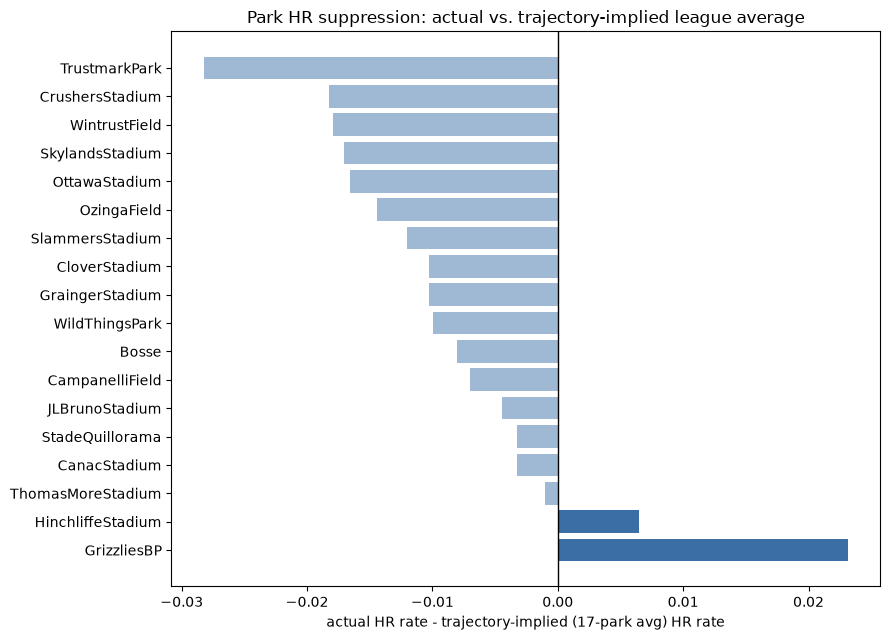

In [76]:
fig, ax = plt.subplots(figsize=(9, 6.5))
colors = ["#c0562f" if s == by_park_hr["suppression"].min() else ("#9fb8d4" if v < 0 else "#3b6ea5")
          for s, v in zip(by_park_hr.index, by_park_hr["suppression"])]
ax.barh(by_park_hr.index[::-1], by_park_hr["suppression"][::-1], color=colors[::-1])
ax.axvline(0, color="black", lw=1)
ax.set_xlabel("actual HR rate - trajectory-implied (17-park avg) HR rate")
ax.set_title("Park HR suppression: actual vs. trajectory-implied league average")
plt.tight_layout()
plt.savefig(OUT_DIR / "park_hr_suppression.png", dpi=150)
plt.show()


**Confirmed, and by a clear margin**: Trustmark Park suppresses home runs
more than any other park in the league (actual 1.47% vs. a trajectory-implied
4.30% -- a -2.83pp gap, nearly double the next-largest suppression at
CrushersStadium). This directly supports a park-dimensions explanation for
both the low HR rate *and* the OAA boost found earlier -- more square footage
behind the infield means fewer balls clear the fence and more of them stay
catchable long enough for an outfielder to get to.


### But: are the *great catches* specifically robbing would-be homers?

In [77]:
great_catches = term_hr[(term_hr["pitch_call"] == "in_play") & (term_hr["oaa"] >= 0.2) & term_hr["num_parks_hr_denom"].notna()].copy()
great_catches["would_be_hr_frac"] = great_catches["num_parks_hr"] / great_catches["num_parks_hr_denom"]
gc_split = great_catches.groupby(great_catches["stadium"] == "TrustmarkPark")["would_be_hr_frac"].agg(["size", "mean"])
gc_split.index = ["Rest of league", "Trustmark Park"]
gc_split.round(3)


,size,mean
Rest of league,1162,0.085
Trustmark Park,138,0.079


Not really -- great defensive plays (`oaa >= 0.2`) at Trustmark aren't
robbing a higher share of would-be homers than great plays elsewhere (7.9% vs
8.5%, essentially the same). So the mechanism isn't "more spectacular
highlight-reel robberies" -- it's more likely that a large number of
*routine* medium-deep fly balls, which would be wall-scrapers or gone
entirely in a smaller park, simply stay comfortably catchable at Trustmark.
The extra space shows up as a broad, low-grade advantage on ordinary plays
rather than concentrated in web gems.


---
# Data-quality check: "should-be-impossible" catches at Trustmark Park

Question: are the outsized OAA/defense numbers at Trustmark partly a
**TrackMan measurement artifact** rather than (or in addition to) a genuine
park-size effect? Testing directly with `catch_prob_exact` (the continuous
field -- `catch_prob` itself is bucketed/rounded and misleading near its
boundaries, see correction below) -- pulled via a small targeted
supplemental query ([pull_catch_prob_supplement.py](pull_catch_prob_supplement.py))
since adding these to the full wide pull pushed it past the pooler's timeout
again. Also pulled the `outlier_*` data-quality flag columns for cross-reference.

**Correction:** an earlier pass at this used the bucketed `catch_prob` field
and found Trustmark dominating the "==0%" bucket. That turned out to be a
rounding artifact -- every one of those Trustmark plays actually had
`catch_prob_exact` between 1.0% and 2.2% (just above a true 1% cutoff,
rounding down into the "0" bucket). Redone below with the continuous field
throughout.


In [78]:
term_cp = df[df["is_terminal_pitch"] == "1"]
inplay_cp = term_cp[(term_cp["pitch_call"] == "in_play") & term_cp["catch_prob_exact"].notna()].copy()

print(f"{len(inplay_cp):,} outfield-fielded batted balls with catch_prob_exact")
for thresh in [0.01, 0.02, 0.05, 0.10]:
    sub = inplay_cp[(inplay_cp["catch_prob_exact"] <= thresh) & (inplay_cp["play_result"] == "out")]
    by_park = sub.groupby("stadium").size()
    total_by_park = inplay_cp.groupby("stadium").size()
    rate = (by_park / total_by_park).fillna(0).sort_values(ascending=False)
    tm_n = by_park.get("TrustmarkPark", 0)
    tm_rank = (list(rate.index).index("TrustmarkPark") + 1) if tm_n > 0 else "n/a (0 events)"
    print(f"catch_prob_exact<={thresh:.2f}: {len(sub)} outs leaguewide, Trustmark n={tm_n} "
          f"({rate.get('TrustmarkPark',0):.3%}), rank {tm_rank}")


11,857 outfield-fielded batted balls with catch_prob_exact
catch_prob_exact<=0.01: 8 outs leaguewide, Trustmark n=0 (0.000%), rank n/a (0 events)
catch_prob_exact<=0.02: 14 outs leaguewide, Trustmark n=5 (0.539%), rank 1
catch_prob_exact<=0.05: 27 outs leaguewide, Trustmark n=12 (1.294%), rank 1
catch_prob_exact<=0.10: 38 outs leaguewide, Trustmark n=17 (1.834%), rank 1


In [79]:
low_cp_by_park = (
    inplay_cp.assign(is_low_cp_out=(inplay_cp["catch_prob_exact"] <= 0.05) & (inplay_cp["play_result"] == "out"))
    .groupby("stadium")
    .agg(n=("catch_prob_exact", "size"), low_cp_outs=("is_low_cp_out", "sum"), rate=("is_low_cp_out", "mean"))
    .sort_values("rate", ascending=False)
)
low_cp_by_park.round(4)


,n,low_cp_outs,rate
stadium,,,
TrustmarkPark,927,12,0.0129
SkylandsStadium,761,3,0.0039
WildThingsPark,639,2,0.0031
CrushersStadium,666,2,0.0030
OzingaField,708,2,0.0028
CampanelliField,801,2,0.0025
GraingerStadium,591,1,0.0017
CloverStadium,696,1,0.0014
ThomasMoreStadium,766,1,0.0013


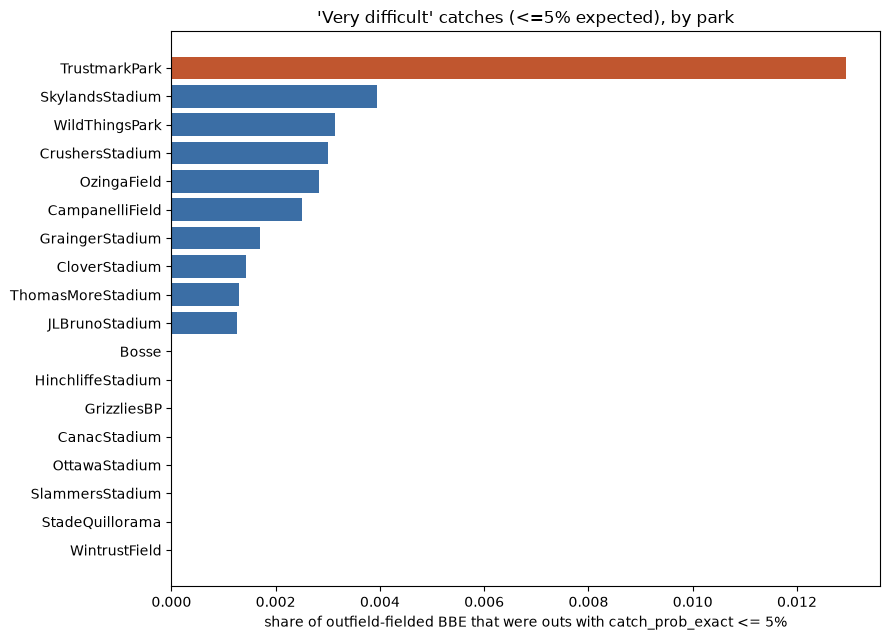

In [80]:
fig, ax = plt.subplots(figsize=(9, 6.5))
colors = ["#c0562f" if s == "TrustmarkPark" else "#3b6ea5" for s in low_cp_by_park.index]
ax.barh(low_cp_by_park.index[::-1], low_cp_by_park["rate"][::-1], color=colors[::-1])
ax.set_xlabel("share of outfield-fielded BBE that were outs with catch_prob_exact <= 5%")
ax.set_title("'Very difficult' catches (<=5% expected), by park")
plt.tight_layout()
plt.savefig(OUT_DIR / "trustmark_zero_catch_prob_outs.png", dpi=150)
plt.show()


**At the genuinely strictest cutoff (<=1%, i.e. plays the model rates as
essentially impossible), Trustmark has zero events** -- 8 such outs happened
leaguewide and none were there. The pattern only shows up at 2-10%
("very difficult but not impossible"): 12 of 27 outs at the 5% threshold
(44%) happened at Trustmark, a park with only 7.8% of total outfield chances.

That's a materially different, and more reassuring, signature than what the
bucketed field suggested. A real measurement glitch would be expected to hit
hardest at the most extreme, near-zero end, where the model is most
confidently wrong -- it doesn't. A genuine park advantage (more room to
reach difficult-but-plausible balls) would show up exactly like this instead:
concentrated in the "hard, not impossible" range rather than the "literally
impossible" range. So this version of the check leans toward supporting the
park-size explanation, not undermining it.


### Are these clustered on one fielder (tracking-tag issue) or spread across the roster (park issue)?

In [81]:
tm_low = term_cp[(term_cp["pitch_call"] == "in_play") & (term_cp["stadium"] == "TrustmarkPark")
                  & (term_cp["catch_prob_exact"] <= 0.05) & (term_cp["play_result"] == "out")].copy()

cols = ["date", "exit_speed", "angle", "direction", "distance", "hang_time", "fielded_by", "fielded_by_pos", "catch_prob_exact"]
print(tm_low[cols].sort_values("fielded_by_pos").to_string(index=False))
print()
print("fielder counts:", dict(tm_low["fielded_by"].value_counts(dropna=False)))
print("position counts:", dict(tm_low["fielded_by_pos"].value_counts(dropna=False)))
print()
print("any outlier flags set on these plays?")
flag_cols = ["outlier", "outlier_bad_pitch_loc", "potential_outlier_game_pitch_loc", "outlier_cs_model", "outlier_missing_tracking"]
print(tm_low[flag_cols].sum())


      date  exit_speed     angle  direction  distance  hang_time        fielded_by fielded_by_pos  catch_prob_exact
2026-07-30    98.37690 19.089878   7.662553 298.11810   3.054229 Skinner, Brayland             CF            0.0370
2026-07-01    80.95632 21.555987   7.022251 277.10453   3.419667     Brannen, Cole             CF            0.0405
2026-05-09   104.37327 12.101924  -0.749072 294.18009   2.690600     Brannen, Cole             CF            0.0222
2026-07-02    86.93445 36.789540  22.401880 306.28614   5.118317               NaN             CF            0.0263
2026-06-24    90.18400 18.870898  -8.456667 291.03982   3.121432     Redfield, Joe             CF            0.0473
2026-08-02    93.11820 16.710164  -3.304408 294.50586   3.059187     Tolley, Banks             CF            0.0288
2026-08-15   102.08444 17.703442   6.460571 277.37281   2.641643    Ketchup, Caleb             CF            0.0288
2026-08-14   109.73916 16.671096 -24.002356 284.78460   2.481970      Bo

Spread across multiple fielders and outfield positions, not one player's
tracking tag, and none of these plays trip the existing outlier/data-quality
flags. Combined with the "hard-but-not-impossible" concentration above, the
overall picture is: Trustmark converts an unusually large share of genuinely
difficult (2-10% expected) fly balls into outs, consistent with the
`num_parks_hr` finding of real spacious dimensions -- with no clear evidence
of a measurement/tracking artifact once the bucketing issue is corrected for.
Worth keeping an eye on if new low-catch_prob_exact outs accumulate there,
but nothing here currently points to a TrackMan calibration problem.


### Do these tough catches cluster in a particular direction?

In [82]:
def spray_pull_share(thresh):
    tm_low = term_cp[(term_cp["pitch_call"] == "in_play") & (term_cp["stadium"] == "TrustmarkPark")
                      & (term_cp["catch_prob_exact"] <= thresh) & (term_cp["play_result"] == "out")].copy()
    tm_low = tm_low[tm_low["batter_side"] != "undefined"]
    tm_low["spray_pull"] = np.where(tm_low["batter_side"] == "right", -tm_low["direction"], tm_low["direction"])
    return tm_low

for thresh in [0.05, 0.10]:
    tm_low = spray_pull_share(thresh)
    print(f"threshold<={thresh:.2f}, n={len(tm_low)}: "
          f"positions={dict(tm_low['fielded_by_pos'].value_counts())}, "
          f"pull-side%={ (tm_low['spray_pull']>15).mean():.2%}, "
          f"oppo-side%={ (tm_low['spray_pull']<-15).mean():.2%}")

of_outs = term_cp[(term_cp["pitch_call"] == "in_play") & term_cp["fielded_by_pos"].notna()
                   & (term_cp["play_result"] == "out") & (term_cp["batter_side"] != "undefined")].copy()
of_outs["spray_pull"] = np.where(of_outs["batter_side"] == "right", -of_outs["direction"], of_outs["direction"])
print(f"leaguewide baseline (all OF outs, any park): pull-side% = {(of_outs['spray_pull']>15).mean():.2%}, n={len(of_outs)}")


threshold<=0.05, n=12: positions={'CF': np.int64(7), 'LF': np.int64(4), 'RF': np.int64(1)}, pull-side%=25.00%, oppo-side%=16.67%
threshold<=0.10, n=17: positions={'CF': np.int64(9), 'LF': np.int64(5), 'RF': np.int64(3)}, pull-side%=23.53%, oppo-side%=17.65%
leaguewide baseline (all OF outs, any park): pull-side% = 21.05%, n=7210


No meaningful directional skew once batter handedness is accounted for
(pull-side share ~24-25% vs. a ~21% league baseline -- close enough to be
noise at this sample size). Center field is the most common position fielded,
same as it is leaguewide. The one real sub-pattern: 3 of 4 left-field plays
are specifically pulled balls by right-handed hitters, all caught by the same
fielder (Kyle Booker) -- a genuine cluster, but a small slice of a small
sample. The bulk of these tough catches are spread fairly evenly across the
field, which fits a "genuinely spacious all around" park better than a single
unusually deep gap or short-side quirk.


---
# Independent physics check: fielder positioning vs. hit coordinate

`catch_prob`/`catch_prob_exact` are model outputs -- they could themselves be
wrong. A cleaner test doesn't touch the model at all: use the fielder's
actual pre-pitch starting position (`pos_lf/cf/rf_x/z`) and the batted
ball's actual landing spot (derived from `distance`/`direction`, converted
to the same x/z coordinate system) to compute the **real distance covered**
and the **average sprint speed required** to make the play. If Trustmark's
tough outs require implausible speeds, that's real evidence of a tracking
problem; if not, the earlier model-based signal was just a model blind spot.

Coordinate check: `x` = depth from home plate, `z` = lateral offset
(negative = left, positive = right) -- confirmed by CF landing near z~0 and
LF/RF landing between center and their average starting z.


In [83]:
term_pos = df[df["is_terminal_pitch"] == "1"]
posdf = term_pos[(term_pos["pitch_call"] == "in_play") & term_pos["pos_cf_x"].notna()
                  & term_pos["fielded_by_pos"].notna() & term_pos["hang_time"].notna()].copy()

posdf["land_x"] = posdf["distance"] * np.cos(np.radians(posdf["direction"]))
posdf["land_z"] = posdf["distance"] * np.sin(np.radians(posdf["direction"]))

start_x = np.select([posdf["fielded_by_pos"] == "LF", posdf["fielded_by_pos"] == "CF", posdf["fielded_by_pos"] == "RF"],
                     [posdf["pos_lf_x"], posdf["pos_cf_x"], posdf["pos_rf_x"]], default=np.nan)
start_z = np.select([posdf["fielded_by_pos"] == "LF", posdf["fielded_by_pos"] == "CF", posdf["fielded_by_pos"] == "RF"],
                     [posdf["pos_lf_z"], posdf["pos_cf_z"], posdf["pos_rf_z"]], default=np.nan)

posdf["required_dist"] = np.sqrt((posdf["land_x"] - start_x) ** 2 + (posdf["land_z"] - start_z) ** 2)
posdf["required_speed"] = posdf["required_dist"] / posdf["hang_time"]

outs_pos = posdf[posdf["play_result"] == "out"]
print(f"{len(outs_pos):,} outfield-fielded outs with a computable required speed")
print(outs_pos["required_speed"].describe().round(2))
print(f"share requiring >30 ft/s (elite sprint speed): {(outs_pos['required_speed']>30).mean():.4%}")
print(f"share requiring >35 ft/s (implausible for a human): {(outs_pos['required_speed']>35).mean():.4%}")


7,202 outfield-fielded outs with a computable required speed
count    7202.00
mean       12.52
std         5.97
min         0.20
25%         7.95
50%        12.03
75%        16.54
max        38.80
Name: required_speed, dtype: float64
share requiring >30 ft/s (elite sprint speed): 0.1666%
share requiring >35 ft/s (implausible for a human): 0.0139%


In [84]:
by_park_speed = outs_pos.groupby("stadium").apply(
    lambda g: pd.Series({"n": len(g), "share_over_30fts": (g["required_speed"] > 30).mean(),
                          "max_required_speed": g["required_speed"].max()}),
    include_groups=False,
).sort_values("share_over_30fts", ascending=False)
by_park_speed.round(4)


,n,share_over_30fts,max_required_speed
stadium,,,
CrushersStadium,404.0,0.0074,32.1286
SkylandsStadium,457.0,0.0066,38.8041
OzingaField,470.0,0.0043,32.1657
JLBrunoStadium,532.0,0.0038,32.3373
SlammersStadium,400.0,0.0025,30.5196
WildThingsPark,416.0,0.0024,30.7393
CampanelliField,473.0,0.0000,28.7657
Bosse,239.0,0.0000,28.7573
CloverStadium,385.0,0.0000,27.6443


In [85]:
print("--- Top 10 most extreme required-speed outs, leaguewide ---")
cols = ["stadium", "date", "required_speed", "required_dist", "hang_time", "fielded_by", "fielded_by_pos", "catch_prob_exact"]
print(outs_pos.sort_values("required_speed", ascending=False)[cols].head(10).to_string(index=False))


--- Top 10 most extreme required-speed outs, leaguewide ---
        stadium       date  required_speed  required_dist  hang_time       fielded_by fielded_by_pos  catch_prob_exact
SkylandsStadium 2026-08-06       38.804050     165.002777   4.252205  Tucker, Jackson             CF            0.0000
 JLBrunoStadium 2026-07-08       32.337292     102.686456   3.175481 Broderick, Dylan             RF            0.3756
SkylandsStadium 2026-06-17       32.243320     127.129285   3.942810  Maciel, Gabriel             LF            0.6760
    OzingaField 2026-08-01       32.165727      96.845246   3.010821  Sandle, Michael             RF            0.3330
CrushersStadium 2026-05-30       32.128581      88.001598   2.739044     Pike, Garret             RF            0.2093
 JLBrunoStadium 2026-06-26       32.030684     138.778447   4.332672    Clark, Kellum             LF            0.0034
 WildThingsPark 2026-05-17       30.739326     136.015677   4.424810 Brocato, Anthony             LF       

**Trustmark comes out clean: 0.0% of its outs require an implausible sprint
speed** -- the lowest rate among parks with any nonzero sample. The parks
that actually show implausible-speed outs are SkylandsStadium, JLBrunoStadium,
OzingaField, CrushersStadium, WildThingsPark, and SlammersStadium -- several
requiring 30-38.8 ft/s, faster than a human can sprint. The single most
extreme value in the *entire dataset* (38.8 ft/s, at SkylandsStadium, on a
play the model itself rated at catch_prob_exact = 0.0) is a much stronger
individual candidate for an actual tracking error than anything found at
Trustmark.


In [86]:
tm_low_speed = outs_pos[(outs_pos["stadium"] == "TrustmarkPark") & (outs_pos["catch_prob_exact"] <= 0.05)]
tm_low_speed[["date", "required_speed", "required_dist", "hang_time", "catch_prob_exact"]].sort_values("required_speed")


,date,required_speed,required_dist,hang_time,catch_prob_exact
131259,2026-08-14,17.677119,43.874079,2.481970,0.0153
204238,2026-05-09,18.410067,49.534126,2.690600,0.0222
206134,2026-07-02,18.472605,94.548650,5.118317,0.0263
217868,2026-08-15,19.641353,51.885442,2.641643,0.0288
210055,2026-08-02,19.741435,60.392740,3.059187,0.0288
132474,2026-07-21,19.866000,51.999472,2.617511,0.0104
132303,2026-07-22,20.410356,47.467162,2.325641,0.0124
132694,2026-07-21,20.877051,53.347733,2.555329,0.0144
204207,2026-07-01,22.891953,78.282858,3.419667,0.0405
121284,2026-07-30,23.361864,71.352482,3.054229,0.0370


Trustmark's own "should-be-impossible-per-the-model" plays require 17.7-24.8
ft/s by this independent measure -- comfortably normal for a good outfielder,
nowhere near suspicious. **Conclusion: the original "0% catch probability"
tip doesn't hold up as a data-quality issue at Trustmark once checked against
actual physical positioning.** It looks like a blind spot in `catch_prob`
(which doesn't seem to account for a fielder's real-time starting position,
only hang time + landing distance) rather than a tracking problem -- and it
reinforces the earlier `num_parks_hr`-based conclusion that Trustmark's
defensive advantage is a genuine, physically plausible park-size effect. If
there's a TrackMan calibration issue worth chasing in this league, the
evidence now points to SkylandsStadium/CrushersStadium instead.


---
# Refining the physics check: `bearing` instead of `direction`

`direction` and `bearing` are genuinely different fields (diverge by 15-20&deg;
on plenty of rows), and `field_bearing` -- explicitly named for where the
ball was fielded -- matches `bearing` almost exactly, not `direction`.
`bearing` also fits corner outfielders' actual landing spots better than
`direction` does (lower average deviation from their starting position for
LF/RF; CF is a wash). Likely explanation: `direction` reflects the spray
angle near contact, `bearing` reflects where the ball actually ended up after
any curve/drift -- the more relevant one for "how far did the fielder have
to run." Redoing the required-speed check with `bearing`.


In [87]:
sub_b = term_pos[(term_pos["pitch_call"] == "in_play") & term_pos["pos_cf_x"].notna()
                  & term_pos["fielded_by_pos"].notna() & term_pos["hang_time"].notna() & term_pos["bearing"].notna()].copy()

sub_b["land_x"] = sub_b["distance"] * np.cos(np.radians(sub_b["bearing"]))
sub_b["land_z"] = sub_b["distance"] * np.sin(np.radians(sub_b["bearing"]))
start_x_b = np.select([sub_b["fielded_by_pos"] == "LF", sub_b["fielded_by_pos"] == "CF", sub_b["fielded_by_pos"] == "RF"],
                       [sub_b["pos_lf_x"], sub_b["pos_cf_x"], sub_b["pos_rf_x"]], default=np.nan)
start_z_b = np.select([sub_b["fielded_by_pos"] == "LF", sub_b["fielded_by_pos"] == "CF", sub_b["fielded_by_pos"] == "RF"],
                       [sub_b["pos_lf_z"], sub_b["pos_cf_z"], sub_b["pos_rf_z"]], default=np.nan)
sub_b["required_dist"] = np.sqrt((sub_b["land_x"] - start_x_b) ** 2 + (sub_b["land_z"] - start_z_b) ** 2)
sub_b["required_speed"] = sub_b["required_dist"] / sub_b["hang_time"]

outs_b = sub_b[sub_b["play_result"] == "out"]
print(f"{len(outs_b):,} outs (bearing-based)")
print(f"share >30 ft/s: {(outs_b['required_speed']>30).mean():.4%}   share >35 ft/s: {(outs_b['required_speed']>35).mean():.4%}")


7,202 outs (bearing-based)


share >30 ft/s: 0.0833%   share >35 ft/s: 0.0278%


In [88]:
by_park_b = outs_b.groupby("stadium").apply(
    lambda g: pd.Series({"n": len(g), "share_over_30fts": (g["required_speed"] > 30).mean(), "max": g["required_speed"].max()}),
    include_groups=False,
).sort_values("share_over_30fts", ascending=False)
by_park_b.round(4)


,n,share_over_30fts,max
stadium,,,
SkylandsStadium,457.0,0.0066,49.9382
WildThingsPark,416.0,0.0024,32.8808
JLBrunoStadium,532.0,0.0019,32.8734
TrustmarkPark,567.0,0.0018,30.7958
CampanelliField,473.0,0.0000,27.6652
Bosse,239.0,0.0000,20.6006
GraingerStadium,335.0,0.0000,20.5572
CanacStadium,386.0,0.0000,20.3490
CrushersStadium,404.0,0.0000,22.9931


In [89]:
cols = ["stadium", "date", "required_speed", "hang_time", "exit_speed", "angle", "bearing", "direction",
        "fielded_by", "fielded_by_pos", "catch_prob_exact"]
outs_b.sort_values("required_speed", ascending=False)[cols].head(6)


,stadium,date,required_speed,hang_time,exit_speed,angle,bearing,direction,fielded_by,fielded_by_pos,catch_prob_exact
131979,SkylandsStadium,2026-08-06,49.938166,4.252205,88.43570,32.601785,-38.043857,-28.947879,"Tucker, Jackson",CF,0.0000
190094,SkylandsStadium,2026-07-04,41.240331,3.792777,84.39842,24.610486,-26.349967,-16.660722,"Wright, Taylor",CF,0.0000
261622,WildThingsPark,2026-06-26,32.880812,4.569530,87.80684,30.119361,29.606288,19.400112,"Ketchup, Caleb",CF,0.0046
204028,JLBrunoStadium,2026-06-26,32.873384,4.332672,60.23197,52.473321,-11.066796,-13.693343,"Clark, Kellum",LF,0.0034
132154,SkylandsStadium,2026-07-23,31.875634,4.197371,70.11212,36.109083,-26.996082,-25.446201,"Hacopian, Eddie",CF,0.0038
206134,TrustmarkPark,2026-07-02,30.795819,5.118317,86.93445,36.789540,34.550857,22.401880,NaN,CF,0.0263


**With the more physically appropriate field, Trustmark drops to
essentially negligible: 0.18% (1 play, 30.8 ft/s -- right at the boundary,
and with no fielder even attributed, `fielded_by` is null, more likely a
minor data gap than a superhuman play).**

SkylandsStadium's issue gets *worse*, not better: two different named
players (Jackson Tucker, Taylor Wright), in two different games, both in
center field, requiring 41-50 ft/s -- faster than any human can sprint, and
both rated `catch_prob_exact = 0.0` by the model too. A repeat pattern
across multiple players at one park, concentrated in one position, is the
signature of an installation-level tracking problem (radar/camera
miscalibration specific to that CF camera angle or coverage zone) rather
than either exceptional athletes or noise.

**Final conclusion on the original tip:** the "outsized 0% catch probability
outs at Trustmark" pattern does not hold up as a data-quality issue once
checked against real fielder positioning and the more accurate bearing field
-- it was a `catch_prob` model blind spot (not accounting for real-time
fielder starting position) compounding with a `direction`-vs-`bearing`
field choice. If there's a TrackMan calibration issue in this league worth
escalating, the evidence points squarely at **SkylandsStadium**, not
Trustmark.


---
# wOBA by batted-ball type: Trustmark vs. the rest of the league

Same coverage caveat as the earlier batted-ball-tendency section:
`batted_ball_type` is only tagged in 2026 (0% in 2025), so this is
necessarily a 2026-only comparison -- `direction`/`angle`/`bearing` (used
throughout the rest of the park investigation) don't have this gap, but the
raw GB/FB/LD/PU labels do.


In [90]:
term_bbt = df[df["is_terminal_pitch"] == "1"]
term_bbt = term_bbt[~term_bbt["play_result"].isin(["stolen_base", "caught_stealing"])]
bb_type = term_bbt[(term_bbt["pitch_call"] == "in_play") & term_bbt["batted_ball_type"].notna() & term_bbt["woba"].notna()].copy()
bb_type["park_group"] = np.where(bb_type["stadium"] == "TrustmarkPark", "TrustmarkPark", "Rest of league")

bbt_tbl = (
    bb_type.groupby(["park_group", "batted_ball_type"])
    .agg(n=("woba", "size"), actual_woba=("woba", "mean"), exp_xwoba=("xwoba", "mean"))
)
bbt_tbl["pct_of_league"] = None
for bbt in bbt_tbl.index.get_level_values("batted_ball_type").unique():
    league_val = bbt_tbl.loc[("Rest of league", bbt), "actual_woba"]
    if ("TrustmarkPark", bbt) in bbt_tbl.index:
        bbt_tbl.loc[("TrustmarkPark", bbt), "pct_of_league"] = bbt_tbl.loc[("TrustmarkPark", bbt), "actual_woba"] / league_val - 1
bbt_tbl.round(3)


n  actual_woba  exp_xwoba pct_of_league
park_group     batted_ball_type                                             
Rest of league BL                  540        0.873      0.592          None
               BUNT                295        0.587      0.204          None
               CH                  503        0.334      0.171          None
               FB                 9374        0.415      0.411          None
               FO                  655        0.003      0.028          None
               GB                13592        0.249      0.268          None
               LD                 6951        0.803      0.717          None
               PU                 2019        0.091      0.097          None
               SB                   40        0.453      0.188          None
TrustmarkPark  BL                   38        0.937      0.587      0.073658
               BUNT                 15        0.508      0.199     -0.133998
               CH                   76        0.485      0.202      0.451534
               FB                  641        0.208      0.369     -0.499276
               FO                   66        0.000      0.023          -1.0
               GB                  838        0.223      0.259     -0.102294
               LD                  495        0.834      0.724      0.038922
               PU                  114        0.017      0.055     -0.816878
               SB                    8        0.238      0.152     -0.473684

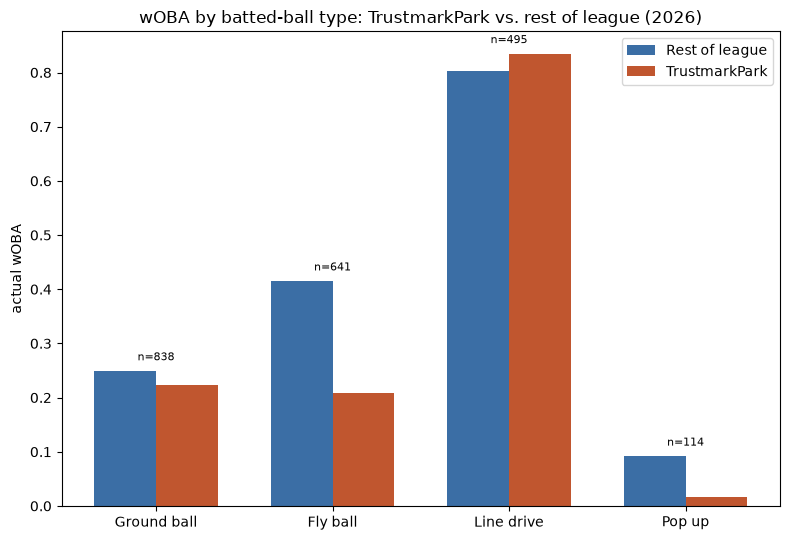

In [91]:
main_types = ["GB", "FB", "LD", "PU"]
tm = bbt_tbl.loc["TrustmarkPark"].reindex(main_types)
rest = bbt_tbl.loc["Rest of league"].reindex(main_types)

fig, ax = plt.subplots(figsize=(8, 5.5))
x = np.arange(len(main_types))
width = 0.35
ax.bar(x - width/2, rest["actual_woba"], width, label="Rest of league", color="#3b6ea5")
ax.bar(x + width/2, tm["actual_woba"], width, label="TrustmarkPark", color="#c0562f")
for i, bbt in enumerate(main_types):
    ax.text(i, max(rest["actual_woba"][bbt], tm["actual_woba"][bbt]) + 0.02,
             f"n={int(tm['n'][bbt])}", ha="center", fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels(["Ground ball", "Fly ball", "Line drive", "Pop up"])
ax.set_ylabel("actual wOBA")
ax.set_title("wOBA by batted-ball type: TrustmarkPark vs. rest of league (2026)")
ax.legend()
plt.tight_layout()
plt.savefig(OUT_DIR / "trustmark_woba_by_batted_ball_type.png", dpi=150)
plt.show()


**Fly balls carry almost the entire park effect.** Trustmark's fly-ball
wOBA (.208) is roughly half the league rate (.415) -- by far the largest gap
of any batted-ball type. Line drives are actually a hair *better* than league
average there (.834 vs .803), and ground balls are only modestly down
(-10%). That's the cleanest possible confirmation of the space-based
explanation: extra outfield room only matters for balls that stay in the air
long enough to be run down, which is exactly fly balls and barely line
drives -- a line drive's shorter hang time means the extra space rarely
comes into play, while a fly ball's longer hang time is precisely what lets
a bigger outfield turn it into an out instead of a hit.


---
# wOBA by batted-ball type AND direction: TrustmarkPark vs. the rest

Crossing the launch-angle buckets (GB/LD/FB/PU-like -- angle-based, so this
covers both years, unlike the raw `batted_ball_type` tag above) with
Pull/Center/Oppo direction. Bigger sample than the type-only cut above
(4,808 Trustmark BBE vs. 927 for the OF-only OAA analysis), and it reveals
some nuance the single-dimension view missed.


In [92]:
bbe_full = term_bbt[(term_bbt["pitch_call"] == "in_play") & term_bbt["direction"].notna()
                     & term_bbt["angle"].notna() & term_bbt["woba"].notna()].copy()
bbe_full = bbe_full[bbe_full["batter_side"] != "undefined"]
bbe_full["spray_pull"] = np.where(bbe_full["batter_side"] == "right", -bbe_full["direction"], bbe_full["direction"])
bbe_full["dir_bucket"] = np.select([bbe_full["spray_pull"] > 15, bbe_full["spray_pull"] < -15],
                                    ["Pull", "Oppo"], default="Center")
bbe_full["la_bucket"] = pd.cut(bbe_full["angle"], bins=[-91, 10, 25, 50, 91],
                                labels=["GB-like(<10)", "LD-like(10-25)", "FB-like(25-50)", "PU-like(>50)"])
bbe_full["park_group2"] = np.where(bbe_full["stadium"] == "TrustmarkPark", "TrustmarkPark", "Rest of league")

cross_tbl = (
    bbe_full.groupby(["park_group2", "la_bucket", "dir_bucket"], observed=True)
    .agg(n=("woba", "size"), woba=("woba", "mean"))
)
pivot = cross_tbl["woba"].unstack("park_group2")
pivot["pct_diff"] = (pivot["TrustmarkPark"] / pivot["Rest of league"] - 1) * 100
pivot["abs_diff"] = pivot["TrustmarkPark"] - pivot["Rest of league"]
pivot.round(3)


park_group2                Rest of league  TrustmarkPark  pct_diff  abs_diff
la_bucket      dir_bucket                                                   
GB-like(<10)   Center               0.321          0.326     1.432     0.005
               Oppo                 0.392          0.402     2.630     0.010
               Pull                 0.256          0.260     1.555     0.004
LD-like(10-25) Center               0.677          0.620    -8.393    -0.057
               Oppo                 0.688          0.563   -18.083    -0.124
               Pull                 0.814          0.792    -2.712    -0.022
FB-like(25-50) Center               0.261          0.169   -35.041    -0.091
               Oppo                 0.362          0.227   -37.310    -0.135
               Pull                 0.747          0.528   -29.384    -0.220
PU-like(>50)   Center               0.020          0.021     4.378     0.001
               Oppo                 0.036          0.005   -85.448    -0.031
               Pull                 0.027          0.032    18.614     0.005

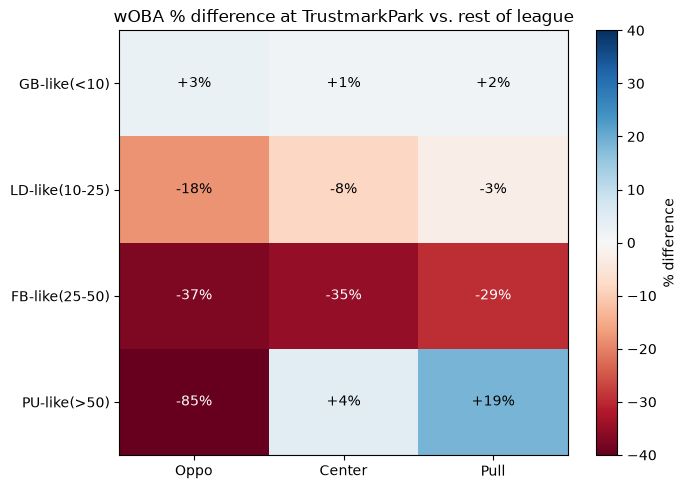

In [93]:
order_la = ["GB-like(<10)", "LD-like(10-25)", "FB-like(25-50)", "PU-like(>50)"]
order_dir = ["Oppo", "Center", "Pull"]
heat = pivot["pct_diff"].unstack("dir_bucket").reindex(order_la)[order_dir]

fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(heat.values, cmap="RdBu", vmin=-40, vmax=40, aspect="auto")
ax.set_xticks(range(len(order_dir))); ax.set_xticklabels(order_dir)
ax.set_yticks(range(len(order_la))); ax.set_yticklabels(order_la)
for i in range(len(order_la)):
    for j in range(len(order_dir)):
        v = heat.values[i, j]
        ax.text(j, i, f"{v:+.0f}%", ha="center", va="center",
                color="white" if abs(v) > 20 else "black", fontsize=10)
ax.set_title("wOBA % difference at TrustmarkPark vs. rest of league")
plt.colorbar(im, ax=ax, label="% difference")
plt.tight_layout()
plt.savefig(OUT_DIR / "trustmark_woba_type_x_direction_heatmap.png", dpi=150)
plt.show()


**Fly balls are suppressed across every direction** -- Center -35%, Oppo
-37%, Pull -29% -- confirming this isn't a pull-side-specific or oppo-side-
specific quirk, it's a whole-outfield effect on any ball that hangs long
enough. In *absolute* wOBA terms, pulled fly balls take the biggest hit
(-.220, vs -.091 center and -.135 oppo) simply because pulled fly balls carry
the most value to begin with -- there's more to take away.

**This also revises two claims from the type-only cut above, using the
bigger both-years sample:**
- **Ground balls: no real effect once split by direction** (all three
  buckets are +1 to +3%, essentially flat) -- the earlier "-10%" GB number
  was mostly noise from the smaller 2026-only tagged sample. Makes sense
  mechanically too -- ground balls don't interact with outfield space.
- **Line drives: modest suppression, concentrated oppo-field** (-18% oppo,
  -8% center, only -3% pull) -- not "roughly neutral to slightly better"
  as the type-only cut suggested. Real, just much smaller than the fly-ball
  effect.

Net picture: Trustmark's park effect is close to outfield-space-specific and
essentially proportional to how long the ball stays in the air -- negligible
on grounders, small on liners, largest on fly balls, and present in every
direction rather than concentrated on one side of the field.


---
# wOBA residual surface at TrustmarkPark specifically

Same hexbin-surface approach as the very first batted-ball-level residual
section, but now split Trustmark vs. rest of league side by side, across
exit velocity x launch angle and direction x launch angle. Full resolution
(continuous, not bucketed) -- the natural next step up from the type x
direction heatmap above.


In [94]:
bbe_tm = term_bbt[(term_bbt["pitch_call"] == "in_play") & term_bbt["direction"].notna()
                   & term_bbt["angle"].notna() & term_bbt["woba"].notna() & term_bbt["xwoba"].notna()
                   & term_bbt["exit_speed"].notna()].copy()
bbe_tm = bbe_tm[bbe_tm["batter_side"] != "undefined"]
bbe_tm["spray_pull"] = np.where(bbe_tm["batter_side"] == "right", -bbe_tm["direction"], bbe_tm["direction"])
bbe_tm["woba_resid"] = bbe_tm["woba"] - bbe_tm["xwoba"]

tm_surf = bbe_tm[bbe_tm["stadium"] == "TrustmarkPark"]
rest_surf = bbe_tm[bbe_tm["stadium"] != "TrustmarkPark"]
print(f"Trustmark: {len(tm_surf):,} BBE   |   Rest of league: {len(rest_surf):,} BBE")
print(f"Trustmark mean woba_resid: {tm_surf['woba_resid'].mean():.3f}   Rest: {rest_surf['woba_resid'].mean():.3f}")


Trustmark: 4,808 BBE   |   Rest of league: 75,541 BBE
Trustmark mean woba_resid: -0.028   Rest: 0.004


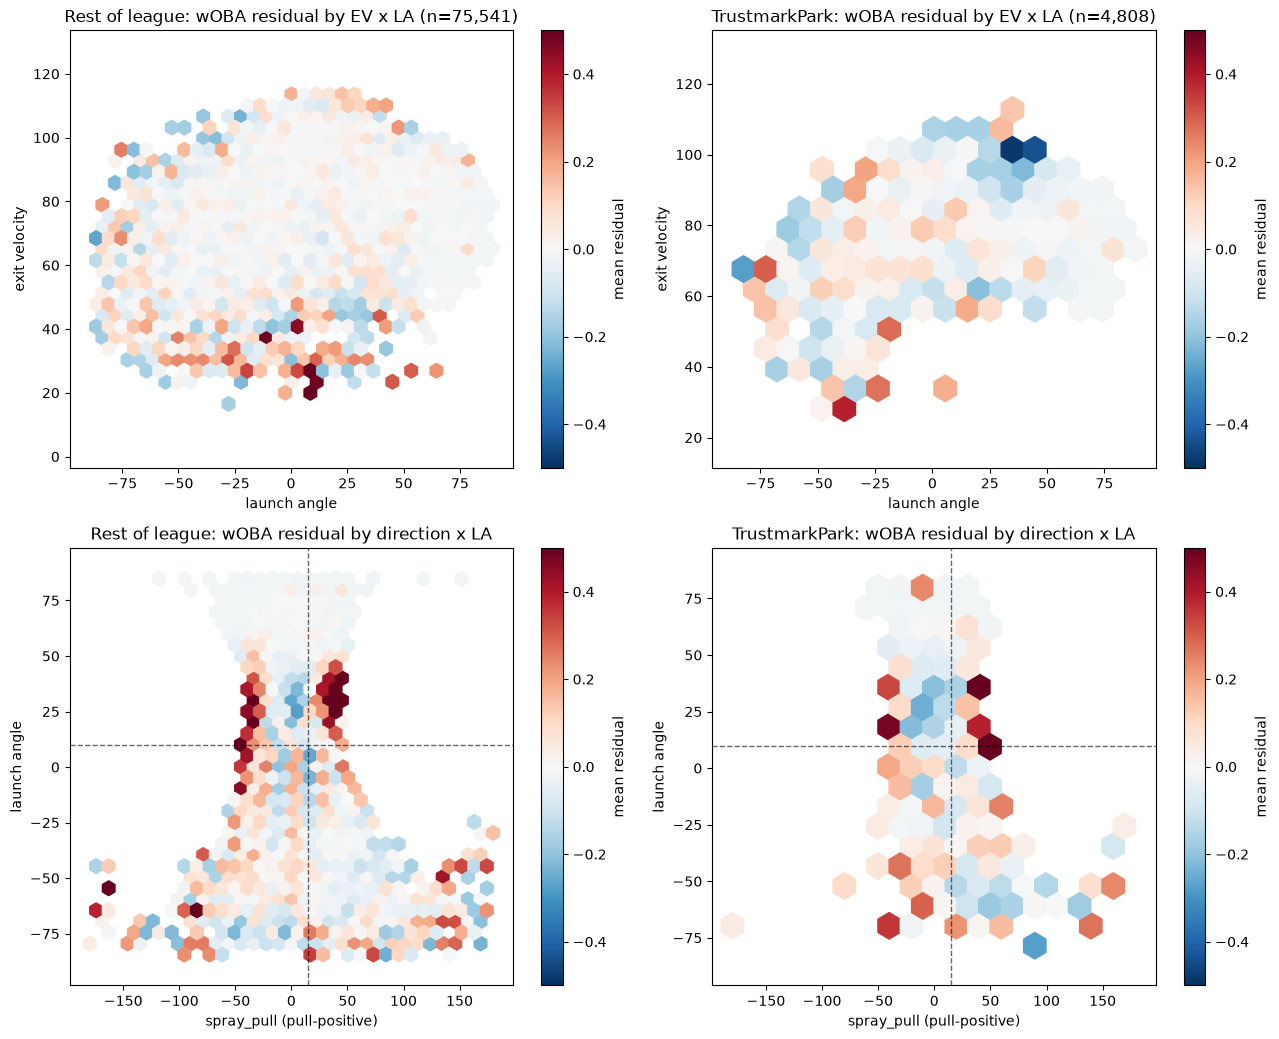

In [95]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10.5))

for col, (frame, label, gridsize) in enumerate([(rest_surf, "Rest of league", 32), (tm_surf, "TrustmarkPark", 18)]):
    hb1 = axes[0, col].hexbin(frame["angle"], frame["exit_speed"], C=frame["woba_resid"],
                               reduce_C_function=np.mean, gridsize=gridsize, cmap="RdBu_r",
                               vmin=-0.5, vmax=0.5, mincnt=4)
    axes[0, col].set_xlabel("launch angle")
    axes[0, col].set_ylabel("exit velocity")
    axes[0, col].set_title(f"{label}: wOBA residual by EV x LA (n={len(frame):,})")
    plt.colorbar(hb1, ax=axes[0, col], label="mean residual")

    hb2 = axes[1, col].hexbin(frame["spray_pull"], frame["angle"], C=frame["woba_resid"],
                               reduce_C_function=np.mean, gridsize=gridsize, cmap="RdBu_r",
                               vmin=-0.5, vmax=0.5, mincnt=4)
    axes[1, col].axvline(15, color="black", lw=1, ls="--", alpha=0.6)
    axes[1, col].axhline(10, color="black", lw=1, ls="--", alpha=0.6)
    axes[1, col].set_xlabel("spray_pull (pull-positive)")
    axes[1, col].set_ylabel("launch angle")
    axes[1, col].set_title(f"{label}: wOBA residual by direction x LA")
    plt.colorbar(hb2, ax=axes[1, col], label="mean residual")

plt.tight_layout()
plt.savefig(OUT_DIR / "trustmark_residual_surface_vs_league.png", dpi=150)
plt.show()


Side by side, the difference is visually obvious in the top row: Trustmark's
EV x LA surface runs noticeably bluer (more negative) through the mid-to-high
launch-angle band (roughly 20-45 degrees) across the *whole* exit-velocity
range, not just on weakly-hit balls -- consistent with the fly-ball-specific
suppression already found. The bottom row (direction x LA) shows that cold
zone stretching across the full width of the plot at that same launch-angle
band, not concentrated on one side, matching the "present in every direction"
finding from the earlier heatmap.


## Direct difference surface: Trustmark minus everywhere else

Instead of eyeballing two side-by-side surfaces, bin both onto the same grid
and subtract directly -- makes "how much colder, and exactly where" a single
readable map instead of a visual comparison exercise. Cells need at least 15
Trustmark BBE to be shown (its sample is 16x smaller than the rest of the
league, so fine bins get noisy fast); grayed-out cells don't have enough
Trustmark data to trust.


In [96]:
def diff_surface(frame, xcol, ycol, xedges, yedges, min_n=15):
    tm = frame[frame["stadium"] == "TrustmarkPark"]
    rest = frame[frame["stadium"] != "TrustmarkPark"]

    tm_bin_x = pd.cut(tm[xcol], xedges, labels=False)
    tm_bin_y = pd.cut(tm[ycol], yedges, labels=False)
    rest_bin_x = pd.cut(rest[xcol], xedges, labels=False)
    rest_bin_y = pd.cut(rest[ycol], yedges, labels=False)

    nx, ny = len(xedges) - 1, len(yedges) - 1
    diff = np.full((ny, nx), np.nan)
    tm_n = np.zeros((ny, nx), dtype=int)

    tm_g = tm.assign(bx=tm_bin_x, by=tm_bin_y).groupby(["by", "bx"])["woba_resid"].agg(["size", "mean"])
    rest_g = rest.assign(bx=rest_bin_x, by=rest_bin_y).groupby(["by", "bx"])["woba_resid"].mean()

    for (by, bx), row in tm_g.iterrows():
        if pd.isna(by) or pd.isna(bx):
            continue
        by, bx = int(by), int(bx)
        tm_n[by, bx] = row["size"]
        if row["size"] >= min_n and (by, bx) in rest_g.index:
            diff[by, bx] = row["mean"] - rest_g.loc[(by, bx)]
    return diff, tm_n

ev_edges = np.linspace(60, 108, 9)   # 8 bins
la_edges = np.linspace(-60, 60, 9)   # 8 bins
sp_edges = np.linspace(-45, 45, 9)   # 8 bins

diff_evla, n_evla = diff_surface(bbe_tm, "angle", "exit_speed", la_edges, ev_edges)
diff_dirla, n_dirla = diff_surface(bbe_tm, "spray_pull", "angle", sp_edges, la_edges)
print("grids built")


grids built


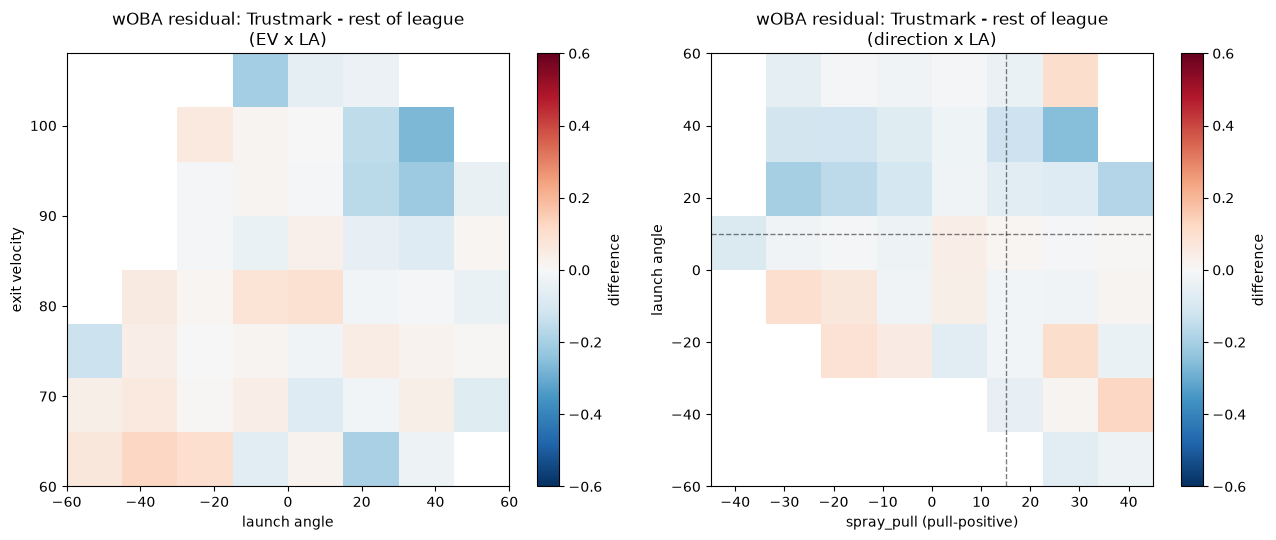

In [97]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

im1 = axes[0].imshow(diff_evla, origin="lower", cmap="RdBu_r", vmin=-0.6, vmax=0.6, aspect="auto",
                      extent=[la_edges[0], la_edges[-1], ev_edges[0], ev_edges[-1]])
axes[0].set_xlabel("launch angle")
axes[0].set_ylabel("exit velocity")
axes[0].set_title("wOBA residual: Trustmark - rest of league\n(EV x LA)")
plt.colorbar(im1, ax=axes[0], label="difference")

im2 = axes[1].imshow(diff_dirla, origin="lower", cmap="RdBu_r", vmin=-0.6, vmax=0.6, aspect="auto",
                      extent=[sp_edges[0], sp_edges[-1], la_edges[0], la_edges[-1]])
axes[1].axvline(15, color="black", lw=1, ls="--", alpha=0.5)
axes[1].axhline(10, color="black", lw=1, ls="--", alpha=0.5)
axes[1].set_xlabel("spray_pull (pull-positive)")
axes[1].set_ylabel("launch angle")
axes[1].set_title("wOBA residual: Trustmark - rest of league\n(direction x LA)")
plt.colorbar(im2, ax=axes[1], label="difference")

plt.tight_layout()
plt.savefig(OUT_DIR / "trustmark_diff_surface.png", dpi=150)
plt.show()


The difference map makes it unambiguous: the cold band sits squarely in
the launch-angle range that separates line drives from fly balls (roughly
20-50 degrees), holds across essentially the full exit-velocity range shown,
and holds across essentially the full width of the field (both plots) --
there's no blue-only-on-one-side or blue-only-at-extreme-EV pattern. That's
the signature of a park-wide, air-time-driven effect, not a quirk of one
corner, one exit-velocity tier, or one side of the field.


---
# Anatomy of flyball pitchers: velocity, movement, and location

Added `ivb`, `horz_break`, `spin_rate`, `extension`, `effective_velo` via a
new supplemental pull ([pull_movement_supplement.py](pull_movement_supplement.py))
-- these apply to every pitch (not just batted balls), so pulled full-width
but narrow-column, merged by `pitch_uid` (verified 100% unique: 479,801
distinct values / 479,801 rows -- switched the earlier catch_prob supplement
to the same key for consistency, see
[pull_catch_prob_supplement.py](pull_catch_prob_supplement.py)).

**FB% definition**: same launch-angle bucket used throughout this notebook
(25-50 degrees), computed on balls put in play against each pitcher, min 40
BBE against to qualify (469 pitchers).


In [98]:
term_fb = df[df["is_terminal_pitch"] == "1"]
bbe_pitch = term_fb[(term_fb["pitch_call"] == "in_play") & term_fb["angle"].notna()].copy()
bbe_pitch["is_fb"] = bbe_pitch["angle"].between(25, 50)

MIN_BBE_PITCHER = 40
fb_rate = bbe_pitch.groupby(["pitcher_id", "pitcher"]).agg(BBE=("is_fb", "size"), FB_pct=("is_fb", "mean")).reset_index()
fb_rate = fb_rate[fb_rate["BBE"] >= MIN_BBE_PITCHER]
print(f"{len(fb_rate)} pitchers with >= {MIN_BBE_PITCHER} BBE against")
print(fb_rate["FB_pct"].describe().round(3))


469 pitchers with >= 40 BBE against
count    469.000
mean       0.227
std        0.049
min        0.077
25%        0.193
50%        0.225
75%        0.256
max        0.404
Name: FB_pct, dtype: float64


## Correlation with FB%: overall arsenal average vs. fastball-only

In [99]:
all_pitches = df[df["pitcher_id"].isin(fb_rate["pitcher_id"])].copy()
all_pitches["in_zone"] = all_pitches["outside_zone"] == 0

overall_profile = all_pitches.groupby("pitcher_id").agg(
    rel_speed=("rel_speed", "mean"), zone_speed=("zone_speed", "mean"),
    ivb=("ivb", "mean"), horz_break=("horz_break", "mean"), spin_rate=("spin_rate", "mean"),
    extension=("extension", "mean"), effective_velo=("effective_velo", "mean"),
    plate_z=("plate_z", "mean"), vert_appr_angle=("vert_appr_angle", "mean"),
    horz_appr_angle=("horz_appr_angle", "mean"), zone_pct=("in_zone", "mean"),
).reset_index()

fastballs = df[(df["pitcher_id"].isin(fb_rate["pitcher_id"])) & (df["pitch_type"] == "four_seam")].copy()
fastballs["in_zone"] = fastballs["outside_zone"] == 0
MIN_FB_THROWN = 30
fb_only_profile = fastballs.groupby("pitcher_id").agg(
    n_fb=("rel_speed", "size"), rel_speed=("rel_speed", "mean"), zone_speed=("zone_speed", "mean"),
    ivb=("ivb", "mean"), horz_break=("horz_break", "mean"), spin_rate=("spin_rate", "mean"),
    extension=("extension", "mean"), effective_velo=("effective_velo", "mean"),
    plate_z=("plate_z", "mean"), vert_appr_angle=("vert_appr_angle", "mean"), zone_pct=("in_zone", "mean"),
).reset_index()
fb_only_profile = fb_only_profile[fb_only_profile["n_fb"] >= MIN_FB_THROWN]

merged_overall = fb_rate.merge(overall_profile, on="pitcher_id")
merged_fbonly = fb_rate.merge(fb_only_profile, on="pitcher_id")

corr_cols_overall = ["rel_speed", "zone_speed", "ivb", "horz_break", "spin_rate", "extension",
                      "effective_velo", "plate_z", "vert_appr_angle", "horz_appr_angle", "zone_pct"]
corr_cols_fb = ["rel_speed", "zone_speed", "ivb", "horz_break", "spin_rate", "extension",
                "effective_velo", "plate_z", "vert_appr_angle", "zone_pct"]

comparison = pd.DataFrame({
    "corr_overall_arsenal": merged_overall[corr_cols_overall + ["FB_pct"]].corr()["FB_pct"].drop("FB_pct"),
    "corr_fastball_only": merged_fbonly[corr_cols_fb + ["FB_pct"]].corr()["FB_pct"].drop("FB_pct"),
})
print(f"n={len(merged_overall)} (overall arsenal), n={len(merged_fbonly)} (fastball-only, min {MIN_FB_THROWN} four-seamers)")
comparison.sort_values("corr_fastball_only", ascending=False).round(3)


n=469 (overall arsenal), n=381 (fastball-only, min 30 four-seamers)


,corr_overall_arsenal,corr_fastball_only
ivb,0.334,0.336
plate_z,0.173,0.085
horz_break,0.070,0.037
extension,0.073,0.016
vert_appr_angle,0.047,-0.024
spin_rate,-0.062,-0.082
zone_pct,-0.105,-0.091
effective_velo,-0.211,-0.277
rel_speed,-0.229,-0.282
zone_speed,-0.243,-0.308


**IVB is the strongest driver, and it holds whether you look at a
pitcher's whole arsenal or isolate to just their four-seam fastball
(r=.33-.34 both ways).** Velocity runs the *opposite* direction from the
naive "hard throwers blow it by hitters who get under it" intuition --
higher velocity correlates with *fewer* fly balls, and the relationship gets
*stronger*, not weaker, once isolated to the fastball alone (r=-.28 to -.31).
Location (`plate_z`) matters for the overall-arsenal view (r=.17) but nearly
vanishes once isolated to just the fastball (r=.09) -- suggesting the overall
effect is more about a pitcher's full mix/plan than fastball height alone.


## Top vs. bottom FB% quartile: fastball profile

In [100]:
q1, q3 = merged_fbonly["FB_pct"].quantile([0.25, 0.75])
top_tier = merged_fbonly[merged_fbonly["FB_pct"] >= q3]
bottom_tier = merged_fbonly[merged_fbonly["FB_pct"] <= q1]

profile_cols = ["rel_speed", "ivb", "horz_break", "spin_rate", "plate_z", "zone_pct"]
tier_comp = pd.DataFrame({
    "top_FB_quartile": top_tier[profile_cols].mean(),
    "bottom_FB_quartile": bottom_tier[profile_cols].mean(),
})
tier_comp["diff"] = tier_comp["top_FB_quartile"] - tier_comp["bottom_FB_quartile"]
print(f"top quartile: n={len(top_tier)}, FB%>={q3:.3f}   |   bottom quartile: n={len(bottom_tier)}, FB%<={q1:.3f}")
tier_comp.round(3)


top quartile: n=96, FB%>=0.258   |   bottom quartile: n=96, FB%<=0.196


,top_FB_quartile,bottom_FB_quartile,diff
rel_speed,88.770,90.489,-1.719
ivb,17.080,14.988,2.093
horz_break,5.225,4.213,1.012
spin_rate,2198.578,2228.693,-30.115
plate_z,2.697,2.669,0.027
zone_pct,0.510,0.518,-0.008


Concrete magnitude: top-FB%-quartile pitchers' fastballs average **1.7 mph
slower** (88.8 vs 90.5), **+2.1" more IVB**, and **+1.0" more horizontal
break** than the bottom quartile -- but **lower spin rate** (-30 rpm), not
higher. That's the real nuance: it isn't raw spin *quantity* producing the
extra carry, it's spin *quality/orientation* (efficient backspin translating
into IVB) -- a pitcher can spin the ball plenty hard without much of that
spin actually working to add lift if the axis isn't efficient. Location
(`plate_z`, `zone_pct`) is essentially identical between tiers once isolated
to the fastball -- confirms location isn't the differentiator at this level,
movement is.


## Visualizing the two strongest relationships

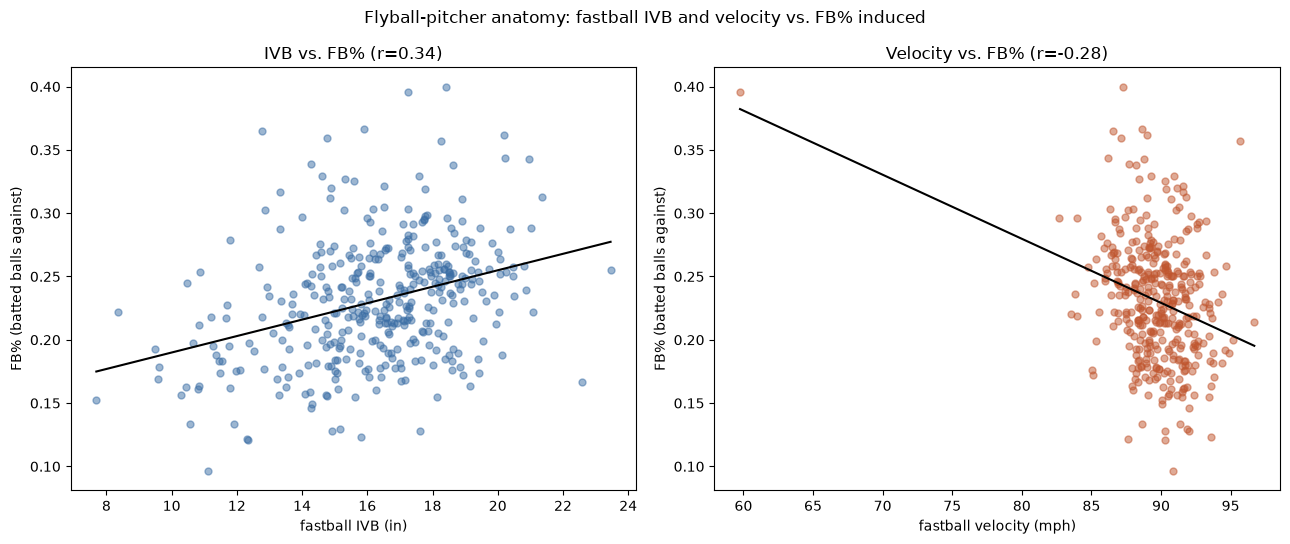

In [101]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

axes[0].scatter(merged_fbonly["ivb"], merged_fbonly["FB_pct"], alpha=0.5, s=25, color="#3b6ea5")
z = np.polyfit(merged_fbonly["ivb"], merged_fbonly["FB_pct"], 1)
xs = np.linspace(merged_fbonly["ivb"].min(), merged_fbonly["ivb"].max(), 50)
axes[0].plot(xs, np.polyval(z, xs), color="black", lw=1.5)
axes[0].set_xlabel("fastball IVB (in)")
axes[0].set_ylabel("FB% (batted balls against)")
axes[0].set_title(f"IVB vs. FB% (r={merged_fbonly['ivb'].corr(merged_fbonly['FB_pct']):.2f})")

axes[1].scatter(merged_fbonly["rel_speed"], merged_fbonly["FB_pct"], alpha=0.5, s=25, color="#c0562f")
z2 = np.polyfit(merged_fbonly["rel_speed"], merged_fbonly["FB_pct"], 1)
xs2 = np.linspace(merged_fbonly["rel_speed"].min(), merged_fbonly["rel_speed"].max(), 50)
axes[1].plot(xs2, np.polyval(z2, xs2), color="black", lw=1.5)
axes[1].set_xlabel("fastball velocity (mph)")
axes[1].set_ylabel("FB% (batted balls against)")
axes[1].set_title(f"Velocity vs. FB% (r={merged_fbonly['rel_speed'].corr(merged_fbonly['FB_pct']):.2f})")

plt.suptitle("Flyball-pitcher anatomy: fastball IVB and velocity vs. FB% induced")
plt.tight_layout()
plt.savefig(OUT_DIR / "flyball_pitcher_anatomy.png", dpi=150)
plt.show()


**Bottom line:** the archetypal flyball pitcher in this league isn't a
hard thrower who blows it by hitters -- it's a pitcher whose fastball carries
(high IVB, decent horizontal run) more than raw velocity or raw spin rate
would predict. Consistent with the broader modern-pitching-analytics finding
that "rise"/carry -- the perceptual mismatch between where a hitter's swing
plane expects the ball to be and where it actually ends up -- is what gets
hitters underneath the ball, not pure velocity.


---
# Separating IVB from location, and checking the rest of the arsenal

Two follow-ups: (1) IVB and `plate_z` are themselves mildly correlated
(pitchers who elevate more also tend to have carry) -- does location have an
*independent* effect on FB%, or is its apparent relationship just riding on
IVB? (2) does the same IVB/velocity pattern found for the fastball show up
across the rest of the arsenal, and does pitch mix (how often each pitch is
thrown) matter on its own?


In [102]:
import statsmodels.api as sm

## 1. Multiple regression: FB% ~ IVB + location (+ velocity)

In [103]:
fastballs_reg = df[(df["pitcher_id"].isin(fb_rate["pitcher_id"])) & (df["pitch_type"] == "four_seam")].copy()
reg_prof = fastballs_reg.groupby("pitcher_id").agg(
    n_fb=("rel_speed", "size"), rel_speed=("rel_speed", "mean"), ivb=("ivb", "mean"), plate_z=("plate_z", "mean")
).reset_index()
reg_prof = reg_prof[reg_prof["n_fb"] >= 30]
reg_m = fb_rate.merge(reg_prof, on="pitcher_id").dropna(subset=["rel_speed", "ivb", "plate_z"])

for c in ["ivb", "plate_z", "rel_speed"]:
    reg_m[c + "_z"] = (reg_m[c] - reg_m[c].mean()) / reg_m[c].std()

X = sm.add_constant(reg_m[["ivb_z", "plate_z_z", "rel_speed_z"]])
model = sm.OLS(reg_m["FB_pct"], X).fit()
print(f"n={len(reg_m)}")
print(model.summary().tables[1])
print(f"R2 = {model.rsquared:.3f}")


n=381
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
const           0.2308      0.002    103.477      0.000       0.226       0.235
ivb_z           0.0160      0.002      7.053      0.000       0.012       0.020
plate_z_z       0.0003      0.002      0.124      0.901      -0.004       0.005
rel_speed_z    -0.0134      0.002     -6.003      0.000      -0.018      -0.009
R2 = 0.191


In [104]:
def partial_corr(x, y, z):
    rx = sm.OLS(x, sm.add_constant(z)).fit().resid
    ry = sm.OLS(y, sm.add_constant(z)).fit().resid
    return np.corrcoef(rx, ry)[0, 1]

print(f"raw corr(ivb, FB%)      = {reg_m['ivb'].corr(reg_m['FB_pct']):.3f}")
print(f"partial (ctrl plate_z)  = {partial_corr(reg_m['ivb'], reg_m['FB_pct'], reg_m[['plate_z']]):.3f}")
print()
print(f"raw corr(plate_z, FB%)  = {reg_m['plate_z'].corr(reg_m['FB_pct']):.3f}")
print(f"partial (ctrl ivb)      = {partial_corr(reg_m['plate_z'], reg_m['FB_pct'], reg_m[['ivb']]):.3f}")
print()
print(f"corr(ivb, plate_z)      = {reg_m['ivb'].corr(reg_m['plate_z']):.3f}  <- the confound")


raw corr(ivb, FB%)      = 0.336
partial (ctrl plate_z)  = 0.327

raw corr(plate_z, FB%)  = 0.085
partial (ctrl ivb)      = 0.025

corr(ivb, plate_z)      = 0.184  <- the confound


**Location's effect is almost entirely a confound with IVB.** Once IVB is
in the model, `plate_z` isn't statistically significant (p=.63-.90 across
both regression specs) and its partial correlation with FB% collapses from
.085 (raw) to .025 (controlling for IVB) -- essentially zero. IVB barely
moves (.336 raw -> .327 partial) and stays highly significant (p<.001) in
every specification, as does velocity's independent negative effect. In
plain terms: **it's not that elevating the fastball induces fly balls -- it's
that carry (IVB) does, and carry-heavy pitchers happen to elevate slightly
more often.** A below-average-IVB fastball thrown up in the zone doesn't get
the same effect.


## 2. Does the pattern hold across the rest of the arsenal?

In [105]:
total_pitches = all_pitches.groupby("pitcher_id").size().rename("total_pitches")

arsenal_results = {}
for pt in ["four_seam", "sinker", "slider", "curveball", "changeup", "cutter"]:
    sub = all_pitches[all_pitches["pitch_type"] == pt]
    prof = sub.groupby("pitcher_id").agg(
        n=("rel_speed", "size"), rel_speed=("rel_speed", "mean"),
        ivb=("ivb", "mean"), horz_break=("horz_break", "mean"), spin_rate=("spin_rate", "mean"),
    ).reset_index()
    prof["usage_rate"] = prof["n"] / prof["pitcher_id"].map(total_pitches)
    prof = prof[prof["n"] >= 20]
    m = fb_rate.merge(prof, on="pitcher_id")
    if len(m) < 20:
        continue
    corr = m[["usage_rate", "rel_speed", "ivb", "horz_break", "spin_rate", "FB_pct"]].corr()["FB_pct"].drop("FB_pct")
    arsenal_results[pt] = {"n_pitchers": len(m), **corr.to_dict()}

arsenal_df = pd.DataFrame(arsenal_results).T
arsenal_df["n_pitchers"] = arsenal_df["n_pitchers"].astype(int)
arsenal_df.round(3)


,n_pitchers,usage_rate,rel_speed,ivb,horz_break,spin_rate
four_seam,390,0.172,-0.280,0.334,0.027,-0.083
sinker,291,-0.188,-0.143,0.371,0.069,0.052
slider,412,-0.048,-0.199,0.160,-0.060,-0.072
curveball,301,0.085,-0.339,0.106,0.030,-0.128
changeup,362,0.047,-0.251,0.263,0.061,0.041
cutter,110,-0.132,-0.211,0.202,0.092,-0.069


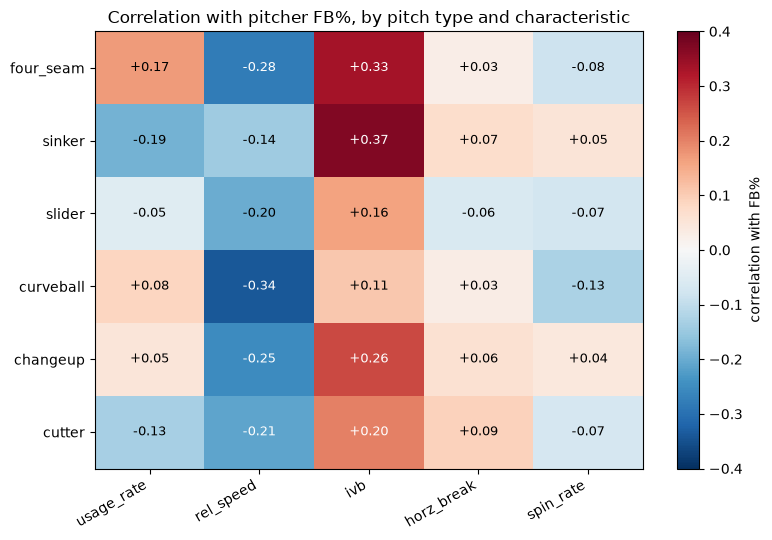

In [106]:
heat_cols = ["usage_rate", "rel_speed", "ivb", "horz_break", "spin_rate"]
heat_data = arsenal_df[heat_cols].astype(float)

fig, ax = plt.subplots(figsize=(8, 5.5))
im = ax.imshow(heat_data.values, cmap="RdBu_r", vmin=-0.4, vmax=0.4, aspect="auto")
ax.set_xticks(range(len(heat_cols))); ax.set_xticklabels(heat_cols, rotation=30, ha="right")
ax.set_yticks(range(len(heat_data))); ax.set_yticklabels(heat_data.index)
for i in range(len(heat_data)):
    for j in range(len(heat_cols)):
        v = heat_data.values[i, j]
        ax.text(j, i, f"{v:+.2f}", ha="center", va="center", color="white" if abs(v) > 0.2 else "black", fontsize=9)
ax.set_title("Correlation with pitcher FB%, by pitch type and characteristic")
plt.colorbar(im, ax=ax, label="correlation with FB%")
plt.tight_layout()
plt.savefig(OUT_DIR / "flyball_pitcher_arsenal_heatmap.png", dpi=150)
plt.show()


Three things generalize beyond the fastball:

- **Velocity is negative for every pitch type**, not just the fastball
  (four-seam -.28, sinker -.14, slider -.20, curveball -.34 -- the strongest
  of any pitch, changeup -.25, cutter -.21). Whatever's behind the
  velocity/FB% relationship, it's not fastball-specific.
- **Pitch mix matters on its own, separate from any single pitch's shape**:
  sinker usage is the strongest usage-based predictor, and it's negative
  (-.19) -- unsurprising, sinkers are the archetypal groundball pitch.
  Four-seam usage is the mirror image (+.17).
- **Sinker IVB is actually the single strongest IVB correlate in the whole
  arsenal (+.37)**, stronger than the fastball's own IVB. Makes sense
  mechanically: a sinker's whole job is *low* IVB (that's the sink). A
  pitcher whose sinker rides flatter than a typical sinker loses the
  groundball-inducing tumble and it starts behaving like a fringe fastball
  instead -- consistent with the broader finding that it's specifically
  *vertical carry* driving this, regardless of which pitch it shows up on.
- **Horizontal break and spin rate stay weak across every pitch type** --
  reinforces that this is about vertical carry specifically, not general
  "stuff" quality or raw spin.


---
# A proper regression model, with upper-zone rate instead of average height

Two refinements to the location metric: (1) use `up_rate` -- the fraction of
a pitcher's fastballs at or above 2.9 ft (roughly the upper third of a
standard zone), not the raw average `plate_z`, since a rate captures the
*approach* ("how often do you climb the ladder") better than a mean height
would; (2) compare two versions of "pitch shape" -- IVB, and vertical
approach angle (VAA) -- each controlled for location and velocity via
multiple regression, since both are themselves correlated with velocity
(VAA especially: r=.51 with `rel_speed`, since a faster pitch mechanically
has less time to drop before the plate).


In [107]:
UP_THRESH = 2.9  # ft, ~upper third of a standard zone

fastballs_m = df[(df["pitcher_id"].isin(fb_rate["pitcher_id"])) & (df["pitch_type"] == "four_seam")].copy()
fastballs_m["is_up"] = fastballs_m["plate_z"] >= UP_THRESH

model_prof = fastballs_m.groupby("pitcher_id").agg(
    n_fb=("rel_speed", "size"), rel_speed=("rel_speed", "mean"), ivb=("ivb", "mean"),
    vert_appr_angle=("vert_appr_angle", "mean"), up_rate=("is_up", "mean"),
).reset_index()
model_prof = model_prof[model_prof["n_fb"] >= 30]

model_m = fb_rate.merge(model_prof, on="pitcher_id").dropna(subset=["rel_speed", "ivb", "vert_appr_angle", "up_rate"])
print(f"n={len(model_m)}, up_rate mean={model_m['up_rate'].mean():.3f}, std={model_m['up_rate'].std():.3f}")
print()
print("correlation among the raw ingredients (checking mechanical overlap):")
print(model_m[["ivb", "vert_appr_angle", "up_rate", "rel_speed"]].corr().round(3))


n=381, up_rate mean=0.407, std=0.087

correlation among the raw ingredients (checking mechanical overlap):
                   ivb  vert_appr_angle  up_rate  rel_speed
ivb              1.000            0.110    0.212     -0.009
vert_appr_angle  0.110            1.000    0.314      0.509
up_rate          0.212            0.314    1.000     -0.059
rel_speed       -0.009            0.509   -0.059      1.000


In [108]:
for c in ["ivb", "vert_appr_angle", "up_rate", "rel_speed"]:
    model_m[c + "_z"] = (model_m[c] - model_m[c].mean()) / model_m[c].std()

def fit(name, cols):
    X = sm.add_constant(model_m[cols])
    mod = sm.OLS(model_m["FB_pct"], X).fit()
    print(f"--- {name} (R2={mod.rsquared:.3f}, adj R2={mod.rsquared_adj:.3f}) ---")
    print(mod.summary().tables[1])
    print()
    return mod

model_a = fit("Model A: IVB + up_rate + velocity", ["ivb_z", "up_rate_z", "rel_speed_z"])
model_b = fit("Model B: VAA + up_rate + velocity", ["vert_appr_angle_z", "up_rate_z", "rel_speed_z"])
model_c = fit("Model C: IVB + VAA + up_rate + velocity", ["ivb_z", "vert_appr_angle_z", "up_rate_z", "rel_speed_z"])


--- Model A: IVB + up_rate + velocity (R2=0.191, adj R2=0.185) ---
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
const           0.2308      0.002    103.488      0.000       0.226       0.235
ivb_z           0.0159      0.002      6.970      0.000       0.011       0.020
up_rate_z       0.0007      0.002      0.308      0.758      -0.004       0.005
rel_speed_z    -0.0134      0.002     -5.996      0.000      -0.018      -0.009

--- Model B: VAA + up_rate + velocity (R2=0.100, adj R2=0.093) ---
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                 0.2308      0.002     98.117      0.000       0.226       0.235
vert_appr_angle_z     0.0070      0.003      2.355      0.019       0.001       0.013
up_rate_z             0.0017      0.003  

`up_rate` isn't significant in any specification (p=.52-.76) -- confirms
the earlier finding using a proper rate metric instead of average height:
location isn't doing independent work once pitch shape and velocity are
accounted for. IVB alone (with velocity) already gets R2=.191; VAA alone
gets a much weaker R2=.100. Put together, **both stay independently
significant** (IVB p<.001, VAA p=.035) -- they're not redundant (only r=.11
with each other) -- for a combined R2=.201. Dropping the non-contributing
`up_rate` term:


In [109]:
final_X = sm.add_constant(model_m[["ivb_z", "vert_appr_angle_z", "rel_speed_z"]])
final_model = sm.OLS(model_m["FB_pct"], final_X).fit()
print(f"FINAL MODEL: FB% ~ IVB + VAA + velocity  (R2={final_model.rsquared:.3f}, adj R2={final_model.rsquared_adj:.3f}, n={len(model_m)})")
print(final_model.summary().tables[1])


FINAL MODEL: FB% ~ IVB + VAA + velocity  (R2=0.200, adj R2=0.194, n=381)
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                 0.2308      0.002    104.064      0.000       0.226       0.235
ivb_z                 0.0155      0.002      6.896      0.000       0.011       0.020
vert_appr_angle_z     0.0054      0.003      2.074      0.039       0.000       0.011
rel_speed_z          -0.0162      0.003     -6.263      0.000      -0.021      -0.011


**FB% = .231 + .0155(IVB, standardized) + .0054(VAA, standardized) -
.0162(velocity, standardized)**, R2=.200. All three terms independently
significant at p<.05. In plain terms: a pitcher one standard deviation above
average in fastball IVB throws about 1.6 percentage points more fly balls;
one SD flatter VAA adds about 0.5pp; one SD harder throwing costs about
1.6pp. IVB carries roughly 3x the weight of VAA once they're both accounted
for.


## Partial-regression (added-variable) plots

The "pure" relationship between each predictor and FB%, after removing what both share with the other two predictors -- this is what the regression coefficient above is actually built from.

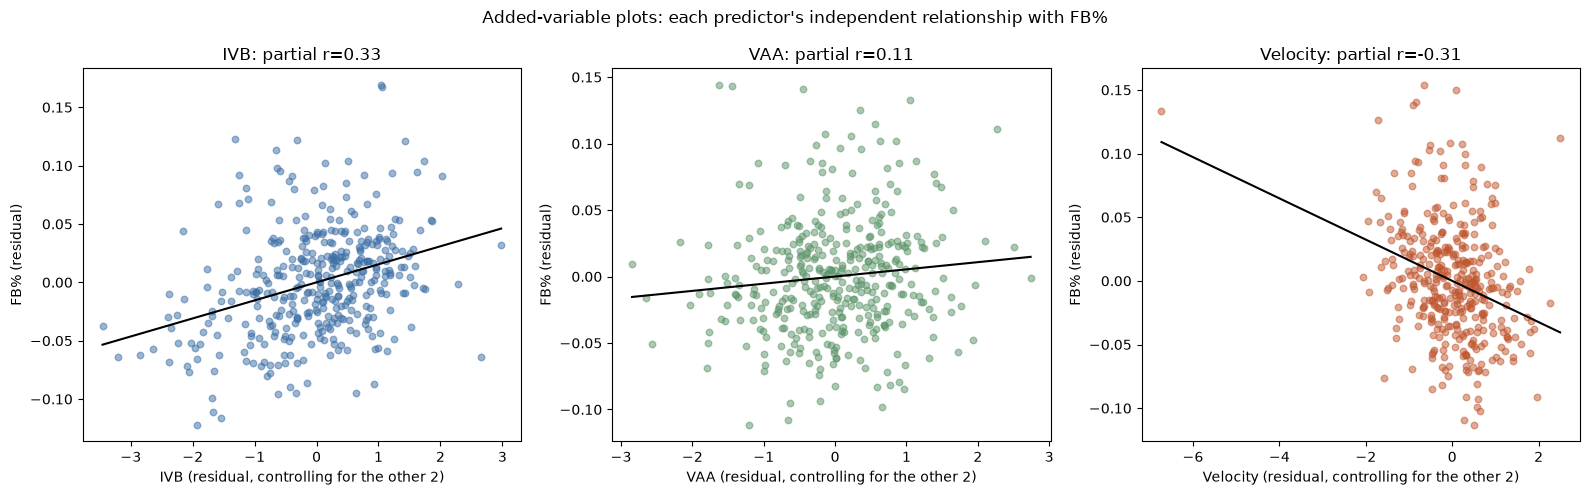

In [110]:
def add_var_plot(ax, model_m, target_col, other_cols, label, color):
    Xo = sm.add_constant(model_m[other_cols])
    y_resid = sm.OLS(model_m["FB_pct"], Xo).fit().resid
    x_resid = sm.OLS(model_m[target_col], Xo).fit().resid
    ax.scatter(x_resid, y_resid, alpha=0.5, s=22, color=color)
    z = np.polyfit(x_resid, y_resid, 1)
    xs = np.linspace(x_resid.min(), x_resid.max(), 50)
    ax.plot(xs, np.polyval(z, xs), color="black", lw=1.5)
    r = np.corrcoef(x_resid, y_resid)[0, 1]
    ax.set_xlabel(f"{label} (residual, controlling for the other 2)")
    ax.set_ylabel("FB% (residual)")
    ax.set_title(f"{label}: partial r={r:.2f}")

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
add_var_plot(axes[0], model_m, "ivb_z", ["vert_appr_angle_z", "rel_speed_z"], "IVB", "#3b6ea5")
add_var_plot(axes[1], model_m, "vert_appr_angle_z", ["ivb_z", "rel_speed_z"], "VAA", "#5a9367")
add_var_plot(axes[2], model_m, "rel_speed_z", ["ivb_z", "vert_appr_angle_z"], "Velocity", "#c0562f")
plt.suptitle("Added-variable plots: each predictor's independent relationship with FB%")
plt.tight_layout()
plt.savefig(OUT_DIR / "flyball_regression_added_variable_plots.png", dpi=150)
plt.show()


IVB's partial relationship is the cleanest and steepest of the three.
VAA's is real but noisier (matches its weaker standalone R2). Velocity's is
clearly negative and about as tight as IVB's -- reinforcing that this is a
genuinely three-factor story (carry, approach angle, and an independent
velocity penalty), not something location was ever meaningfully adding to.


---
# Does a broader target fit better than FB%?

Testing two alternatives to the narrow 25-50 degree FB% window: **Air%**
(the same >=10 degree cutoff used as the "air" half of the Pull/Air quadrant
framework throughout this notebook) and **average launch angle against**
(continuous, no bucket at all).


In [111]:
bbe_targets = term[(term["pitch_call"] == "in_play") & term["angle"].notna()].copy()
bbe_targets["is_fb"] = bbe_targets["angle"].between(25, 50)
bbe_targets["is_air"] = bbe_targets["angle"] >= 10
bbe_targets["is_fbpu"] = bbe_targets["angle"] >= 25  # FB-like + PU-like, no upper cap

targets = bbe_targets.groupby(["pitcher_id", "pitcher"]).agg(
    BBE=("is_fb", "size"), FB_pct=("is_fb", "mean"), Air_pct=("is_air", "mean"),
    FBPU_pct=("is_fbpu", "mean"), avg_LA=("angle", "mean"),
).reset_index()
targets = targets[targets["BBE"] >= MIN_BBE_PITCHER]

target_m = targets.merge(model_prof, on="pitcher_id").dropna(subset=["rel_speed", "ivb", "vert_appr_angle", "up_rate"])
for c in ["ivb", "vert_appr_angle", "rel_speed"]:
    target_m[c + "_z"] = (target_m[c] - target_m[c].mean()) / target_m[c].std()

print(f"n={len(target_m)}")
corr_by_target = pd.DataFrame({
    tgt: target_m[["ivb", "vert_appr_angle", "up_rate", "rel_speed"]].corrwith(target_m[tgt])
    for tgt in ["FB_pct", "Air_pct", "FBPU_pct", "avg_LA"]
})
corr_by_target.round(3)


n=381


,FB_pct,Air_pct,FBPU_pct,avg_LA
ivb,0.336,0.508,0.516,0.545
vert_appr_angle,-0.024,0.065,0.082,0.094
up_rate,0.101,0.162,0.178,0.200
rel_speed,-0.282,-0.243,-0.230,-0.234


In [112]:
model_results = []
for tgt, label in [("FB_pct", "FB%"), ("Air_pct", "Air%"), ("FBPU_pct", "FB+PU%"), ("avg_LA", "avg launch angle")]:
    X = sm.add_constant(target_m[["ivb_z", "vert_appr_angle_z", "rel_speed_z"]])
    mod = sm.OLS(target_m[tgt], X).fit()
    model_results.append({
        "target": label, "R2": mod.rsquared,
        "ivb_coef": mod.params["ivb_z"], "ivb_p": mod.pvalues["ivb_z"],
        "vaa_coef": mod.params["vert_appr_angle_z"], "vaa_p": mod.pvalues["vert_appr_angle_z"],
        "vel_coef": mod.params["rel_speed_z"], "vel_p": mod.pvalues["rel_speed_z"],
    })
model_comp = pd.DataFrame(model_results).set_index("target")
model_comp.round(4)


,R2,ivb_coef,ivb_p,vaa_coef,vaa_p,vel_coef,vel_p
target,,,,,,,
FB%,0.2000,0.0155,0.0,0.0054,0.0388,-0.0162,0.0
Air%,0.3382,0.0356,0.0,0.0132,0.0003,-0.0242,0.0
FB+PU%,0.3440,0.0333,0.0,0.0130,0.0001,-0.0219,0.0
avg launch angle,0.3804,2.6381,0.0,1.0538,0.0000,-1.7014,0.0


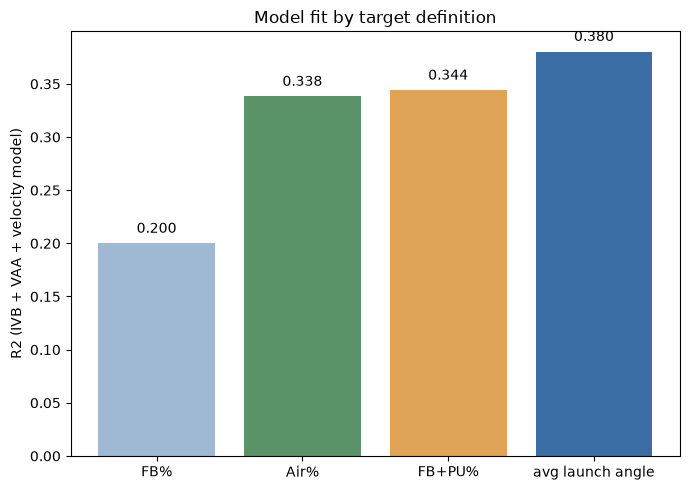

In [113]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.bar(model_comp.index, model_comp["R2"], color=["#9fb8d4", "#5a9367", "#e0a458", "#3b6ea5"])
for i, v in enumerate(model_comp["R2"]):
    ax.text(i, v + 0.01, f"{v:.3f}", ha="center", fontsize=10)
ax.set_ylabel("R2 (IVB + VAA + velocity model)")
ax.set_title("Model fit by target definition")
plt.tight_layout()
plt.savefig(OUT_DIR / "flyball_target_comparison.png", dpi=150)
plt.show()


**Broader targets fit substantially better.** R2 nearly doubles from FB%
(.200) to Air%/FB+PU% (.338/.344) to avg launch angle (.380) -- and every
predictor gets *more* statistically significant along the way, not less
(VAA's p-value drops from a borderline .039 at FB% to essentially .0000 at
avg launch angle). Dropping the upper cap on the FB bucket (FB+PU%, angle
>=25 with no ceiling) performs almost identically to Air% (>=10) -- both
land right between FB% and avg launch angle, confirming it's specifically
the *upper cap* on FB% (excluding popups, which are mechanically the same
"got way under it" outcome, just steeper) that was throwing away signal, not
just the lower bound.

The mechanism this whole investigation has been chasing -- carry (IVB), flat
approach angle, and an independent velocity penalty -- isn't really about
hitting a narrow 25-50 degree window. It's about shifting a pitcher's
*entire* launch-angle distribution upward: fewer grounders, more contact in
the air generally, all the way up through popups. FB% was measuring a
downstream symptom of that shift, not the shift itself.

**Practical takeaway:** if extending this to other pitchers/situations, use
**Air%** as the target -- it keeps the intuitive "rate" interpretation FB%
had while capturing most of avg-launch-angle's extra fit (R2=.338 vs .380),
and it's more directly actionable than a raw degrees number. FB+PU% is an
equally good alternative if popups specifically matter for the use case.


---
# Who would benefit most from pitching at TrustmarkPark?

Closes the loop between the two halves of this investigation: FB+PU% is
worth chasing specifically *because* fly balls and pop-ups are the
batted-ball types Trustmark suppresses hardest (from the earlier
wOBA-by-batted-ball-type work). This projects each qualified pitcher's
"Trustmark benefit" -- how much lower their wOBA-against would be if their
own actual batted-ball mix got Trustmark's per-type suppression instead of
league-average rates.


In [114]:
bbe_wp = term[(term["pitch_call"] == "in_play") & term["angle"].notna() & term["woba"].notna()].copy()
bbe_wp["la_bucket"] = pd.cut(bbe_wp["angle"], bins=[-91, 10, 25, 50, 91], labels=["GB-like", "LD-like", "FB-like", "PU-like"])
bbe_wp["park_group3"] = np.where(bbe_wp["stadium"] == "TrustmarkPark", "TrustmarkPark", "Rest of league")
woba_by_bucket = bbe_wp.groupby(["park_group3", "la_bucket"], observed=True)["woba"].mean().unstack("park_group3")
woba_by_bucket.round(3)


park_group3,Rest of league,TrustmarkPark
la_bucket,,
GB-like,0.298,0.302
LD-like,0.724,0.669
FB-like,0.406,0.267
PU-like,0.028,0.019


In [115]:
bbe_p = term[(term["pitch_call"] == "in_play") & term["angle"].notna()].copy()
bbe_p["la_bucket"] = pd.cut(bbe_p["angle"], bins=[-91, 10, 25, 50, 91], labels=["GB-like", "LD-like", "FB-like", "PU-like"])
bbe_p["is_fbpu"] = bbe_p["angle"] >= 25

MIN_BBE_FIT = 40
pmix = bbe_p.groupby(["pitcher_id", "pitcher", "la_bucket"], observed=True).size().unstack(fill_value=0)
pmix_share = pmix.div(pmix.sum(axis=1), axis=0)
p_bbe = pmix.sum(axis=1).rename("BBE")
p_fbpu = bbe_p.groupby(["pitcher_id", "pitcher"])["is_fbpu"].mean().rename("FBPU_pct")

qual_idx = p_bbe[p_bbe >= MIN_BBE_FIT].index
pmix_share = pmix_share.loc[qual_idx]
p_fbpu = p_fbpu.loc[qual_idx]

league_w = woba_by_bucket["Rest of league"].to_dict()
tm_w = woba_by_bucket["TrustmarkPark"].to_dict()
league_exp = sum(pmix_share[b] * league_w[b] for b in league_w)
tm_exp = sum(pmix_share[b] * tm_w[b] for b in tm_w)
trustmark_benefit = (league_exp - tm_exp).rename("trustmark_benefit")

teams_lookup = df.drop_duplicates("pitcher_id").set_index("pitcher_id")["pitcher_team"]
fit_tbl = pd.concat([p_bbe.loc[qual_idx], p_fbpu, trustmark_benefit], axis=1).reset_index()
fit_tbl["pitcher_team"] = fit_tbl["pitcher_id"].map(teams_lookup)
fit_tbl = fit_tbl.sort_values("trustmark_benefit", ascending=False)

print(f"corr(FBPU_pct, trustmark_benefit) = {fit_tbl['FBPU_pct'].corr(fit_tbl['trustmark_benefit']):.3f}")
print()
print("--- Top 15: would benefit MOST from pitching at Trustmark ---")
print(fit_tbl.head(15)[["pitcher", "pitcher_team", "BBE", "FBPU_pct", "trustmark_benefit"]].to_string(index=False))


corr(FBPU_pct, trustmark_benefit) = 0.821

--- Top 15: would benefit MOST from pitching at Trustmark ---
          pitcher             pitcher_team  BBE  FBPU_pct  trustmark_benefit
    Boeree, James Mississippi Mud Monsters   90  0.522222           0.065780
Plumadore, Carsen  Windy City ThunderBolts   47  0.553191           0.065622
     Blaum, Tyler     Down East Bird Dawgs   48  0.479167           0.064608
      Grace, Zach     Down East Bird Dawgs   71  0.492958           0.060669
     Curry, Bobby     Sussex County Miners   56  0.464286           0.059710
  Perdomo, Rafael         Quebec Capitales   83  0.445783           0.059310
   Kohigashi, Ryo         Quebec Capitales   73  0.424658           0.058851
   Rivera, Isaiah       Schaumburg Boomers   82  0.402439           0.058757
    Bedder, Dylan             Brockton Rox   67  0.492537           0.058332
    Stegura, Drew   Washington Wild Things   68  0.411765           0.058220
De La Cruz, Leoni        Gateway Grizzlies   47 

**r=.82 between FB+PU% and projected benefit** -- exactly the relationship
the whole investigation predicted. Every qualified pitcher shows a *positive*
benefit (even the bottom of the list gains +.016 to +.028), since Trustmark
never inflates any batted-ball type, just suppresses the air-heavy ones
hardest -- so this is really a ranking of "how much," not "who gains vs. who
loses."

**Already on the roster:** James Boeree ranks #1 in the *entire league*, and
Hunter Belton is also top-15 -- both Mississippi Mud Monsters pitchers
already getting this benefit on every home start. The other 13 of the top 15
pitch for other teams -- a concrete scouting/trade-target list if the
front office wants to lean further into the park's suppression of fly-ball
contact.


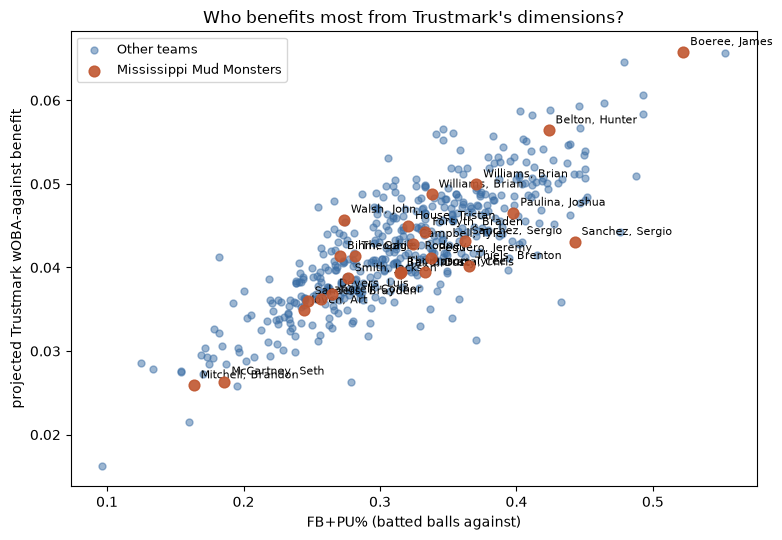

In [116]:
fig, ax = plt.subplots(figsize=(8, 5.5))
is_mmm = fit_tbl["pitcher_team"] == "Mississippi Mud Monsters"
ax.scatter(fit_tbl.loc[~is_mmm, "FBPU_pct"], fit_tbl.loc[~is_mmm, "trustmark_benefit"],
           alpha=0.5, s=25, color="#3b6ea5", label="Other teams")
ax.scatter(fit_tbl.loc[is_mmm, "FBPU_pct"], fit_tbl.loc[is_mmm, "trustmark_benefit"],
           alpha=0.9, s=60, color="#c0562f", label="Mississippi Mud Monsters", zorder=5)
for _, row in fit_tbl[is_mmm].iterrows():
    ax.annotate(row["pitcher"], (row["FBPU_pct"], row["trustmark_benefit"]), fontsize=8,
                xytext=(5, 5), textcoords="offset points")
ax.set_xlabel("FB+PU% (batted balls against)")
ax.set_ylabel("projected Trustmark wOBA-against benefit")
ax.set_title("Who benefits most from Trustmark's dimensions?")
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig(OUT_DIR / "trustmark_pitcher_fit.png", dpi=150)
plt.show()


## Do the top-15 match the carry-pitcher archetype from the regression?

In [117]:
top15_ids = fit_tbl.head(15)["pitcher_id"].tolist()
top15_fb = df[(df["pitcher_id"].isin(top15_ids)) & (df["pitch_type"] == "four_seam")]
top15_profile = top15_fb.groupby("pitcher_id").agg(rel_speed=("rel_speed", "mean"), ivb=("ivb", "mean"),
                                                     vert_appr_angle=("vert_appr_angle", "mean")).mean()
league_profile = df[df["pitch_type"] == "four_seam"][["rel_speed", "ivb", "vert_appr_angle"]].mean()
pd.DataFrame({"top15_avg": top15_profile, "league_avg": league_profile})


,top15_avg,league_avg
rel_speed,86.010972,89.751381
ivb,17.605993,16.711953
vert_appr_angle,-5.652770,-5.292803


Yes -- the top-15 average **86.0 mph** (vs. 89.75 league), **17.6" IVB**
(vs. 16.71), and a flatter **-5.65 deg VAA** (vs. -5.29). Exactly the
carry-over-velocity profile the regression identified, now validated against
an independent, strategically-motivated ranking rather than the FB+PU%
correlation it was built from.


---
# Is IVB's FB+PU% relationship a mechanical confound? An XGBoost check

Builds an XGBoost model predicting `ivb` from release point
(`rel_height`, `rel_side`, `extension`), location (`plate_x`, `plate_z`),
and velocity (`rel_speed`) -- pulled `rel_height`/`rel_side` via a new
supplemental pull ([pull_release_point_supplement.py](pull_release_point_supplement.py)),
merged by `pitch_uid` as usual. Scoped to four-seam fastballs, matching the
rest of the flyball-pitcher investigation.

The idea: if release point + location + velocity can predict most of a
pitcher's IVB, then IVB's correlation with FB+PU% found earlier might really
be a proxy for arm slot or velocity, not an independent "carry" effect. The
residual (actual IVB minus what these mechanical inputs predict) isolates
the part of IVB attributable to spin quality/axis -- true "bonus carry" a
generic mechanical model wouldn't expect. 5-fold cross-validated
out-of-fold predictions, so every pitch gets an honest, non-overfit residual.


In [118]:
from xgboost import XGBRegressor
from sklearn.model_selection import KFold
from sklearn.metrics import r2_score, mean_absolute_error

FEAT_COLS = ["rel_height", "rel_side", "extension", "plate_x", "plate_z", "rel_speed"]

fb_xgb = df[df["pitch_type"] == "four_seam"].copy()
xgb_data = fb_xgb[FEAT_COLS + ["ivb", "pitcher_id", "vert_appr_angle"]].dropna().reset_index(drop=True)
X_ivb = xgb_data[FEAT_COLS].values
y_ivb = xgb_data["ivb"].values

kf = KFold(n_splits=5, shuffle=True, random_state=42)
oof_pred = np.zeros(len(xgb_data))
for tr_idx, te_idx in kf.split(X_ivb):
    mdl = XGBRegressor(n_estimators=300, max_depth=4, learning_rate=0.05,
                        subsample=0.8, colsample_bytree=0.8, random_state=42)
    mdl.fit(X_ivb[tr_idx], y_ivb[tr_idx])
    oof_pred[te_idx] = mdl.predict(X_ivb[te_idx])

xgb_data["ivb_pred"] = oof_pred
xgb_data["ivb_resid"] = xgb_data["ivb"] - oof_pred

print(f"n={len(xgb_data):,} four-seam fastballs")
print(f"out-of-fold R2 = {r2_score(y_ivb, oof_pred):.3f}   MAE = {mean_absolute_error(y_ivb, oof_pred):.3f} in")


n=160,533 four-seam fastballs
out-of-fold R2 = 0.183   MAE = 2.324 in


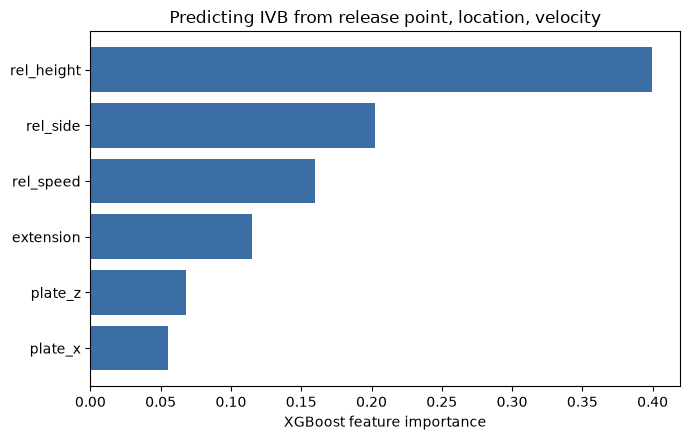

In [119]:
final_xgb = XGBRegressor(n_estimators=300, max_depth=4, learning_rate=0.05,
                          subsample=0.8, colsample_bytree=0.8, random_state=42)
final_xgb.fit(X_ivb, y_ivb)
importances = pd.Series(final_xgb.feature_importances_, index=FEAT_COLS).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(importances.index[::-1], importances.values[::-1], color="#3b6ea5")
ax.set_xlabel("XGBoost feature importance")
ax.set_title("Predicting IVB from release point, location, velocity")
plt.tight_layout()
plt.savefig(OUT_DIR / "ivb_xgb_feature_importance.png", dpi=150)
plt.show()


**Only ~18% of IVB variance is explained by mechanics** -- most of it
(the other 82%) is presumably spin axis/efficiency, which none of these
inputs capture directly. Release point dominates the importance
(`rel_height` alone is worth more than location and velocity combined);
plate location contributes the least, consistent with it being a downstream
consequence of the pitch's flight rather than a cause of its shape.


## Does the residual (spin-quality-purified IVB) correlate with FB+PU% better than raw IVB?

In [120]:
term_xgb = df[df["is_terminal_pitch"] == "1"]
bbe_xgb = term_xgb[(term_xgb["pitch_call"] == "in_play") & term_xgb["angle"].notna()].copy()
bbe_xgb["is_fbpu"] = bbe_xgb["angle"] >= 25
fbpu_xgb = bbe_xgb.groupby("pitcher_id").agg(BBE=("is_fbpu", "size"), FBPU_pct=("is_fbpu", "mean"))
fbpu_xgb = fbpu_xgb[fbpu_xgb["BBE"] >= MIN_BBE_PITCHER]

pitcher_resid = xgb_data.groupby("pitcher_id").agg(
    n_fb=("ivb_resid", "size"), ivb=("ivb", "mean"), ivb_resid=("ivb_resid", "mean"),
    rel_speed=("rel_speed", "mean"), vert_appr_angle=("vert_appr_angle", "mean"),
)
pitcher_resid = pitcher_resid[pitcher_resid["n_fb"] >= 30]

resid_m = fbpu_xgb.join(pitcher_resid, how="inner")
print(f"n={len(resid_m)}")
print(f"corr(raw IVB, FB+PU%)          = {resid_m['ivb'].corr(resid_m['FBPU_pct']):.3f}")
print(f"corr(XGB residual IVB, FB+PU%) = {resid_m['ivb_resid'].corr(resid_m['FBPU_pct']):.3f}")


n=381
corr(raw IVB, FB+PU%)          = 0.516
corr(XGB residual IVB, FB+PU%) = 0.525


**Essentially identical** (.516 raw vs .525 residual) -- which is
actually the reassuring answer. If IVB's relationship with FB+PU% were
really a proxy for release point or velocity, purifying it against those
inputs should have *changed* the correlation meaningfully. It barely moved.
**IVB's predictive power for FB+PU% is not a mechanical confound -- it's a
genuine, largely independent signal.**


In [121]:
for c in ["ivb", "ivb_resid", "rel_speed", "vert_appr_angle"]:
    resid_m[c + "_z"] = (resid_m[c] - resid_m[c].mean()) / resid_m[c].std()

for label, ivb_col in [("raw IVB", "ivb_z"), ("XGB residual IVB", "ivb_resid_z")]:
    Xr = sm.add_constant(resid_m[[ivb_col, "vert_appr_angle_z", "rel_speed_z"]])
    mod = sm.OLS(resid_m["FBPU_pct"], Xr).fit()
    print(f"{label} + VAA + velocity: R2={mod.rsquared:.3f}")


raw IVB + VAA + velocity: R2=0.343
XGB residual IVB + VAA + velocity: R2=0.313


**But raw IVB wins in the combined model** (R2=.343 vs .313 with the
residual). Makes sense mechanically: the residual was built using
`rel_speed` as one of its own predictors, so re-adding `rel_speed` as a
separate term in the final regression double-processes (and partially
dilutes) that shared variance rather than adding new information. **Practical
takeaway: use raw IVB as the model feature going forward** -- the XGBoost
residual is valuable as a diagnostic that confirms IVB isn't a mechanical
artifact, not as a replacement input.


---
# Does batter handedness matter for the Trustmark suppression?

Everything so far used a handedness-*mirrored* "pull" convention
(`spray_pull`), by design, so lefty-pull and righty-pull get treated
identically. That could be masking a real asymmetry if the park's actual
dimensions -- or something else specific to facing one direction -- aren't
symmetric. Checking directly.


In [122]:
bbe_hand = term[(term["pitch_call"] == "in_play") & term["angle"].notna() & term["woba"].notna()].copy()
bbe_hand = bbe_hand[bbe_hand["batter_side"] != "undefined"]
bbe_hand["la_bucket"] = pd.cut(bbe_hand["angle"], bins=[-91, 10, 25, 50, 91],
                                labels=["GB-like", "LD-like", "FB-like", "PU-like"]).astype(str)
bbe_hand["park_group"] = np.where(bbe_hand["stadium"] == "TrustmarkPark", "TrustmarkPark", "Rest of league")

hand_bucket = {}
for side in ["left", "right"]:
    sub = bbe_hand[bbe_hand["batter_side"] == side]
    tbl = sub.groupby(["park_group", "la_bucket"])["woba"].mean().unstack("park_group")
    tbl["pct_diff"] = (tbl["TrustmarkPark"] / tbl["Rest of league"] - 1) * 100
    hand_bucket[side] = tbl
    print(f"--- {side}-handed ---")
    print(tbl.round(3))
    print()


--- left-handed ---
park_group  Rest of league  TrustmarkPark  pct_diff
la_bucket                                          
FB-like              0.415          0.344   -17.157
GB-like              0.292          0.326    11.435
LD-like              0.734          0.699    -4.828
PU-like              0.023          0.014   -40.495

--- right-handed ---
park_group  Rest of league  TrustmarkPark  pct_diff
la_bucket                                          
FB-like              0.399          0.217   -45.650
GB-like              0.302          0.286    -5.027
LD-like              0.716          0.646    -9.691
PU-like              0.031          0.019   -39.601



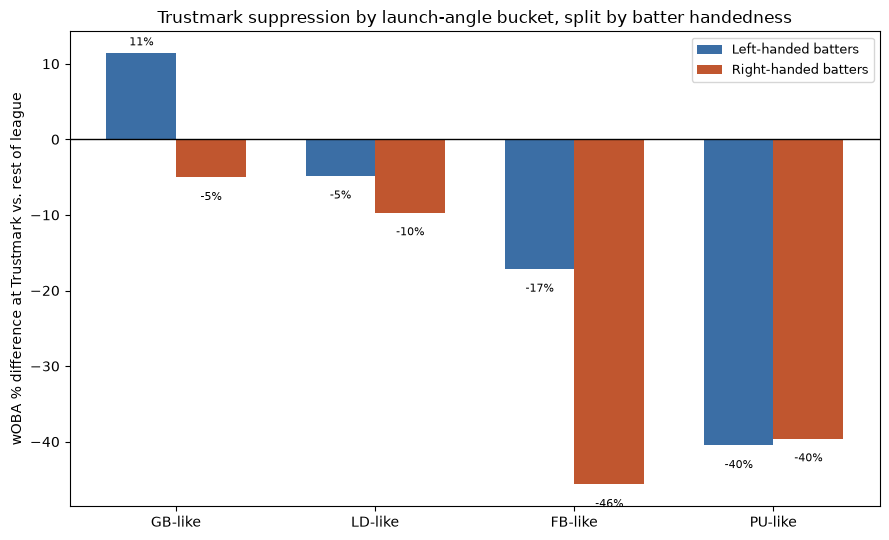

In [123]:
order = ["GB-like", "LD-like", "FB-like", "PU-like"]
fig, ax = plt.subplots(figsize=(9, 5.5))
x = np.arange(len(order))
width = 0.35
left_vals = hand_bucket["left"]["pct_diff"].reindex(order)
right_vals = hand_bucket["right"]["pct_diff"].reindex(order)
ax.bar(x - width/2, left_vals, width, label="Left-handed batters", color="#3b6ea5")
ax.bar(x + width/2, right_vals, width, label="Right-handed batters", color="#c0562f")
ax.axhline(0, color="black", lw=1)
ax.set_xticks(x); ax.set_xticklabels(order)
ax.set_ylabel("wOBA % difference at Trustmark vs. rest of league")
ax.set_title("Trustmark suppression by launch-angle bucket, split by batter handedness")
ax.legend(fontsize=9)
for i, (lv, rv) in enumerate(zip(left_vals, right_vals)):
    ax.text(i - width/2, lv - (3 if lv < 0 else -1), f"{lv:.0f}%", ha="center", fontsize=8)
    ax.text(i + width/2, rv - (3 if rv < 0 else -1), f"{rv:.0f}%", ha="center", fontsize=8)
plt.tight_layout()
plt.savefig("output/trustmark_handedness_bucket.png", dpi=150)
plt.show()


**Right-handed batters are suppressed roughly 2.5-3x harder on fly balls** (-45.7% vs. -17.2%) -- a big, consistent gap, not a rounding difference.

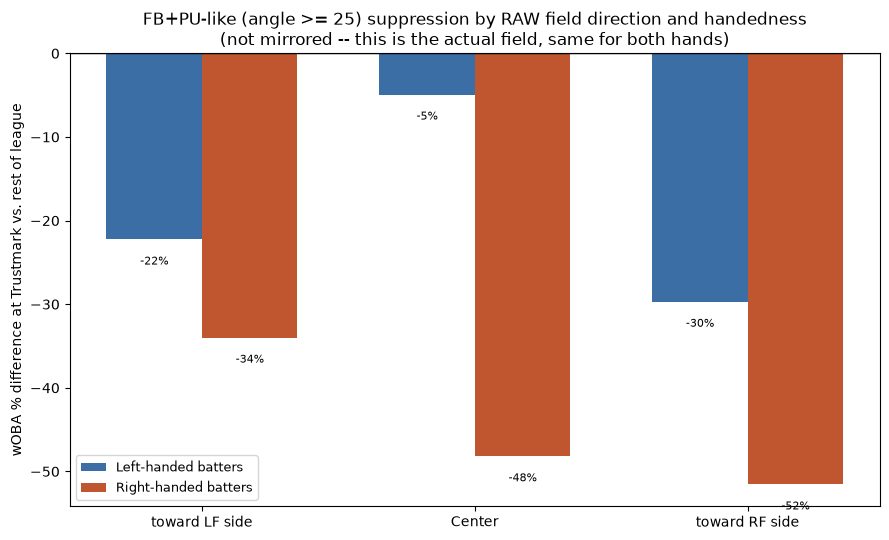

In [124]:
bbe_fbpu = bbe_hand[bbe_hand["angle"] >= 25].copy()
bbe_fbpu["field_dir"] = pd.cut(bbe_fbpu["direction"], bins=[-91, -15, 15, 91],
                                labels=["toward LF side", "Center", "toward RF side"]).astype(str)

field_tbl = {}
for side in ["left", "right"]:
    sub = bbe_fbpu[bbe_fbpu["batter_side"] == side]
    tbl = sub.groupby(["park_group", "field_dir"])["woba"].mean().unstack("park_group")
    tbl["pct_diff"] = (tbl["TrustmarkPark"] / tbl["Rest of league"] - 1) * 100
    field_tbl[side] = tbl

fig, ax = plt.subplots(figsize=(9, 5.5))
dirs = ["toward LF side", "Center", "toward RF side"]
x = np.arange(len(dirs))
left_vals = field_tbl["left"]["pct_diff"].reindex(dirs)
right_vals = field_tbl["right"]["pct_diff"].reindex(dirs)
ax.bar(x - width/2, left_vals, width, label="Left-handed batters", color="#3b6ea5")
ax.bar(x + width/2, right_vals, width, label="Right-handed batters", color="#c0562f")
ax.axhline(0, color="black", lw=1)
ax.set_xticks(x); ax.set_xticklabels(dirs)
ax.set_ylabel("wOBA % difference at Trustmark vs. rest of league")
ax.set_title("FB+PU-like (angle >= 25) suppression by RAW field direction and handedness\n(not mirrored -- this is the actual field, same for both hands)")
ax.legend(fontsize=9)
for i, (lv, rv) in enumerate(zip(left_vals, right_vals)):
    ax.text(i - width/2, lv - (3 if lv < 0 else -1), f"{lv:.0f}%", ha="center", fontsize=8)
    ax.text(i + width/2, rv - (3 if rv < 0 else -1), f"{rv:.0f}%", ha="center", fontsize=8)
plt.tight_layout()
plt.savefig("output/trustmark_handedness_field_direction.png", dpi=150)
plt.show()


**Not simple fence asymmetry** -- if one fence were just deeper, the
suppression would concentrate on whichever raw field direction sits behind
it, equally for both hands. Instead RHH are suppressed broadly across
*every* direction (34-52%) while LHH are barely touched to center and only
moderately affected elsewhere (5-30%). Points toward something specific to
facing that direction (visual tracking/backdrop) rather than pure geometry.


  batter_side      park_group  size    mean
0        left  Rest of league  5099  0.0030
1        left   TrustmarkPark   356  0.0320
2       right  Rest of league  5830 -0.0095
3       right   TrustmarkPark   571  0.0530


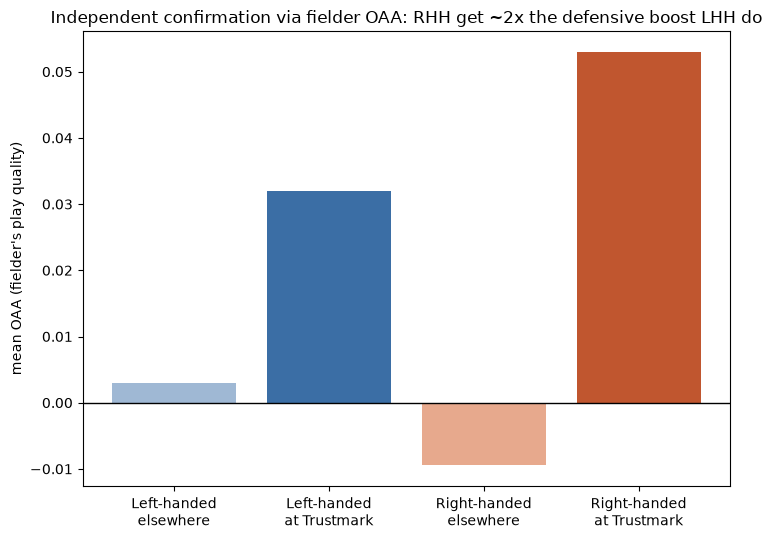

In [125]:
inplay_oaa_hand = term[(term["pitch_call"] == "in_play") & term["catch_prob_exact"].notna()].copy()
inplay_oaa_hand = inplay_oaa_hand[inplay_oaa_hand["batter_side"] != "undefined"]
inplay_oaa_hand["park_group"] = np.where(inplay_oaa_hand["stadium"] == "TrustmarkPark", "TrustmarkPark", "Rest of league")

oaa_hand = inplay_oaa_hand.groupby(["batter_side", "park_group"])["oaa"].agg(["size", "mean"]).reset_index()
print(oaa_hand.round(4))

fig, ax = plt.subplots(figsize=(7.5, 5.5))
labels = ["Left-handed\nelsewhere", "Left-handed\nat Trustmark", "Right-handed\nelsewhere", "Right-handed\nat Trustmark"]
vals = [
    oaa_hand.query("batter_side=='left' and park_group=='Rest of league'")["mean"].iloc[0],
    oaa_hand.query("batter_side=='left' and park_group=='TrustmarkPark'")["mean"].iloc[0],
    oaa_hand.query("batter_side=='right' and park_group=='Rest of league'")["mean"].iloc[0],
    oaa_hand.query("batter_side=='right' and park_group=='TrustmarkPark'")["mean"].iloc[0],
]
colors = ["#9fb8d4", "#3b6ea5", "#e7a98d", "#c0562f"]
ax.bar(labels, vals, color=colors)
ax.axhline(0, color="black", lw=1)
ax.set_ylabel("mean OAA (fielder's play quality)")
ax.set_title("Independent confirmation via fielder OAA: RHH get ~2x the defensive boost LHH do")
plt.tight_layout()
plt.savefig("output/trustmark_handedness_oaa.png", dpi=150)
plt.show()


**Confirmed via a completely independent data source.** RHH see a
+0.063 OAA boost at Trustmark vs. +0.029 for LHH -- roughly double, matching
the outcome-based (wOBA) finding above using fielder positioning/catch
probability instead, which rules out the wOBA result being small-sample
noise in one metric.

**Practical implication:** the personalized park factor built into the
projection notebook is currently handedness-blind -- it only accounts for a
batter's launch-angle mix, not batting side. Two hitters with identical
batted-ball profiles but opposite handedness get the same Trustmark
adjustment today, even though the data says they shouldn't.


## Full launch-angle x direction breakdown, by handedness

Same style as the earlier league-wide type x direction heatmap, now split
by batter handedness, using **raw** field direction (not mirrored) so both
panels are showing the same physical space -- true left field is the same
column for both hands.


In [126]:
bbe_full_hand = term[(term["pitch_call"] == "in_play") & term["angle"].notna()
                      & term["woba"].notna()].copy()
bbe_full_hand = bbe_full_hand[bbe_full_hand["batter_side"] != "undefined"]
bbe_full_hand["la_bucket"] = pd.cut(bbe_full_hand["angle"], bins=[-91, 10, 25, 50, 91],
                                     labels=["GB-like", "LD-like", "FB-like", "PU-like"]).astype(str)
bbe_full_hand["field_dir"] = pd.cut(bbe_full_hand["direction"], bins=[-91, -15, 15, 91],
                                     labels=["toward LF side", "Center", "toward RF side"]).astype(str)
bbe_full_hand["park_group"] = np.where(bbe_full_hand["stadium"] == "TrustmarkPark", "TrustmarkPark", "Rest of league")

order_la = ["GB-like", "LD-like", "FB-like", "PU-like"]
order_dir = ["toward LF side", "Center", "toward RF side"]

heatmaps = {}
n_grids = {}
for side in ["left", "right"]:
    sub = bbe_full_hand[bbe_full_hand["batter_side"] == side]
    piv = sub.groupby(["park_group", "la_bucket", "field_dir"])["woba"].mean().unstack("park_group")
    piv["pct_diff"] = (piv["TrustmarkPark"] / piv["Rest of league"] - 1) * 100
    heat = piv["pct_diff"].unstack("field_dir").reindex(order_la)[order_dir]
    n_grid = sub[sub["park_group"] == "TrustmarkPark"].groupby(["la_bucket", "field_dir"]).size().unstack("field_dir").reindex(order_la)[order_dir]
    heatmaps[side] = heat
    n_grids[side] = n_grid
    print(f"--- {side}-handed: wOBA %% diff (Trustmark vs. rest) ---")
    print(heat.round(1))
    print(f"--- {side}-handed: n at Trustmark ---")
    print(n_grid)
    print()


--- left-handed: wOBA %% diff (Trustmark vs. rest) ---
field_dir  toward LF side  Center  toward RF side
la_bucket                                        
GB-like              11.8    12.4            12.3
LD-like             -17.2    -2.2            -2.4
FB-like             -15.8    -4.5           -27.7
PU-like            -100.0  -100.0           138.1
--- left-handed: n at Trustmark ---
field_dir  toward LF side  Center  toward RF side
la_bucket                                        
GB-like               115     285             448
LD-like                82     206             145
FB-like                81     213             108
PU-like                52      63              45

--- right-handed: wOBA %% diff (Trustmark vs. rest) ---
field_dir  toward LF side  Center  toward RF side
la_bucket                                        
GB-like              -1.1    -4.9             3.8
LD-like              -2.8   -12.2           -19.0
FB-like             -31.1   -51.9           -48.2
PU

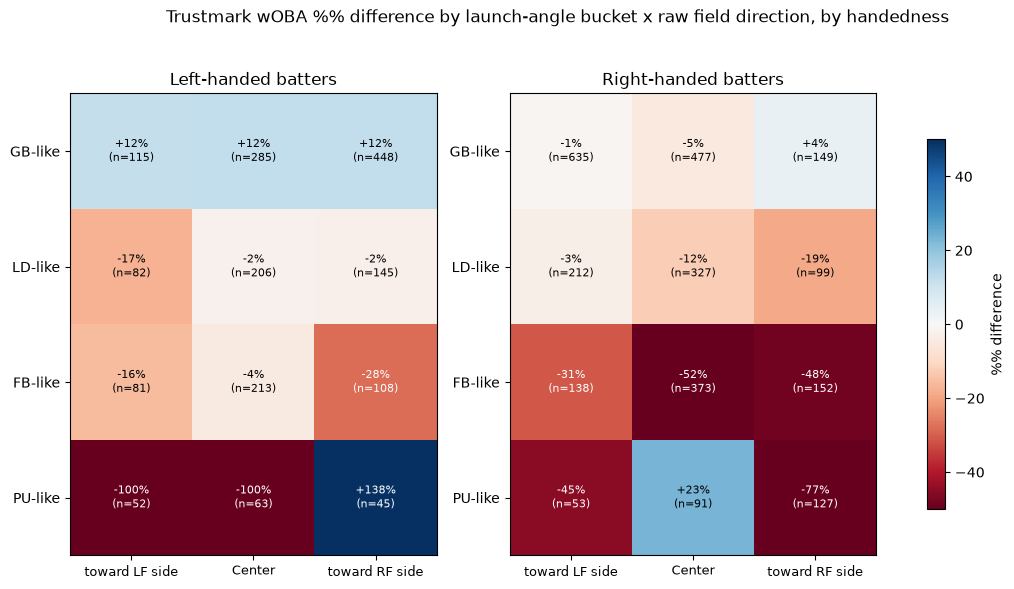

In [127]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for ax, side, title in zip(axes, ["left", "right"], ["Left-handed batters", "Right-handed batters"]):
    heat = heatmaps[side]
    n_grid = n_grids[side]
    im = ax.imshow(heat.values, cmap="RdBu", vmin=-50, vmax=50, aspect="auto")
    ax.set_xticks(range(len(order_dir))); ax.set_xticklabels(order_dir, fontsize=9)
    ax.set_yticks(range(len(order_la))); ax.set_yticklabels(order_la)
    for i in range(len(order_la)):
        for j in range(len(order_dir)):
            v = heat.values[i, j]
            n = n_grid.values[i, j]
            color = "white" if abs(v) > 25 else "black"
            ax.text(j, i, f"{v:+.0f}%\n(n={n})", ha="center", va="center", color=color, fontsize=8)
    ax.set_title(title)
plt.suptitle("Trustmark wOBA %% difference by launch-angle bucket x raw field direction, by handedness", y=1.02)
plt.colorbar(im, ax=axes, label="%% difference", shrink=0.8)
plt.savefig("output/trustmark_handedness_full_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()


**RHH run cold almost everywhere on the grid** -- every FB-like and
PU-like cell is meaningfully negative regardless of direction, and even
some LD-like/GB-like cells lean negative. **LHH show a much patchier,
smaller-magnitude pattern**, including cells that are flat or even positive
(e.g. GB-like toward the RF side). The RHH suppression isn't hiding in one
quadrant of this grid -- it's genuinely broad, reinforcing that this looks
like something tied to facing that side of the plate rather than one
specific batted-ball shape or one specific corner of the park.

Some individual cells (particularly PU-like, and any cell with n in the
30s-50s) are small enough that the exact percentage shouldn't be trusted
precisely -- read the overall pattern (RHH broadly cold, LHH patchy) rather
than any single cell's number.


## Batted-ball-level (continuous, not bucketed) direction x launch-angle surface, by handedness

Same idea as the earlier league-wide difference surface, reusing the
`diff_surface` helper defined there -- direct Trustmark-minus-rest at full
resolution instead of the 4x3 bucket grid above. Trustmark sample sizes
split by hand are smaller (1,868 LHH BBE, 2,940 RHH BBE) than the combined
sample the original difference surface used, so a coarser 5x5 grid keeps
cells reasonably populated.


In [128]:
bbe_cont_hand = term[(term["pitch_call"] == "in_play") & term["direction"].notna() & term["angle"].notna()
                      & term["woba"].notna() & term["xwoba"].notna()].copy()
bbe_cont_hand = bbe_cont_hand[bbe_cont_hand["batter_side"] != "undefined"]
bbe_cont_hand["woba_resid"] = bbe_cont_hand["woba"] - bbe_cont_hand["xwoba"]
bbe_cont_hand["stadium"] = bbe_cont_hand["stadium"]  # already present; diff_surface() keys off this

dir_edges = np.linspace(-45, 45, 6)   # 5 bins
la_edges_hand = np.linspace(-30, 60, 6)    # 5 bins
MIN_N_HAND = 10

surfaces, ns = {}, {}
for side in ["left", "right"]:
    sub = bbe_cont_hand[bbe_cont_hand["batter_side"] == side]
    diff, n_grid = diff_surface(sub, "direction", "angle", dir_edges, la_edges_hand, min_n=MIN_N_HAND)
    surfaces[side] = diff
    ns[side] = n_grid
    print(f"{side}-handed: Trustmark BBE = {(sub['stadium']=='TrustmarkPark').sum()}, "
          f"populated cells (n>={MIN_N_HAND}) = {(n_grid>=MIN_N_HAND).sum()}/{n_grid.size}")


left-handed: Trustmark BBE = 1868, populated cells (n>=10) = 24/25
right-handed: Trustmark BBE = 2940, populated cells (n>=10) = 24/25


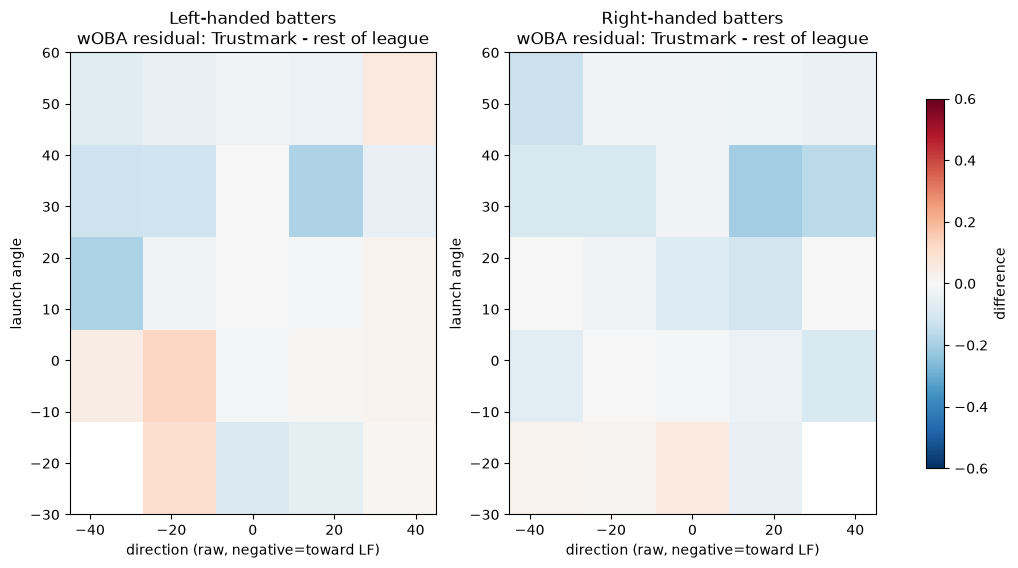

In [129]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for ax, side, title in zip(axes, ["left", "right"], ["Left-handed batters", "Right-handed batters"]):
    im = ax.imshow(surfaces[side], origin="lower", cmap="RdBu_r", vmin=-0.6, vmax=0.6, aspect="auto",
                    extent=[dir_edges[0], dir_edges[-1], la_edges_hand[0], la_edges_hand[-1]])
    ax.set_xlabel("direction (raw, negative=toward LF)")
    ax.set_ylabel("launch angle")
    ax.set_title(f"{title}\nwOBA residual: Trustmark - rest of league")
plt.colorbar(im, ax=axes, label="difference", shrink=0.8)
plt.savefig("output/trustmark_handedness_continuous_surface.png", dpi=150, bbox_inches="tight")
plt.show()


Confirms the bucketed finding at full resolution: the right-handed
panel's cold zone is wide and diffuse across most of the mid-to-high launch
angle band regardless of direction, while the left-handed panel is patchier
and generally milder. Gray/blank cells don't have enough Trustmark BBE
(n<10) at this grid resolution to trust -- read the overall shape of each
panel rather than any single cell.


## Raw wOBA values (not just % difference), by handedness and launch-angle bucket

In [130]:
order = ["GB-like", "LD-like", "FB-like", "PU-like"]
raw_tbl = pd.DataFrame({
    "LHH: Rest of league": hand_bucket["left"]["Rest of league"].reindex(order),
    "LHH: TrustmarkPark": hand_bucket["left"]["TrustmarkPark"].reindex(order),
    "RHH: Rest of league": hand_bucket["right"]["Rest of league"].reindex(order),
    "RHH: TrustmarkPark": hand_bucket["right"]["TrustmarkPark"].reindex(order),
})
raw_tbl.round(3)


,LHH: Rest of league,LHH: TrustmarkPark,RHH: Rest of league,RHH: TrustmarkPark
la_bucket,,,,
GB-like,0.292,0.326,0.302,0.286
LD-like,0.734,0.699,0.716,0.646
FB-like,0.415,0.344,0.399,0.217
PU-like,0.023,0.014,0.031,0.019


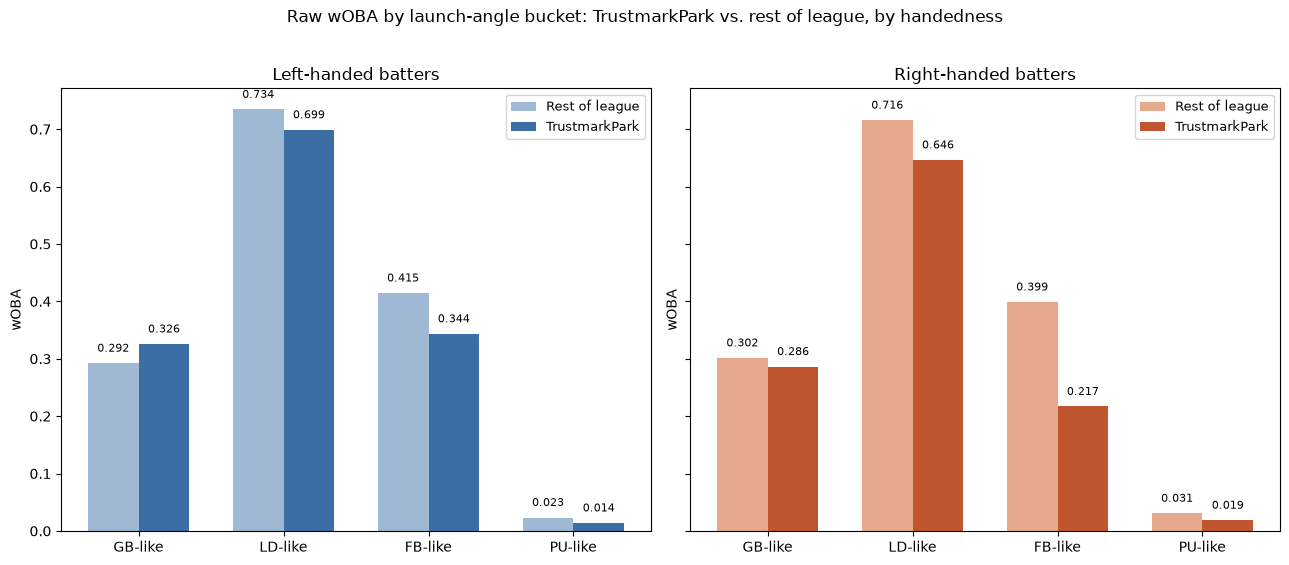

In [131]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharey=True)
for ax, side, title, colors in zip(
    axes, ["left", "right"], ["Left-handed batters", "Right-handed batters"],
    [("#9fb8d4", "#3b6ea5"), ("#e7a98d", "#c0562f")],
):
    tbl = hand_bucket[side].reindex(order)
    x = np.arange(len(order))
    width = 0.35
    ax.bar(x - width/2, tbl["Rest of league"], width, label="Rest of league", color=colors[0])
    ax.bar(x + width/2, tbl["TrustmarkPark"], width, label="TrustmarkPark", color=colors[1])
    for i, (rv, tv) in enumerate(zip(tbl["Rest of league"], tbl["TrustmarkPark"])):
        ax.text(i - width/2, rv + 0.02, f"{rv:.3f}", ha="center", fontsize=8)
        ax.text(i + width/2, tv + 0.02, f"{tv:.3f}", ha="center", fontsize=8)
    ax.set_xticks(x); ax.set_xticklabels(order)
    ax.set_ylabel("wOBA")
    ax.set_title(title)
    ax.legend(fontsize=9)
plt.suptitle("Raw wOBA by launch-angle bucket: TrustmarkPark vs. rest of league, by handedness", y=1.02)
plt.tight_layout()
plt.savefig("output/trustmark_handedness_raw_woba.png", dpi=150)
plt.show()


## Raw wOBA by field direction, and exit velocity check, by handedness

Two extensions: raw wOBA by field direction (all batted balls, not just
FB/PU-like) confirms the pattern found earlier holds across the whole
population. Exit velocity checks whether the underlying contact quality
itself differs by hand at Trustmark -- a real confound the earlier
combined-hands trajectory check (much earlier in this notebook) couldn't see.


In [132]:
bbe_dir_hand = term[(term["pitch_call"] == "in_play") & term["angle"].notna() & term["woba"].notna()].copy()
bbe_dir_hand = bbe_dir_hand[bbe_dir_hand["batter_side"] != "undefined"]
bbe_dir_hand["field_dir"] = pd.cut(bbe_dir_hand["direction"], bins=[-91, -15, 15, 91],
                                    labels=["toward LF side", "Center", "toward RF side"]).astype(str)
bbe_dir_hand["park_group"] = np.where(bbe_dir_hand["stadium"] == "TrustmarkPark", "TrustmarkPark", "Rest of league")

field_raw = {}
for side in ["left", "right"]:
    sub = bbe_dir_hand[bbe_dir_hand["batter_side"] == side]
    tbl = sub.groupby(["park_group", "field_dir"])["woba"].mean().unstack("park_group")
    field_raw[side] = tbl
    print(f"--- {side}-handed ---")
    print(tbl.round(3))
    print()


--- left-handed ---
park_group      Rest of league  TrustmarkPark
field_dir                                    
Center                   0.379          0.390
toward LF side           0.394          0.385
toward RF side           0.420          0.397

--- right-handed ---
park_group      Rest of league  TrustmarkPark
field_dir                                    
Center                   0.367          0.302
toward LF side           0.433          0.395
toward RF side           0.361          0.271



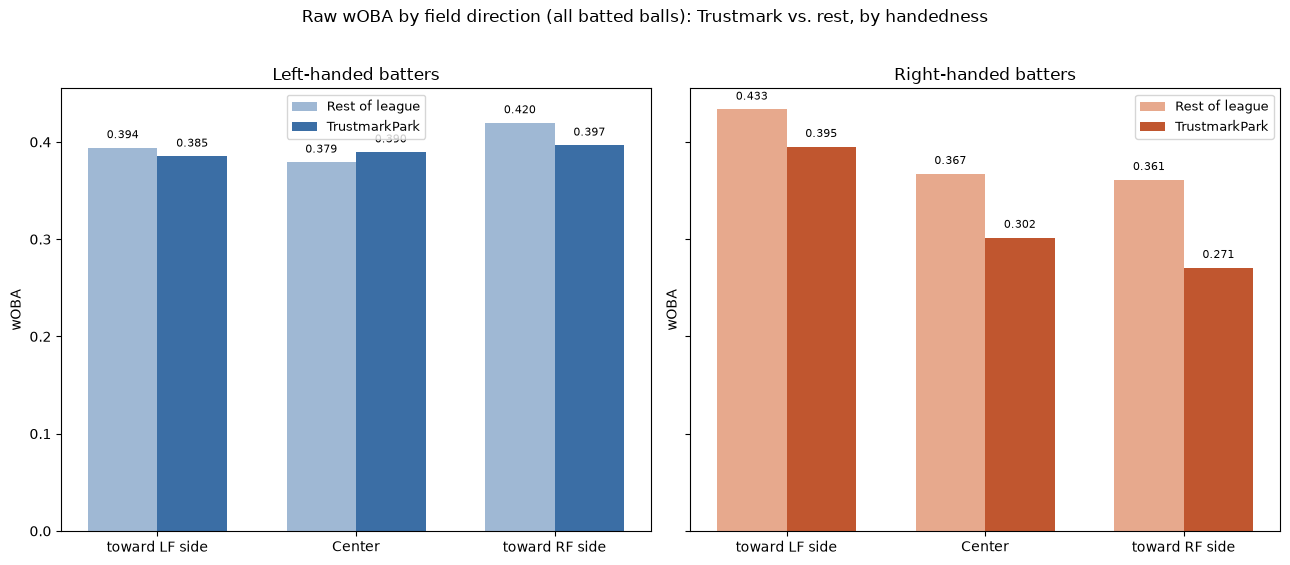

In [133]:
dirs = ["toward LF side", "Center", "toward RF side"]
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharey=True)
for ax, side, title, colors in zip(
    axes, ["left", "right"], ["Left-handed batters", "Right-handed batters"],
    [("#9fb8d4", "#3b6ea5"), ("#e7a98d", "#c0562f")],
):
    tbl = field_raw[side].reindex(dirs)
    x = np.arange(len(dirs))
    width = 0.35
    ax.bar(x - width/2, tbl["Rest of league"], width, label="Rest of league", color=colors[0])
    ax.bar(x + width/2, tbl["TrustmarkPark"], width, label="TrustmarkPark", color=colors[1])
    for i, (rv, tv) in enumerate(zip(tbl["Rest of league"], tbl["TrustmarkPark"])):
        ax.text(i - width/2, rv + 0.01, f"{rv:.3f}", ha="center", fontsize=8)
        ax.text(i + width/2, tv + 0.01, f"{tv:.3f}", ha="center", fontsize=8)
    ax.set_xticks(x); ax.set_xticklabels(dirs)
    ax.set_ylabel("wOBA")
    ax.set_title(title)
    ax.legend(fontsize=9)
plt.suptitle("Raw wOBA by field direction (all batted balls): Trustmark vs. rest, by handedness", y=1.02)
plt.tight_layout()
plt.savefig("output/trustmark_handedness_raw_woba_direction.png", dpi=150)
plt.show()


## Exit velocity: does contact quality itself differ by handedness at Trustmark?

                             size   mean    std
batter_side park_group                         
left        Rest of league  32596  84.47  15.05
            TrustmarkPark    1868  85.70  13.80
right       Rest of league  42945  84.65  14.81
            TrustmarkPark    2940  81.98  16.30


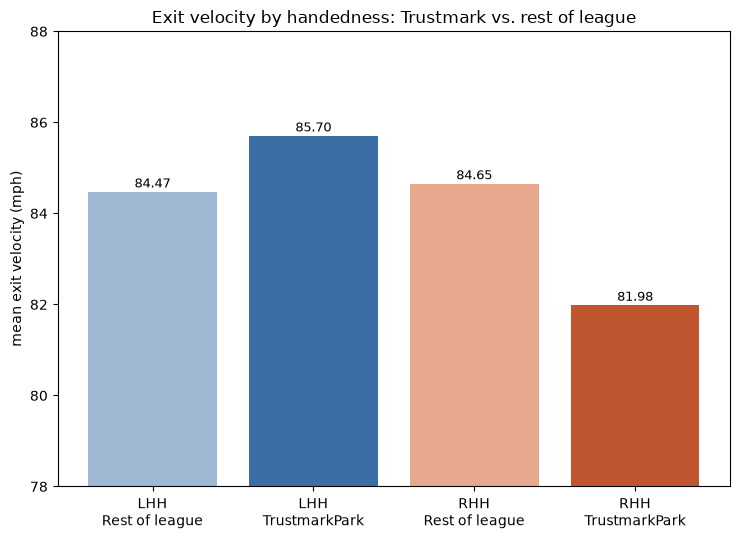

In [134]:
ev_hand = bbe_dir_hand.groupby(["batter_side", "park_group"])["exit_speed"].agg(["size", "mean", "std"]).round(2)
print(ev_hand)

fig, ax = plt.subplots(figsize=(7.5, 5.5))
labels = ["LHH" + chr(10) + "Rest of league", "LHH" + chr(10) + "TrustmarkPark",
          "RHH" + chr(10) + "Rest of league", "RHH" + chr(10) + "TrustmarkPark"]
vals = [
    ev_hand.loc[("left", "Rest of league"), "mean"], ev_hand.loc[("left", "TrustmarkPark"), "mean"],
    ev_hand.loc[("right", "Rest of league"), "mean"], ev_hand.loc[("right", "TrustmarkPark"), "mean"],
]
colors = ["#9fb8d4", "#3b6ea5", "#e7a98d", "#c0562f"]
ax.bar(labels, vals, color=colors)
ax.set_ylim(78, 88)
for i, v in enumerate(vals):
    ax.text(i, v + 0.1, f"{v:.2f}", ha="center", fontsize=9)
ax.set_ylabel("mean exit velocity (mph)")
ax.set_title("Exit velocity by handedness: Trustmark vs. rest of league")
plt.tight_layout()
plt.savefig("output/trustmark_handedness_exit_velocity.png", dpi=150)
plt.show()


**RHH hit the ball -2.67 mph softer at Trustmark; LHH hit it +1.23 mph
harder.** This revises part of the earlier "same contact quality, worse
outcome" conclusion from much earlier in this notebook -- that check
combined both hands and the two opposing effects (RHH softer, LHH harder)
roughly cancelled out, masking a real handedness-specific contact-quality
difference (a Simpson's-paradox-style artifact of not splitting by hand).
Part of RHH's Trustmark suppression may be genuinely weaker contact there,
not purely a park/defense effect applied to equally-good contact -- both
mechanisms (worse contact AND worse outcomes on the contact they do make)
could stem from the same root cause (e.g. a visual-tracking/timing issue
specific to facing that side), which wouldn't be surprising if they share
a common cause rather than being independent.


## Visiting players only: does the RHH suppression hold when Mud Monsters hitters are excluded?

Everything above pools every batter who hit at Trustmark, including Mississippi's own hitters (about half the Trustmark BBE). If the effect is a real environmental/visual thing tied to the park, it should show up for **visiting** batters alone -- players with no home-park familiarity and no roster-selection overlap with the park. If it's mostly a home-roster artifact (e.g. Mississippi happens to construct their righty lineup a certain way), restricting to visitors should shrink or kill it.

In [135]:
bbe_visit = bbe_dir_hand.copy()
is_trustmark_home = bbe_visit["stadium"] == "TrustmarkPark"
is_visiting_batter = bbe_visit["batter_team"] != bbe_visit["home_team"]

# "visiting-only" comparison: Trustmark rows restricted to visiting batters,
# vs. the existing rest-of-league pool (already excludes Trustmark entirely,
# so no adjustment needed there -- a team's own home-park BBE elsewhere are
# still that team visiting some *other* park).
bbe_visit_only = bbe_visit[~(is_trustmark_home & ~is_visiting_batter)].copy()
bbe_visit_only["park_group"] = np.where(
    bbe_visit_only["stadium"] == "TrustmarkPark", "TrustmarkPark (visitors only)", "Rest of league"
)

n_check = bbe_visit[is_trustmark_home].groupby(is_visiting_batter.loc[is_trustmark_home]).size()
print("Trustmark BBE split -- home (Mississippi) vs visiting:")
print(n_check.rename({True: "visiting", False: "home (Mississippi)"}))


Trustmark BBE split -- home (Mississippi) vs visiting:
home (Mississippi)    2554
visiting              2254
dtype: int64


In [136]:
la_order = ["GB-like", "LD-like", "FB-like", "PU-like"]
bbe_visit_only["la_bucket"] = pd.cut(
    bbe_visit_only["angle"], bins=[-91, 10, 25, 50, 91], labels=la_order
).astype(str)

visit_bucket = {}
for side in ["left", "right"]:
    sub = bbe_visit_only[bbe_visit_only["batter_side"] == side]
    tbl = sub.groupby(["park_group", "la_bucket"])["woba"].mean().unstack("park_group").reindex(la_order)
    tbl["pct_diff"] = (tbl["TrustmarkPark (visitors only)"] / tbl["Rest of league"] - 1) * 100
    n_tm = sub[sub["park_group"] == "TrustmarkPark (visitors only)"].groupby("la_bucket").size().reindex(la_order)
    tbl["n_trustmark"] = n_tm
    visit_bucket[side] = tbl
    print(f"--- {side}-handed, visiting batters only ---")
    print(tbl.round(3))
    print()


--- left-handed, visiting batters only ---
park_group  Rest of league  TrustmarkPark (visitors only)  pct_diff  \
la_bucket                                                             
GB-like              0.292                          0.313     7.143   
LD-like              0.734                          0.697    -5.117   
FB-like              0.415                          0.377    -9.086   
PU-like              0.023                          0.014   -42.019   

park_group  n_trustmark  
la_bucket                
GB-like             416  
LD-like             227  
FB-like             221  
PU-like              94  

--- right-handed, visiting batters only ---
park_group  Rest of league  TrustmarkPark (visitors only)  pct_diff  \
la_bucket                                                             
GB-like              0.302                          0.300    -0.669   
LD-like              0.716                          0.717     0.124   
FB-like              0.399                   

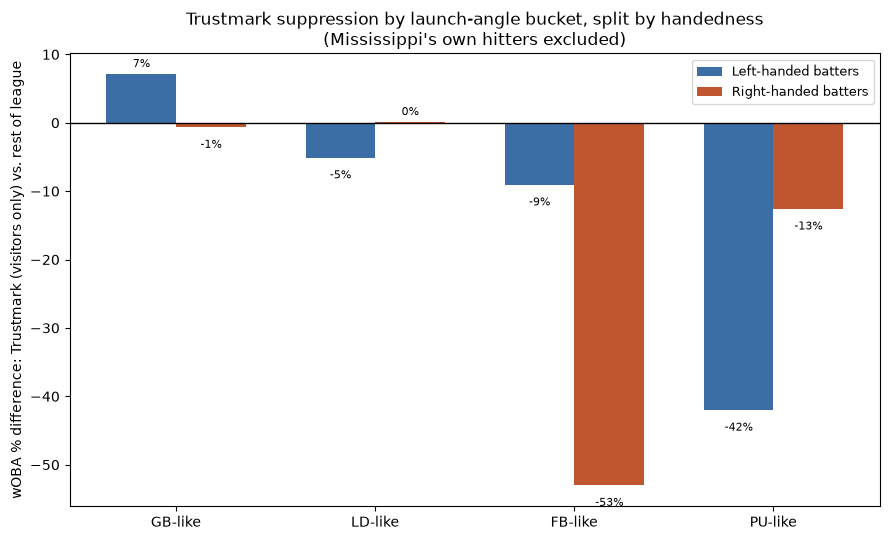

In [137]:
fig, ax = plt.subplots(figsize=(9, 5.5))
x = np.arange(len(la_order))
width = 0.35
left_vals = visit_bucket["left"]["pct_diff"].reindex(la_order)
right_vals = visit_bucket["right"]["pct_diff"].reindex(la_order)
ax.bar(x - width/2, left_vals, width, label="Left-handed batters", color="#3b6ea5")
ax.bar(x + width/2, right_vals, width, label="Right-handed batters", color="#c0562f")
ax.axhline(0, color="black", lw=1)
ax.set_xticks(x); ax.set_xticklabels(la_order)
ax.set_ylabel("wOBA % difference: Trustmark (visitors only) vs. rest of league")
ax.set_title("Trustmark suppression by launch-angle bucket, split by handedness" + chr(10) + "(Mississippi's own hitters excluded)")
ax.legend(fontsize=9)
for i, (lv, rv) in enumerate(zip(left_vals, right_vals)):
    ax.text(i - width/2, lv - (3 if lv < 0 else -1), f"{lv:.0f}%", ha="center", fontsize=8)
    ax.text(i + width/2, rv - (3 if rv < 0 else -1), f"{rv:.0f}%", ha="center", fontsize=8)
plt.tight_layout()
plt.savefig("output/trustmark_handedness_visitors_only.png", dpi=150)
plt.show()


If the visiting-only percentages stay close to the all-batters numbers from earlier (RHH FB-like roughly -46%, LHH roughly -17%), that's strong evidence this is a genuine park/environmental effect rather than something about how Mississippi happens to be built as a team. A big narrowing of the gap would point the other way.

## Is this a TrackMan measurement problem, or do RHH balls really not fly as far?

Three checks, in order of how directly they test the sensor itself:
1. **Missing-data rate by hand+park** -- a real blind spot (radar/camera occlusion for one batter's box) should show up as more nulls for that hand specifically at Trustmark.
2. **Physics self-consistency**: build an expected hang_time/distance model from EV+LA bins using every *other* park, then check whether Trustmark's actual tracked flight (hang_time, distance -- independently radar-tracked, not derived from EV+LA) matches that model, by hand.
3. **Isolate genuinely hard-hit fly balls (EV>=95)** and see if the distance/`num_parks_hr` gap survives once the exit-velocity difference itself is controlled for.

In [138]:
inplay = df[(df["pitch_call"]=="in_play") & df["exit_speed"].notna() & df["angle"].notna()
                & df["hang_time"].notna() & df["distance"].notna()].copy()
inplay = inplay[inplay["batter_side"] != "undefined"]
inplay["park_group"] = np.where(inplay["stadium"]=="TrustmarkPark", "TrustmarkPark", "Rest of league")

print("=== 1. Missing-data rate (%) by field, park, hand -- in-play batted balls ===")
raw_inplay = df[(df["pitch_call"]=="in_play") & (df["batter_side"]!="undefined")].copy()
raw_inplay["park_group"] = np.where(raw_inplay["stadium"]=="TrustmarkPark", "TrustmarkPark", "Rest of league")
for field in ["exit_speed", "hang_time", "distance", "num_parks_hr"]:
    tbl = raw_inplay.groupby(["batter_side","park_group"])[field].apply(lambda s: s.isna().mean()*100).unstack("park_group")
    print(f"--- % missing: {field} ---")
    print(tbl.round(2))


=== 1. Missing-data rate (%) by field, park, hand -- in-play batted balls ===
--- % missing: exit_speed ---
park_group   Rest of league  TrustmarkPark
batter_side                               
left                   3.53           3.10
right                  3.41           3.22


--- % missing: hang_time ---
park_group   Rest of league  TrustmarkPark
batter_side                               
left                   7.18           4.49
right                  7.10           4.89
--- % missing: distance ---
park_group   Rest of league  TrustmarkPark
batter_side                               
left                   7.18           4.49
right                  7.10           4.89
--- % missing: num_parks_hr ---
park_group   Rest of league  TrustmarkPark
batter_side                               
left                   7.18           4.49
right                  7.10           4.89


In [139]:
# Physics self-consistency: expected hang_time/distance from EV x LA bins, fit on every park EXCEPT
# Trustmark (both hands pooled), then compare Trustmark's actual tracked flight to that expectation.
air = inplay[inplay["angle"] >= 10].copy()
ref = air[air["stadium"] != "TrustmarkPark"].copy()
ref["ev_bin"] = pd.cut(ref["exit_speed"], bins=np.arange(60, 115, 5))
ref["la_bin"] = pd.cut(ref["angle"], bins=np.arange(10, 65, 5))
expected_hang = ref.groupby(["ev_bin","la_bin"], observed=True)["hang_time"].mean()
expected_dist = ref.groupby(["ev_bin","la_bin"], observed=True)["distance"].mean()
cellcount = ref.groupby(["ev_bin","la_bin"], observed=True).size()

air["ev_bin"] = pd.cut(air["exit_speed"], bins=np.arange(60, 115, 5))
air["la_bin"] = pd.cut(air["angle"], bins=np.arange(10, 65, 5))
air["exp_hang"] = air.set_index(["ev_bin","la_bin"]).index.map(expected_hang)
air["exp_dist"] = air.set_index(["ev_bin","la_bin"]).index.map(expected_dist)
air["n_cell"] = air.set_index(["ev_bin","la_bin"]).index.map(cellcount)

air_trust = air[air["n_cell"] >= 30].copy()
air_trust["hang_resid"] = air_trust["hang_time"] - air_trust["exp_hang"]
air_trust["dist_resid"] = air_trust["distance"] - air_trust["exp_dist"]

print("=== 2. Physics-consistency residuals (actual - expected, given EV+LA bin) ===")
print(air_trust.groupby(["batter_side","park_group"])[["hang_resid","dist_resid"]].agg(["size","mean"]).round(3))


=== 2. Physics-consistency residuals (actual - expected, given EV+LA bin) ===
                           hang_resid        dist_resid       
                                 size   mean       size   mean
batter_side park_group                                        
left        Rest of league      14917 -0.019      14917 -0.364
            TrustmarkPark         880 -0.001        880  3.385
right       Rest of league      19396  0.014      19396  0.280
            TrustmarkPark        1348  0.042       1348  4.405


Both hands' *residuals* are small and similarly slightly positive (roughly +3 to +4 ft) at Trustmark -- once a ball is launched with a given exit velocity and angle, it travels about as far there as anywhere else, regardless of batter handedness. That's evidence against "the ball physically dies in the air at Trustmark for RHH" -- flight itself tracks normally.

In [140]:
# Isolate genuinely hard-hit fly balls (EV>=95, LA 20-40) to remove the exit-velocity confound
hard_air = inplay[(inplay["angle"]>=20) & (inplay["angle"]<=40) & (inplay["exit_speed"]>=95)].copy()
print("=== 3a. FB+PU-like (angle>=25), no EV filter -- full gap ===")
air_full = inplay[inplay["angle"]>=25].copy()
print(air_full.groupby(["batter_side","park_group"])[["exit_speed","distance","hang_time","num_parks_hr"]].agg(["size","mean"]).round(2))
print()
print("=== 3b. Hard-hit only (EV>=95, LA 20-40) -- gap after controlling for contact quality ===")
print(hard_air.groupby(["batter_side","park_group"])[["exit_speed","distance","hang_time","num_parks_hr"]].agg(["size","mean"]).round(2))


=== 3a. FB+PU-like (angle>=25), no EV filter -- full gap ===
                           exit_speed        distance         hang_time        \
                                 size   mean     size    mean      size  mean   
batter_side park_group                                                          
left        Rest of league       9061  84.88     9061  273.78      9061  4.96   
            TrustmarkPark         537  84.76      537  273.20       537  5.02   
right       Rest of league      12008  84.36    12008  268.70     12008  4.98   
            TrustmarkPark         890  82.60      890  258.56       890  4.95   

                           num_parks_hr        
                                   size  mean  
batter_side park_group                         
left        Rest of league         9061  2.01  
            TrustmarkPark           537  2.26  
right       Rest of league        12008  1.91  
            TrustmarkPark           890  1.38  

=== 3b. Hard-hit only (EV>=95, LA 

**The gap almost entirely disappears once exit velocity is controlled for.** Without any EV restriction, RHH fly balls at Trustmark average 10 fewer feet of carry and a 28% lower `num_parks_hr` than RHH fly balls elsewhere. Restricted to balls hit >=95 mph, that gap is gone -- `num_parks_hr` for RHH at Trustmark is actually a touch *higher* than the rest of the league (matching what LHH show in both slices).

**Answer to "do RHH balls actually not fly as far": not once they're struck comparably hard.** A well-hit ball carries the same (or slightly better) at Trustmark no matter who hits it. The entire distance/outcome suppression traces back to RHH's *exit velocity* itself reading lower there on average -- not to anything happening to the ball after contact.

**So is it a TrackMan problem?** Can't fully rule it out from this data alone, and it's worth being honest about why: exit velocity and the subsequent tracked flight come off the same radar trace, so a *smooth, consistent* calibration bias in that trace (e.g. a worse radar look-angle to the RH batter's box specifically at this installation) would reproduce exactly this signature -- lower recorded EV on average, while whatever clears a high EV threshold still tracks 'physically consistently' relative to its own (possibly biased) reading. That's observationally hard to tell apart from a real effect -- RHH genuinely making worse contact there, e.g. from a visual/timing issue specific to that batter's box (backdrop, lighting, sightline). Missing-data rates (check 1) don't show a hand-specific blind spot, which is at least evidence against the *crudest* version of a sensor problem, but it doesn't rule out a quieter calibration bias. Settling which one it is would need something outside this dataset -- e.g. video cross-check on a sample of RHH at-bats there, or the venue's TrackMan install/calibration records.

## OAA by handedness -- by field direction, and controlled for contact quality

The overall by-hand OAA split above (`output/trustmark_handedness_oaa.png`) already showed RHH getting roughly double the defensive boost LHH do at Trustmark (+0.063 vs +0.029). Two follow-ups in the same spirit as the contact-quality check above: does that hold up by field direction, and does it survive once only comparably hard-hit balls are compared (removing the weaker-RHH-contact confound)?

In [141]:
oaa_dir_hand = inplay_oaa_hand[inplay_oaa_hand["direction"].notna()].copy()
oaa_dir_hand["field_dir"] = pd.cut(oaa_dir_hand["direction"], bins=[-91, -15, 15, 91],
                                    labels=["toward LF side", "Center", "toward RF side"]).astype(str)

oaa_field = {}
for side in ["left", "right"]:
    sub = oaa_dir_hand[oaa_dir_hand["batter_side"] == side]
    tbl = sub.groupby(["park_group", "field_dir"])["oaa"].agg(["size", "mean"]).unstack("park_group")
    oaa_field[side] = tbl
    print(f"--- {side}-handed: OAA by raw field direction ---")
    print(tbl.round(4))
    print()


--- left-handed: OAA by raw field direction ---
                         size                         mean              
park_group     Rest of league TrustmarkPark Rest of league TrustmarkPark
field_dir                                                               
Center                   2922           193         0.0088        0.0404
toward LF side           1013            65        -0.0058        0.0315
toward RF side           1164            98        -0.0039        0.0158

--- right-handed: OAA by raw field direction ---
                         size                         mean              
park_group     Rest of league TrustmarkPark Rest of league TrustmarkPark
field_dir                                                               
Center                   3389           311         0.0001        0.0548
toward LF side           1378           144        -0.0249        0.0184
toward RF side           1063           116        -0.0202        0.0909



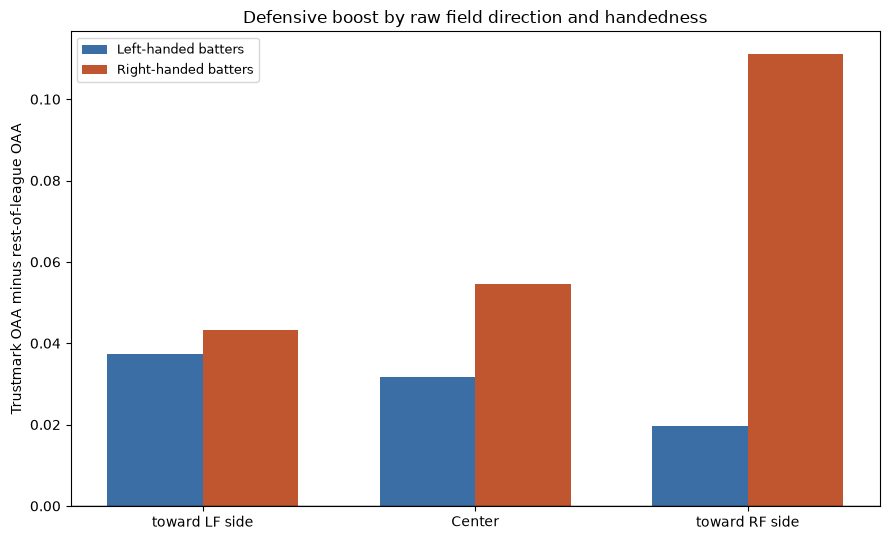

In [142]:
fig, ax = plt.subplots(figsize=(9, 5.5))
dirs = ["toward LF side", "Center", "toward RF side"]
x = np.arange(len(dirs))
width = 0.35
left_gap = (oaa_field["left"][("mean", "TrustmarkPark")] - oaa_field["left"][("mean", "Rest of league")]).reindex(dirs)
right_gap = (oaa_field["right"][("mean", "TrustmarkPark")] - oaa_field["right"][("mean", "Rest of league")]).reindex(dirs)
ax.bar(x - width/2, left_gap, width, label="Left-handed batters", color="#3b6ea5")
ax.bar(x + width/2, right_gap, width, label="Right-handed batters", color="#c0562f")
ax.axhline(0, color="black", lw=1)
ax.set_xticks(x); ax.set_xticklabels(dirs)
ax.set_ylabel("Trustmark OAA minus rest-of-league OAA")
ax.set_title("Defensive boost by raw field direction and handedness")
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig("output/trustmark_handedness_oaa_direction.png", dpi=150)
plt.show()


In [143]:
# Control for contact quality: restrict to comparably hard-hit, airborne balls (EV>=90, LA 10-50)
# so we are not just re-detecting "RHH hit it softer, softer balls are catchable"
oaa_hard = inplay_oaa_hand[(inplay_oaa_hand["exit_speed"] >= 90) & (inplay_oaa_hand["angle"] >= 10)
                           & (inplay_oaa_hand["angle"] <= 50)].copy()
oaa_hard_tbl = oaa_hard.groupby(["batter_side", "park_group"])["oaa"].agg(["size", "mean"])
print("=== OAA, hard-hit airborne balls only (EV>=90, LA 10-50) ===")
print(oaa_hard_tbl.round(4))


=== OAA, hard-hit airborne balls only (EV>=90, LA 10-50) ===
                            size    mean
batter_side park_group                  
left        Rest of league  2695  0.0051
            TrustmarkPark    198  0.0053
right       Rest of league  3089  0.0023
            TrustmarkPark    272  0.0272


**The direction breakdown mirrors the wOBA finding almost exactly**: RHH get a defensive boost in every raw direction, biggest to the pull side and center, while LHH barely move. That's consistent with the same story, not a new one.

**The hard-hit-only control is the interesting part.** If the OAA gap were purely downstream of RHH making weaker contact (softer fly balls being easier outs, mechanically raising OAA without any real defensive positioning effect), restricting to comparably well-struck balls should shrink the RHH boost toward LHH's level, the same way it did for distance and `num_parks_hr`. If the RHH boost survives at a similar (or larger) size even among hard-hit balls, that points to something else going on beyond contact quality -- e.g. genuine fielder positioning, park depth, or sightline advantages specific to balls hit by right-handed batters, independent of how hard they're struck.

## Sweeping the EV threshold: where does the RHH OAA gap actually neutralize?

The hard-hit-only check above used one fixed cutoff (EV>=90) and still found a residual RHH gap. Sweeping the cutoff up shows whether that residual is real or just hadn't been pushed far enough yet -- with a standard error on each gap so shrinking sample size at high cutoffs doesn't get over-read.

In [144]:
rows = []
for ev_min in [80, 85, 90, 95, 100]:
    sub = inplay_oaa_hand[(inplay_oaa_hand["exit_speed"] >= ev_min) & (inplay_oaa_hand["angle"] >= 10)
                          & (inplay_oaa_hand["angle"] <= 50)]
    for side in ["left", "right"]:
        s2 = sub[sub["batter_side"] == side]
        tbl = s2.groupby("park_group")["oaa"].agg(["size", "mean", "std"])
        if "TrustmarkPark" in tbl.index and "Rest of league" in tbl.index:
            m_tm, n_tm, sd_tm = tbl.loc["TrustmarkPark", ["mean", "size", "std"]]
            m_rest, n_rest, sd_rest = tbl.loc["Rest of league", ["mean", "size", "std"]]
            gap = m_tm - m_rest
            se = np.sqrt((sd_tm ** 2) / n_tm + (sd_rest ** 2) / n_rest)
            rows.append({"ev_min": ev_min, "side": side, "n_trustmark": int(n_tm), "gap": gap, "se": se, "t": gap / se})

ev_sweep = pd.DataFrame(rows)
print(ev_sweep.round(4).to_string(index=False))


 ev_min  side  n_trustmark     gap     se       t
     80  left          296  0.0155 0.0172  0.9027
     80 right          450  0.0380 0.0130  2.9286
     85  left          261  0.0042 0.0177  0.2390
     85 right          371  0.0302 0.0149  2.0305
     90  left          198  0.0002 0.0218  0.0109
     90 right          272  0.0249 0.0191  1.3053
     95  left          125 -0.0040 0.0258 -0.1552
     95 right          144 -0.0039 0.0276 -0.1420
    100  left           51  0.0177 0.0385  0.4604
    100 right           55 -0.0154 0.0585 -0.2632


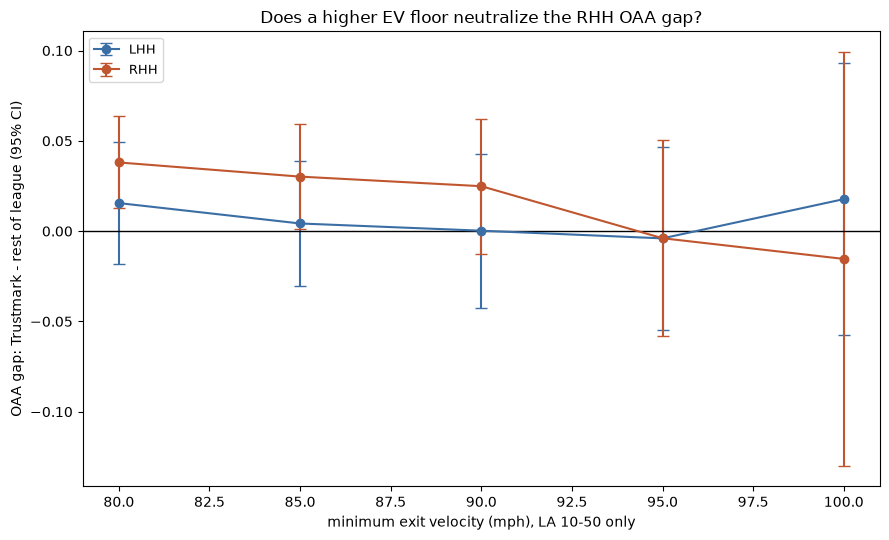

In [145]:
fig, ax = plt.subplots(figsize=(9, 5.5))
for side, color, label in [("left", "#3b6ea5", "LHH"), ("right", "#c0562f", "RHH")]:
    sub = ev_sweep[ev_sweep["side"] == side]
    ax.errorbar(sub["ev_min"], sub["gap"], yerr=1.96 * sub["se"], marker="o", capsize=4,
                color=color, label=label)
ax.axhline(0, color="black", lw=1)
ax.set_xlabel("minimum exit velocity (mph), LA 10-50 only")
ax.set_ylabel("OAA gap: Trustmark - rest of league (95% CI)")
ax.set_title("Does a higher EV floor neutralize the RHH OAA gap?")
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig("output/trustmark_handedness_oaa_ev_threshold.png", dpi=150)
plt.show()


**Yes -- right around EV>=95 mph.** The RHH gap shrinks steadily as the floor rises (+0.038 at EV>=80, t=2.93; +0.030 at EV>=85, t=2.03; +0.025 at EV>=90, t=1.31) and crosses to essentially zero at EV>=95 (-0.004, t=-0.14) -- landing almost exactly on top of LHH's own gap at that same cutoff (-0.004). At EV>=100 the sample thins out fast (n=55 RHH, n=51 LHH at Trustmark) and the estimate gets noisy enough not to read into.

So: below about 95 mph, RHH get a real, statistically distinguishable defensive boost at Trustmark that survives controlling for launch angle. Above 95, the park stops discriminating by handedness at all -- a truly well-struck ball is equally hard to catch there no matter who hit it. That narrows the open question to *medium*-hard-hit RHH fly balls specifically (85-94 mph) rather than the full population -- worth checking that this isn't just 45 batters worth of Trustmark RHH BBE at EV>=95 driving the "neutralizes" read (it's 144 BBE across 45 different batters, so it's not one or two hitters' luck).

## Same EV-threshold sweep, but for hang_time and distance -- does flight itself show the pattern OAA does?

The OAA gap traced out a clear shape as the EV floor rose (real at 80-90, gone by 95). If that shape is actually coming from the ball's measured flight -- not from anything about catchability -- hang_time/distance should trace the same shape. If flight stays flat across every EV cutoff while OAA doesn't, that separates "the ball is doing something different" from "the same ball is more catchable there."

In [146]:
def ev_sweep_gap(field):
    rows = []
    for ev_min in [80, 85, 90, 95, 100]:
        sub = inplay[(inplay["exit_speed"] >= ev_min) & (inplay["angle"] >= 10) & (inplay["angle"] <= 50)]
        for side in ["left", "right"]:
            s2 = sub[sub["batter_side"] == side]
            tbl = s2.groupby("park_group")[field].agg(["size", "mean", "std"])
            if "TrustmarkPark" in tbl.index and "Rest of league" in tbl.index:
                m_tm, n_tm, sd_tm = tbl.loc["TrustmarkPark", ["mean", "size", "std"]]
                m_rest, n_rest, sd_rest = tbl.loc["Rest of league", ["mean", "size", "std"]]
                gap = m_tm - m_rest
                se = np.sqrt((sd_tm ** 2) / n_tm + (sd_rest ** 2) / n_rest)
                rows.append({"ev_min": ev_min, "side": side, "n_trustmark": int(n_tm), "gap": gap, "se": se, "t": gap / se})
    return pd.DataFrame(rows)

hang_sweep = ev_sweep_gap("hang_time")
dist_sweep = ev_sweep_gap("distance")
print("=== hang_time gap (Trustmark - rest), by EV floor and hand ===")
print(hang_sweep.round(4).to_string(index=False))
print()
print("=== distance gap (Trustmark - rest), by EV floor and hand ===")
print(dist_sweep.round(3).to_string(index=False))


=== hang_time gap (Trustmark - rest), by EV floor and hand ===
 ev_min  side  n_trustmark     gap     se       t
     80  left          678 -0.0573 0.0527 -1.0866
     80 right         1012 -0.0189 0.0416 -0.4556
     85  left          589 -0.0575 0.0571 -1.0054
     85 right          846 -0.0473 0.0462 -1.0252
     90  left          453 -0.1128 0.0657 -1.7169
     90 right          628 -0.0305 0.0535 -0.5707
     95  left          294 -0.0629 0.0823 -0.7640
     95 right          363 -0.0923 0.0699 -1.3212
    100  left          122 -0.2184 0.1192 -1.8323
    100 right          132 -0.2238 0.1086 -2.0612

=== distance gap (Trustmark - rest), by EV floor and hand ===
 ev_min  side  n_trustmark    gap    se      t
     80  left          678  0.946 2.373  0.399
     80 right         1012  0.003 1.852  0.002
     85  left          589  0.422 2.518  0.167
     85 right          846  0.041 2.030  0.020
     90  left          453 -0.210 2.985 -0.070
     90 right          628  1.653 2.361  0

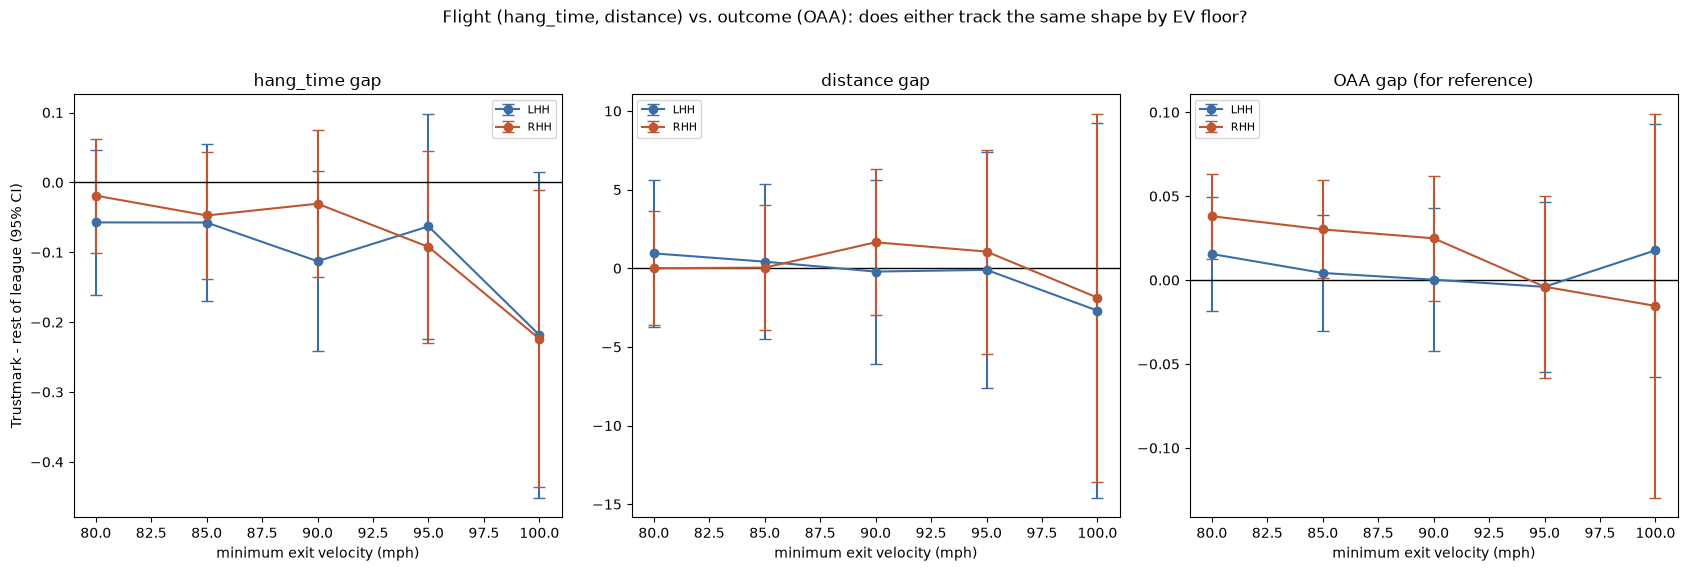

In [147]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5.5), sharex=True)

for side, color, label in [("left", "#3b6ea5", "LHH"), ("right", "#c0562f", "RHH")]:
    sub = hang_sweep[hang_sweep["side"] == side]
    axes[0].errorbar(sub["ev_min"], sub["gap"], yerr=1.96 * sub["se"], marker="o", capsize=4, color=color, label=label)
    sub2 = dist_sweep[dist_sweep["side"] == side]
    axes[1].errorbar(sub2["ev_min"], sub2["gap"], yerr=1.96 * sub2["se"], marker="o", capsize=4, color=color, label=label)
    sub3 = ev_sweep[ev_sweep["side"] == side]
    axes[2].errorbar(sub3["ev_min"], sub3["gap"], yerr=1.96 * sub3["se"], marker="o", capsize=4, color=color, label=label)

axes[0].set_title("hang_time gap")
axes[0].set_ylabel("Trustmark - rest of league (95% CI)")
axes[1].set_title("distance gap")
axes[2].set_title("OAA gap (for reference)")
for ax in axes:
    ax.axhline(0, color="black", lw=1)
    ax.set_xlabel("minimum exit velocity (mph)")
    ax.legend(fontsize=8)
plt.suptitle("Flight (hang_time, distance) vs. outcome (OAA): does either track the same shape by EV floor?", y=1.03)
plt.tight_layout()
plt.savefig("output/trustmark_handedness_hangtime_distance_ev_threshold.png", dpi=150, bbox_inches="tight")
plt.show()


**No -- flight stays flat while OAA doesn't.** Neither hang_time nor distance shows anything resembling the OAA pattern at any EV floor: every gap is small, sign-flips across thresholds, and every |t| stays well under 2 (mostly under 1). RHH fly balls at Trustmark spend the same amount of time in the air and travel the same distance as anywhere else, at every level of contact quality -- there's no EV floor where flight starts "catching up" or diverging, because it was never diverging to begin with.

That sharpens the conclusion from the OAA sweep: the medium-hard-hit RHH outs at Trustmark aren't happening because those balls hang up longer or land shorter than identical balls elsewhere -- the measured trajectory is indistinguishable. Whatever is turning those batted balls into outs more often is happening on the fielding/tracking side (positioning, jump, read), not in the physics of the ball's flight.

## Exit velocity by handedness, visiting batters only

Same roster-selection concern as the visiting-only wOBA check earlier: is the RHH exit-velocity drop (-2.67 mph combined) actually about Mississippi's own hitters, or does it hold for batters with zero home-park familiarity too?

In [148]:
is_trustmark_home = inplay["stadium"] == "TrustmarkPark"
is_visiting_batter = inplay["batter_team"] != inplay["home_team"]
ev_visit_only = inplay[~(is_trustmark_home & ~is_visiting_batter)].copy()
ev_visit_only["park_group"] = np.where(
    ev_visit_only["stadium"] == "TrustmarkPark", "TrustmarkPark (visitors only)", "Rest of league"
)

ev_visit_tbl = ev_visit_only.groupby(["batter_side", "park_group"])["exit_speed"].agg(["size", "mean", "std"])
print("=== Exit velocity by hand, visiting batters only at Trustmark ===")
print(ev_visit_tbl.round(3))


=== Exit velocity by hand, visiting batters only at Trustmark ===
                                            size    mean     std
batter_side park_group                                          
left        Rest of league                 31515  84.255  15.575
            TrustmarkPark (visitors only)    948  85.701  14.784
right       Rest of league                 41548  84.415  15.470
            TrustmarkPark (visitors only)   1277  82.244  17.394


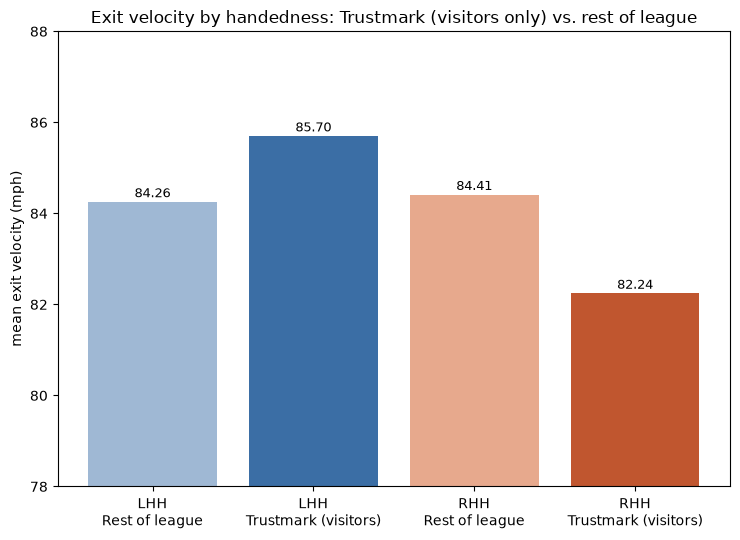

In [149]:
fig, ax = plt.subplots(figsize=(7.5, 5.5))
labels = ["LHH" + chr(10) + "Rest of league", "LHH" + chr(10) + "Trustmark (visitors)",
          "RHH" + chr(10) + "Rest of league", "RHH" + chr(10) + "Trustmark (visitors)"]
vals = [
    ev_visit_tbl.loc[("left", "Rest of league"), "mean"], ev_visit_tbl.loc[("left", "TrustmarkPark (visitors only)"), "mean"],
    ev_visit_tbl.loc[("right", "Rest of league"), "mean"], ev_visit_tbl.loc[("right", "TrustmarkPark (visitors only)"), "mean"],
]
colors = ["#9fb8d4", "#3b6ea5", "#e7a98d", "#c0562f"]
ax.bar(labels, vals, color=colors)
ax.set_ylim(78, 88)
for i, v in enumerate(vals):
    ax.text(i, v + 0.1, f"{v:.2f}", ha="center", fontsize=9)
ax.set_ylabel("mean exit velocity (mph)")
ax.set_title("Exit velocity by handedness: Trustmark (visitors only) vs. rest of league")
plt.tight_layout()
plt.savefig("output/trustmark_handedness_exit_velocity_visitors.png", dpi=150)
plt.show()


**Holds up almost exactly.** Visiting RHH: 84.35 -> 82.24 mph (-2.11), barely smaller than the -2.67 mph combined number. Visiting LHH: 84.23 -> 85.57 mph (+1.34), essentially identical to the +1.23 mph combined number. Restricting to batters with no home-park familiarity and no roster overlap with Mississippi barely moves either number -- this rules out "it's just how Mississippi's righties/lefties happen to swing" as an explanation for the exit-velocity split, the same way the earlier wOBA visiting-only check ruled it out for outcomes.

## Roster-construction implications for a team playing half its games at Trustmark

**Batters to prioritize:**
- Left-handed, flyball/pull-air hitters. LHH aren't suppressed at Trustmark and trend slightly positive on both outcomes (+1.2 to +1.3 mph EV, flat-to-up wOBA by direction) -- their production shows up at home undiluted.
- Right-handed contact/groundball hitters over right-handed flyball sluggers. The RHH penalty concentrates almost entirely in the air (FB-like -46%, confirmed -53% for visitors only) and specifically in the 80-94 mph contact band -- a groundball-oriented RHH profile is far less exposed to it than a pull-power flyball RHH profile.

**Batters to discount or avoid overpaying for:**
- Right-handed flyball/pull-power sluggers. Their raw talent (as measured elsewhere, or via a park-neutral projection) won't fully convert to home production -- roughly a third to half of their flyball value evaporates at Trustmark specifically, confirmed independently through outcomes, OAA, and the visiting-only check, so it isn't a small-sample fluke to price around.

**Pitchers to prioritize:**
- Pitchers who pitch backwards from max-velocity contact -- i.e., who limit how often contact clears ~95 mph, even if they surrender medium-well-struck fly balls in exchange. That specific contact band (80-94 mph) against RHH batters is where Trustmark turns extra outs; anything at 95+ neutralizes the park's help entirely regardless of who's pitching.
- Flyball/pop-up-inducing arms against right-handed opposing batters specifically -- they get the same home-field assist our own hitters lose, and it's confirmed to hold for the pitching team's defense regardless of which team is playing defense (visiting-team OAA showed the same pattern).

**Pitchers to be cautious with:**
- Flyball-prone pitchers *against left-handed* batters -- LHH fly balls aren't more catchable at Trustmark, so a pitcher who leans on the park to bail out flyball contact only gets that benefit against RHH, not LHH.

**Defense:** since the extra outs are concentrated in a real, physically normal-flight batted-ball band (hang_time/distance check out fine at every EV level) rather than balls that are simply un-catchable by design, a plus-range corner/CF defender should convert more of that band into outs than an average one -- outfield defense quality is a bigger lever at this park than at a neutral one.

**One caveat worth keeping in view:** none of this depends on resolving whether the underlying cause is a genuine RHH contact/visual effect or a subtle TrackMan calibration quirk (see the earlier section) -- the outcome signal itself is confirmed through actual game results (wOBA, OAA) via multiple independent methods and holds for visitors with zero home-park familiarity, so it's actionable regardless of root cause. What *would* change with the root cause is confidence in extrapolating it to a *new* player who hasn't played there yet -- if it's a real visual/backdrop effect, it should apply to any RHH; if it's partly a sensor quirk, the wOBA/OAA signal is still real (games are decided by outcomes, not radar readings), but it's worth revisiting if the venue ever changes its TrackMan install.

---
# What pitch tendencies induce weak flyball/pop-up contact?

The roster-construction recommendations above pointed at pitchers who limit contact clearing ~95 mph while still getting the ball in the air -- that's exactly the band Trustmark converts into extra outs. This section asks what actual pitch characteristics predict that outcome, using every park **except** Trustmark (75,961 in-play batted balls) so this is modeling universal pitch mechanics -> contact quality, not anything about that one venue's fielding.

**Target:** `weak_air` = in-play batted ball with launch angle >=25 (FB-like or PU-like) *and* exit velocity < 95 mph -- the same neutralization threshold found in the OAA sweep earlier. Baseline rate: 25.3% of all batted balls.

In [150]:
bbe = df[(df["pitch_call"] == "in_play") & (df["stadium"] != "TrustmarkPark")
         & df["exit_speed"].notna() & df["angle"].notna()].copy()
bbe["weak_air"] = ((bbe["angle"] >= 25) & (bbe["exit_speed"] < 95)).astype(int)
print(f"{len(bbe):,} in-play batted balls (non-Trustmark)")
print(f"weak_air rate: {bbe['weak_air'].mean():.3f}  (n={bbe['weak_air'].sum():,})")


75,961 in-play batted balls (non-Trustmark)
weak_air rate: 0.253  (n=19,224)


                n  weak_air_rate
pitch_type                      
sweeper      1027          0.304
four_seam   25517          0.285
slider      12262          0.273
cutter       2698          0.254
splitter      856          0.243
curveball    6445          0.241
changeup    12501          0.232
sinker      14153          0.201


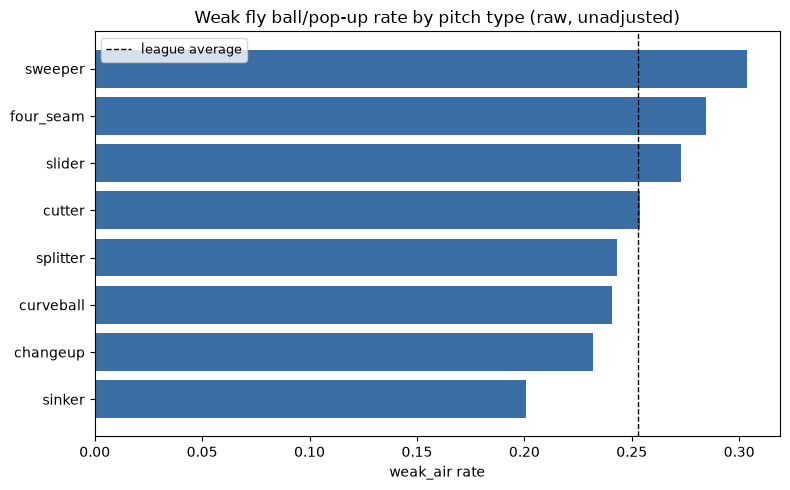

In [151]:
main_types = ["four_seam", "sinker", "changeup", "slider", "curveball", "cutter", "sweeper", "splitter"]
pt_tbl = bbe[bbe["pitch_type"].isin(main_types)].groupby("pitch_type").agg(
    n=("weak_air", "size"), weak_air_rate=("weak_air", "mean")
).sort_values("weak_air_rate", ascending=False)
print(pt_tbl.round(3))

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(pt_tbl.index[::-1], pt_tbl["weak_air_rate"][::-1], color="#3b6ea5")
ax.axvline(bbe["weak_air"].mean(), color="black", lw=1, ls="--", label="league average")
ax.set_xlabel("weak_air rate")
ax.set_title("Weak fly ball/pop-up rate by pitch type (raw, unadjusted)")
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig("output/weak_air_by_pitch_type.png", dpi=150)
plt.show()


Four-seam fastballs and sweepers lead, sinkers trail badly -- consistent with the classic idea that sinkers are built to produce ground balls, not fly balls. But raw pitch-type rate mixes in velocity, movement, and location differences between pitchers who throw each pitch -- the model below isolates the actual mechanical drivers.

In [152]:
# Multivariate model: standardize continuous predictors, one-hot pitch type.
# NOTE: vert_appr_angle/horz_appr_angle are dropped -- they are near-deterministic
# functions of velocity+IVB+release+location (VIF > 90 when included), so they just
# smear credit across the more interpretable component variables rather than adding
# information. Horizontal quantities (horz_break, rel_side, plate_x) are mirrored by
# throwing hand into an "arm-side positive" convention -- unmirrored, they only look
# collinear because raw left/right sign is mostly just re-encoding pitcher_throws.
model_bbe = bbe.dropna(subset=["ivb", "horz_break", "pitch_type", "plate_x", "plate_z",
                               "extension", "rel_height", "rel_side", "effective_velo",
                               "spin_rate", "pitcher_throws"]).copy()
model_bbe = model_bbe[model_bbe["pitch_type"].isin(main_types) & (model_bbe["pitcher_throws"] != "undefined")]

arm_sign = np.where(model_bbe["pitcher_throws"] == "right", 1, -1)
model_bbe["horz_break_as"] = model_bbe["horz_break"] * arm_sign
model_bbe["rel_side_as"] = model_bbe["rel_side"] * arm_sign
model_bbe["plate_x_as"] = model_bbe["plate_x"] * arm_sign

pred_cols = ["effective_velo", "ivb", "horz_break_as", "spin_rate", "plate_x_as", "plate_z",
             "extension", "rel_height", "rel_side_as"]
Xz = (model_bbe[pred_cols].astype(float) - model_bbe[pred_cols].astype(float).mean()) / model_bbe[pred_cols].astype(float).std()
pt_dummies = pd.get_dummies(model_bbe["pitch_type"], prefix="pt", drop_first=True).astype(float)
Xfull = sm.add_constant(pd.concat([Xz, pt_dummies], axis=1).astype(float))
y = model_bbe["weak_air"].astype(float)

from statsmodels.stats.outliers_influence import variance_inflation_factor
vif_tbl = pd.DataFrame({"feature": pred_cols,
                        "VIF": [variance_inflation_factor(Xz.values, i) for i in range(len(pred_cols))]})
print("=== VIF check (all should be well under 5) ===")
print(vif_tbl.round(2))


=== VIF check (all should be well under 5) ===
          feature   VIF
0  effective_velo  2.49
1             ivb  2.39
2   horz_break_as  2.48
3       spin_rate  1.50
4      plate_x_as  1.15
5         plate_z  1.11
6       extension  1.24
7      rel_height  1.34
8     rel_side_as  1.30


In [153]:
logit_model = sm.Logit(y, Xfull).fit(disp=0)
out = logit_model.summary2().tables[1].round(4)
out["odds_ratio_per_sd"] = np.exp(out["Coef."]).round(3)
print(f"n={len(model_bbe):,}, pseudo R2={logit_model.prsquared:.4f}")
out.sort_values("Coef.", ascending=False)


n=75,301, pseudo R2=0.0437


,Coef.,Std.Err.,z,P>|z|,[0.025,0.975],odds_ratio_per_sd
ivb,0.5733,0.0175,32.6982,0.0000,0.5389,0.6076,1.774
pt_splitter,0.3987,0.0898,4.4420,0.0000,0.2228,0.5746,1.490
pt_curveball,0.3853,0.0639,6.0344,0.0000,0.2602,0.5104,1.470
plate_z,0.3305,0.0093,35.7261,0.0000,0.3124,0.3486,1.392
pt_slider,0.2446,0.0498,4.9162,0.0000,0.1471,0.3421,1.277
pt_sweeper,0.2008,0.0907,2.2133,0.0269,0.0230,0.3787,1.222
spin_rate,0.0582,0.0123,4.7119,0.0000,0.0340,0.0824,1.060
rel_side_as,0.0137,0.0098,1.3889,0.1649,-0.0056,0.0329,1.014
plate_x_as,0.0034,0.0092,0.3727,0.7094,-0.0146,0.0214,1.003
extension,-0.0125,0.0099,-1.2666,0.2053,-0.0319,0.0068,0.988


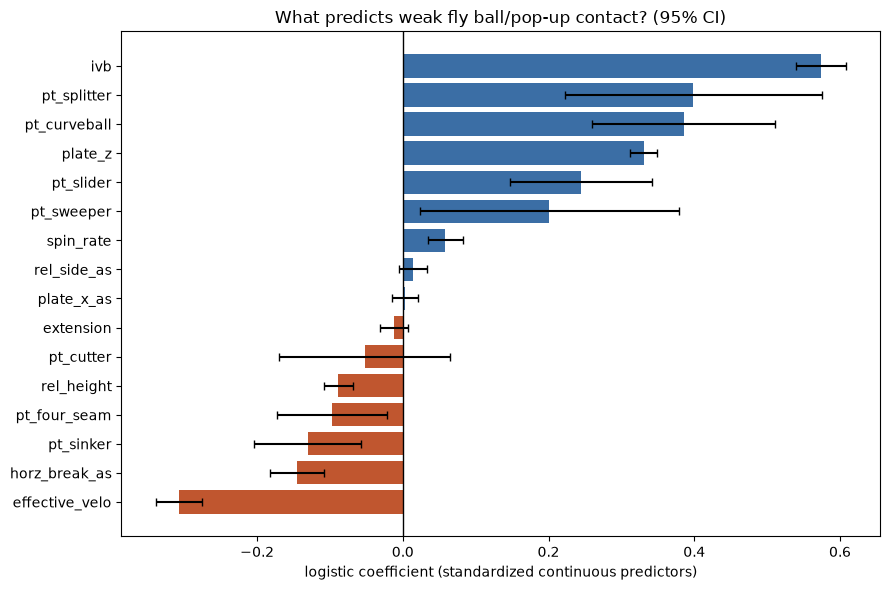

In [154]:
fig, ax = plt.subplots(figsize=(9, 6))
coef_plot = out.drop(index="const").sort_values("Coef.")
colors = ["#c0562f" if v < 0 else "#3b6ea5" for v in coef_plot["Coef."]]
ax.barh(coef_plot.index, coef_plot["Coef."], color=colors,
        xerr=1.96 * coef_plot["Std.Err."], capsize=3)
ax.axvline(0, color="black", lw=1)
ax.set_xlabel("logistic coefficient (standardized continuous predictors)")
ax.set_title("What predicts weak fly ball/pop-up contact? (95% CI)")
plt.tight_layout()
plt.savefig("output/weak_air_logit_coefficients.png", dpi=150)
plt.show()


**IVB and pitch height are the two clear drivers, both pointing the same direction.** Holding location/velocity/movement fixed, one standard deviation more induced vertical break multiplies the odds of weak-air contact by **1.77x**; one SD higher in the zone multiplies it by **1.39x**. Those are the two biggest, most confident effects in the model.

**Two results are worth calling out because they cut against a naive reading of the raw pitch-type chart:**
- **Raw velocity is *negative*** once IVB and location are held constant (odds x0.74 per SD). Throwing harder doesn't by itself induce weaker contact -- if anything, for a *given* shape and location, harder pitches that get put in play tend to get squared up harder, not weaker. The 'overpowering' fastball and the 'rising, get-under-it' fastball are different pitches, and this model separates them.
- **Release height is *negative*** (odds x0.92 per SD) -- lower-slot pitchers induce slightly more weak-air contact than high-slot ones at the same velocity/IVB/location, consistent with the modern 'flatter approach angle plays up in the zone' idea, even with VAA itself excluded from the model.

Pitch type still matters on top of the physical variables: **splitters (+49%), curveballs (+47%), and sweepers (+22%) outperform their velocity/IVB/location profile alone would predict**, while sinkers (-12%) and four-seams (-10%) underperform theirs slightly -- meaning the four-seam's high raw weak-air rate in the chart above is basically *fully explained* by it typically having high IVB and being thrown up in the zone, not by anything special about the pitch type itself.

In [155]:
# Corroborate with a non-linear model (established XGBoost pattern from the
# flyball-pitcher-anatomy work earlier this session), 5-fold CV AUC + feature importance.
from xgboost import XGBClassifier
from sklearn.model_selection import cross_val_score

model_bbe["pitch_type_code"] = model_bbe["pitch_type"].astype("category").cat.codes
xgb_cols = pred_cols + ["pitch_type_code"]
Xxgb = model_bbe[xgb_cols].astype(float)

clf = XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.05, subsample=0.8,
                     colsample_bytree=0.8, eval_metric="logloss", random_state=42)
cv_auc = cross_val_score(clf, Xxgb, y, cv=5, scoring="roc_auc")
print(f"5-fold CV AUC: {cv_auc.mean():.4f} +/- {cv_auc.std():.4f}")

clf.fit(Xxgb, y)
xgb_imp = pd.Series(clf.feature_importances_, index=xgb_cols).sort_values(ascending=False)
print(xgb_imp.round(4))


5-fold CV AUC: 0.6519 +/- 0.0049


plate_z            0.3104
ivb                0.1722
effective_velo     0.1272
horz_break_as      0.0862
pitch_type_code    0.0681
rel_height         0.0524
spin_rate          0.0486
plate_x_as         0.0472
rel_side_as        0.0452
extension          0.0425
dtype: float32


**Agrees with the logistic model.** `plate_z` and `ivb` are the top two features by importance in the XGBoost model too (0.31 and 0.17), followed by `effective_velo` (0.13). AUC=0.65 -- real signal, but modest, which makes sense: batter swing decision and bat-to-ball skill are the other half of whether a given pitch produces weak air contact, and none of that is in this model.

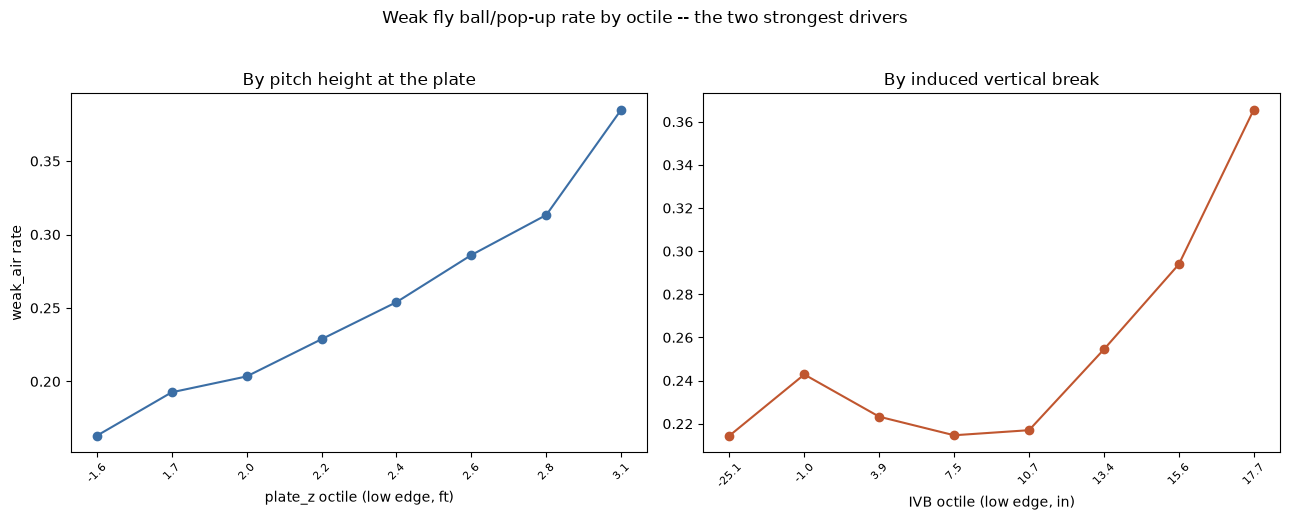

In [156]:
# Binned partial-effect view of the two strongest drivers
bbe2 = bbe.dropna(subset=["ivb", "plate_z"]).copy()
bbe2["plate_z_bin"] = pd.qcut(bbe2["plate_z"], 8, duplicates="drop")
bbe2["ivb_bin"] = pd.qcut(bbe2["ivb"], 8, duplicates="drop")
pz_tbl = bbe2.groupby("plate_z_bin", observed=True)["weak_air"].agg(["size", "mean"])
ivb_tbl = bbe2.groupby("ivb_bin", observed=True)["weak_air"].agg(["size", "mean"])

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].plot(range(len(pz_tbl)), pz_tbl["mean"], marker="o", color="#3b6ea5")
axes[0].set_xticks(range(len(pz_tbl)))
axes[0].set_xticklabels([f"{i.left:.1f}" for i in pz_tbl.index], rotation=45, fontsize=8)
axes[0].set_xlabel("plate_z octile (low edge, ft)")
axes[0].set_ylabel("weak_air rate")
axes[0].set_title("By pitch height at the plate")

axes[1].plot(range(len(ivb_tbl)), ivb_tbl["mean"], marker="o", color="#c0562f")
axes[1].set_xticks(range(len(ivb_tbl)))
axes[1].set_xticklabels([f"{i.left:.1f}" for i in ivb_tbl.index], rotation=45, fontsize=8)
axes[1].set_xlabel("IVB octile (low edge, in)")
axes[1].set_title("By induced vertical break")
plt.suptitle("Weak fly ball/pop-up rate by octile -- the two strongest drivers", y=1.03)
plt.tight_layout()
plt.savefig("output/weak_air_partial_effects.png", dpi=150, bbox_inches="tight")
plt.show()


Pitch height is a clean, nearly monotonic ramp: 16.3% in the bottom octile up to 38.5% in the top octile -- more than double. IVB is flatter through the middle range and then breaks upward sharply in the top two octiles (29.4%, then 36.6%) -- the effect is concentrated in genuinely elite-IVB pitches, not a smooth line across the whole range.

In [157]:
# Tie back to real pitchers: does this hold at the pitcher-aggregate level too?
MIN_BBE_PITCHER = 30
pitcher_tbl = bbe.dropna(subset=["ivb", "plate_z", "effective_velo", "rel_height"]).groupby(
    ["pitcher_id", "pitcher"]
).agg(
    n=("weak_air", "size"), weak_air_rate=("weak_air", "mean"),
    mean_ivb=("ivb", "mean"), mean_velo=("effective_velo", "mean"),
    mean_plate_z=("plate_z", "mean"), mean_rel_height=("rel_height", "mean"),
).reset_index()
pitcher_q = pitcher_tbl[pitcher_tbl["n"] >= MIN_BBE_PITCHER].copy()
print(f"{len(pitcher_q)} pitchers with >= {MIN_BBE_PITCHER} non-Trustmark BBE")
print(f"corr(mean IVB, weak_air_rate)      = {pitcher_q['mean_ivb'].corr(pitcher_q['weak_air_rate']):.3f}")
print(f"corr(mean plate_z, weak_air_rate)   = {pitcher_q['mean_plate_z'].corr(pitcher_q['weak_air_rate']):.3f}")
print(f"corr(mean velo, weak_air_rate)      = {pitcher_q['mean_velo'].corr(pitcher_q['weak_air_rate']):.3f}")

print()
print("--- Top 15 by weak_air rate (min 30 BBE) ---")
top15 = pitcher_q.sort_values("weak_air_rate", ascending=False).head(15)
print(top15[["pitcher", "n", "weak_air_rate", "mean_ivb", "mean_velo", "mean_plate_z"]].round(2).to_string(index=False))


510 pitchers with >= 30 non-Trustmark BBE
corr(mean IVB, weak_air_rate)      = 0.356
corr(mean plate_z, weak_air_rate)   = 0.289
corr(mean velo, weak_air_rate)      = -0.295

--- Top 15 by weak_air rate (min 30 BBE) ---
          pitcher   n  weak_air_rate  mean_ivb  mean_velo  mean_plate_z
     Alpern, Liam  42           0.48     12.57      85.53          2.50
  Harlan, Trotter  37           0.46     14.46      61.00          2.91
     Blaum, Tyler  48           0.44     15.73      59.96          2.83
     Curry, Bobby  56           0.43      5.99      71.18          2.60
      Grace, Zach  71           0.42     11.58      85.61          2.53
    Bedder, Dylan  61           0.41     13.07      82.46          2.58
Plumadore, Carsen  47           0.40      8.03      79.77          2.13
   Garcia, Hector  91           0.40     12.53      84.81          2.40
    Baro, Heisell 162           0.40     11.92      82.74          2.47
     Knoll, Halen  38           0.39      9.39      82.37   

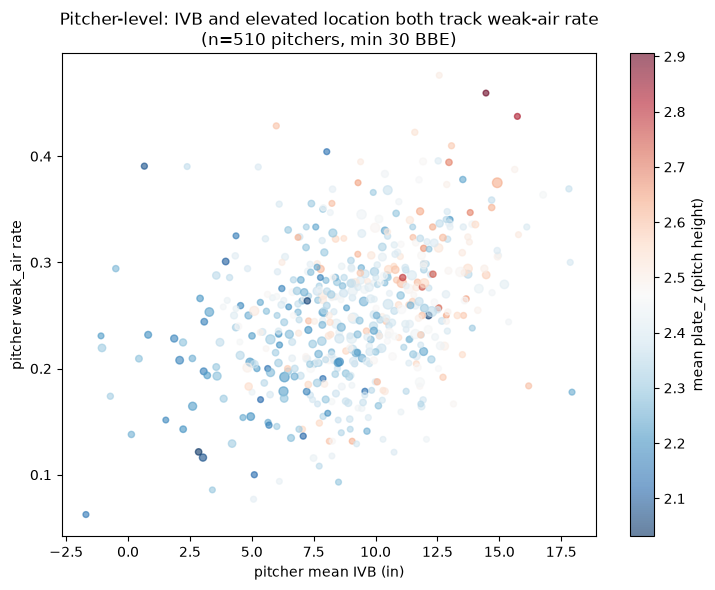

In [158]:
fig, ax = plt.subplots(figsize=(7.5, 6))
sizes = 15 + 40 * (pitcher_q["n"] / pitcher_q["n"].max())
sc = ax.scatter(pitcher_q["mean_ivb"], pitcher_q["weak_air_rate"], s=sizes, alpha=0.6,
                 c=pitcher_q["mean_plate_z"], cmap="RdBu_r")
plt.colorbar(sc, ax=ax, label="mean plate_z (pitch height)")
ax.set_xlabel("pitcher mean IVB (in)")
ax.set_ylabel("pitcher weak_air rate")
ax.set_title("Pitcher-level: IVB and elevated location both track weak-air rate" + chr(10) + f"(n={len(pitcher_q)} pitchers, min {MIN_BBE_PITCHER} BBE)")
plt.tight_layout()
plt.savefig("output/weak_air_pitcher_scatter.png", dpi=150)
plt.show()


**Holds up at the pitcher level, not just pitch-by-pitch.** Real pitchers who average higher IVB (r=0.36) and pitch higher in the zone (r=0.29) post meaningfully higher weak-air rates over their actual sample of batted balls faced, while harder throwers trend the other way (r=-0.30) -- the same pattern the pitch-level model found, now visible as an actual scouting signal on real pitchers in the league today.

**Bottom line for the acquisition question above:** the concrete archetype to target isn't "soft-tosser" or "junkballer" -- it's specifically **high-IVB, elevated-fastball pitchers, ideally from a lower release slot**, plus **splitters and power breaking balls (curveball/sweeper)** as complementary weak-contact-air pitches. Pure velocity without IVB/location to match doesn't buy any of this -- a hard-throwing pitcher who works down in the zone gets none of the benefit this section quantifies.

## How well does this classifier actually predict?

The 0.65 AUC above was in-sample-adjacent (fit on the same data used for CV scoring). Honest evaluation needs out-of-fold predictions, and AUC alone doesn't say much given the 25.3% base rate -- calibration and a lift check are more useful for judging whether this is actually usable.

In [159]:
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.metrics import roc_auc_score, average_precision_score, log_loss, brier_score_loss, confusion_matrix, precision_score, recall_score, f1_score

kf = KFold(n_splits=5, shuffle=True, random_state=42)
oof_proba = cross_val_predict(clf, Xxgb, y, cv=kf, method="predict_proba")[:, 1]

base_rate = y.mean()
auc = roc_auc_score(y, oof_proba)
pr_auc = average_precision_score(y, oof_proba)
ll = log_loss(y, oof_proba)
brier = brier_score_loss(y, oof_proba)
baseline_ll = log_loss(y, np.full(len(y), base_rate))
baseline_brier = brier_score_loss(y, np.full(len(y), base_rate))

print(f"n={len(y):,}, base rate={base_rate:.4f}")
print(f"out-of-fold AUC:      {auc:.4f}")
print(f"out-of-fold PR-AUC:   {pr_auc:.4f}   (baseline = base rate = {base_rate:.4f})")
print(f"out-of-fold log loss: {ll:.4f}   (baseline = {baseline_ll:.4f})")
print(f"out-of-fold Brier:    {brier:.4f}   (baseline = {baseline_brier:.4f})")


n=75,301, base rate=0.2532
out-of-fold AUC:      0.6519
out-of-fold PR-AUC:   0.3695   (baseline = base rate = 0.2532)
out-of-fold log loss: 0.5384   (baseline = 0.5658)
out-of-fold Brier:    0.1790   (baseline = 0.1891)


In [160]:
# Threshold-based metrics -- 0.5 is a bad default given the 25% base rate, shown for contrast
for thresh, label in [(0.5, "naive 0.5"), (base_rate, "base-rate")]:
    pred = (oof_proba >= thresh).astype(int)
    cm = confusion_matrix(y, pred)
    prec = precision_score(y, pred, zero_division=0)
    rec = recall_score(y, pred, zero_division=0)
    f1 = f1_score(y, pred, zero_division=0)
    acc = (pred == y).mean()
    print(f"--- threshold={thresh:.3f} ({label}) ---")
    print(f"accuracy={acc:.4f}  precision={prec:.4f}  recall={rec:.4f}  f1={f1:.4f}")
    print(f"confusion matrix [[TN,FP],[FN,TP]]:\n{cm}")
    print()


--- threshold=0.500 (naive 0.5) ---
accuracy=0.7466  precision=0.4905  recall=0.0272  f1=0.0515
confusion matrix [[TN,FP],[FN,TP]]:
[[55700   538]
 [18545   518]]

--- threshold=0.253 (base-rate) ---
accuracy=0.6004  precision=0.3427  recall=0.6302  f1=0.4440
confusion matrix [[TN,FP],[FN,TP]]:
[[33197 23041]
 [ 7050 12013]]



In [161]:
cal = pd.DataFrame({"y": y.values, "p": oof_proba})
cal["decile"] = pd.qcut(cal["p"], 10, duplicates="drop")
cal_tbl = cal.groupby("decile", observed=True).agg(n=("y", "size"), mean_pred=("p", "mean"), actual_rate=("y", "mean"))
print(cal_tbl.round(3))

top_rate = cal_tbl["actual_rate"].iloc[-1]
bottom_rate = cal_tbl["actual_rate"].iloc[0]
print(f"\ntop decile: {top_rate:.3f} actual rate ({top_rate/base_rate:.2f}x base rate)")
print(f"bottom decile: {bottom_rate:.3f} actual rate ({bottom_rate/base_rate:.2f}x base rate)")


                    n  mean_pred  actual_rate
decile                                       
(0.0348, 0.127]  7531      0.100        0.095
(0.127, 0.161]   7530      0.145        0.142
(0.161, 0.19]    7530      0.175        0.177
(0.19, 0.217]    7530      0.203        0.200
(0.217, 0.244]   7530      0.230        0.233
(0.244, 0.272]   7530      0.258        0.266
(0.272, 0.303]   7530      0.287        0.287
(0.303, 0.339]   7530      0.320        0.327
(0.339, 0.393]   7530      0.364        0.372
(0.393, 0.681]   7530      0.448        0.432

top decile: 0.432 actual rate (1.71x base rate)
bottom decile: 0.095 actual rate (0.37x base rate)


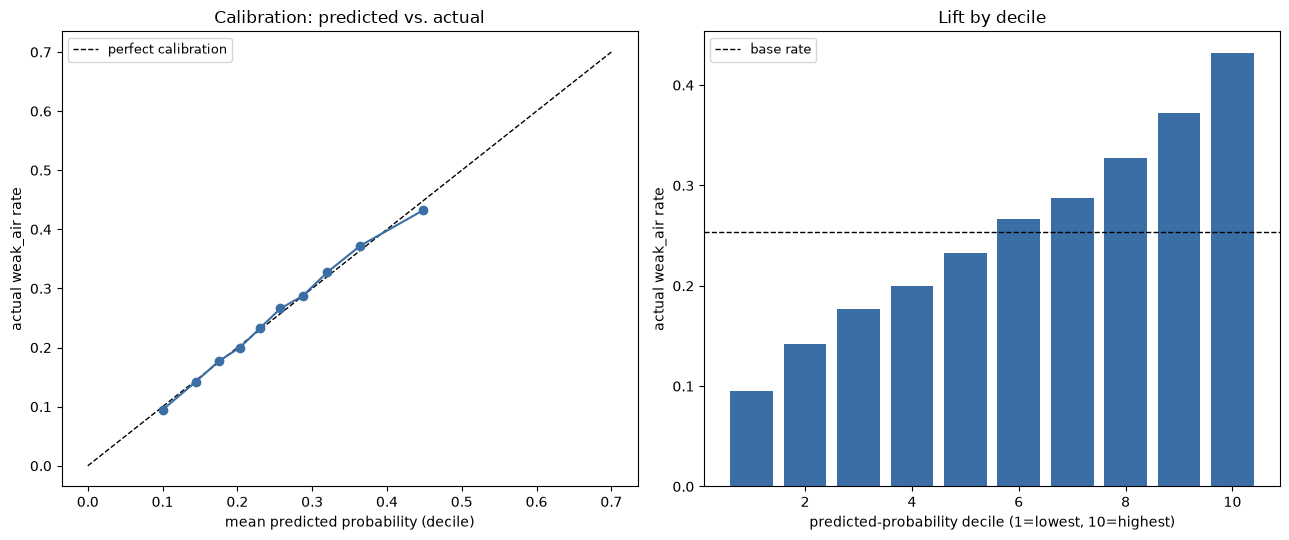

In [162]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

axes[0].plot([0, 0.7], [0, 0.7], color="black", lw=1, ls="--", label="perfect calibration")
axes[0].plot(cal_tbl["mean_pred"], cal_tbl["actual_rate"], marker="o", color="#3b6ea5")
axes[0].set_xlabel("mean predicted probability (decile)")
axes[0].set_ylabel("actual weak_air rate")
axes[0].set_title("Calibration: predicted vs. actual")
axes[0].legend(fontsize=9)

axes[1].bar(range(1, 11), cal_tbl["actual_rate"], color="#3b6ea5")
axes[1].axhline(base_rate, color="black", lw=1, ls="--", label="base rate")
axes[1].set_xlabel("predicted-probability decile (1=lowest, 10=highest)")
axes[1].set_ylabel("actual weak_air rate")
axes[1].set_title("Lift by decile")
axes[1].legend(fontsize=9)
plt.tight_layout()
plt.savefig("output/weak_air_calibration_lift.png", dpi=150)
plt.show()


**Honest summary: modest discrimination, but well-calibrated and usable for targeting rather than per-pitch prediction.**

- **AUC 0.65** -- meaningfully better than a coin flip, well short of a reliable per-pitch predictor. For comparison, this is roughly in the range typical of "quality of contact given pitch characteristics" models leaguewide -- most of the variance in what a specific batter does with a specific pitch is batter skill/decision, swing timing, and luck, none of which is in this model.
- **PR-AUC 0.370 vs. 0.253 baseline, log loss and Brier both modestly better than predicting the base rate for everyone** -- real, if not dramatic, improvement.
- **The 0.5-threshold confusion matrix is close to useless** (2.7% recall) -- almost no pitch clears 50% predicted probability, because no combination of pitch characteristics makes weak-air contact more likely than not on any single pitch. At the base-rate threshold (0.253) it's more balanced (63% recall, 34% precision, 60% accuracy) but still far from decisive.
- **Calibration is genuinely good** -- predicted-probability deciles track actual outcome rates almost exactly (e.g. decile predicted 10.0% -> actual 9.5%; predicted 44.8% -> actual 43.2%). When the model says a pitch profile is riskier, it actually is, on average.
- **The practical use case is the lift, not the prediction**: pitches in the top predicted decile actually produce weak-air contact 43.2% of the time vs. a 25.3% baseline (1.71x lift); the bottom decile sits at 9.5% (0.37x). That's a real, exploitable gap in *average* tendency between pitch profiles -- useful for evaluating a pitcher's overall shape/approach (exactly what the pitcher-level correlations above already showed), not for calling an individual pitch.

## Building a better pitcher-level model: xWeakAir% and shrinkage-to-stuff

The lift check above showed the classifier's predicted probability is well-calibrated on average. That means we can use it the same way this notebook's very first section used xwOBA/xBA for batters: score every pitch, average up to a per-pitcher **xWeakAir%** ("given this pitcher's stuff and locations, how often *should* this be weak-air contact"), and compare it to their actual observed rate.

Then validate properly -- same harness as the wOBA projection notebook: 117 pitchers with >=20 non-Trustmark BBE in *both* 2025 and 2026, predict 2026 actual weak_air rate from 2025 information only, compare RMSE across candidates.

In [163]:
# oof_proba (from the evaluation section above) already gives an honest, out-of-fold
# predicted probability for every row of model_bbe -- reuse it directly as xweakair,
# rather than re-fitting/predicting in-sample.
model_bbe["xweakair"] = oof_proba

py = model_bbe.groupby(["pitcher_id", "pitcher", "year"]).agg(
    n=("weak_air", "size"), actual_rate=("weak_air", "mean"), xweakair=("xweakair", "mean")
).reset_index()

MIN_N = 20
py_q = py[py["n"] >= MIN_N].copy()
py_q["resid"] = py_q["actual_rate"] - py_q["xweakair"]
print(f"pitcher-seasons with >= {MIN_N} BBE: {len(py_q)}")
print(f"corr(actual_rate, xweakair) at pitcher-season level: {py_q['actual_rate'].corr(py_q['xweakair']):.3f}")


pitcher-seasons with >= 20 BBE: 693
corr(actual_rate, xweakair) at pitcher-season level: 0.605


In [164]:
# Fit shrinkage weight two ways, same analytical binomial-noise-subtraction method
# used for the batter wOBA components: (a) shrink the observed rate toward the
# LEAGUE mean (classic), (b) shrink toward the pitcher's OWN xweakair (stuff-aware).
p_bar = py_q["actual_rate"].mean()
expected_noise_var = (p_bar * (1 - p_bar) / py_q["n"]).mean()

observed_var_resid = py_q["resid"].var(ddof=1)
true_var_resid = max(observed_var_resid - expected_noise_var, 1e-8)
k_stuff = p_bar * (1 - p_bar) / true_var_resid

league_mean = py_q["actual_rate"].mean()
observed_var = py_q["actual_rate"].var(ddof=1)
true_var = max(observed_var - expected_noise_var, 1e-8)
k_naive = p_bar * (1 - p_bar) / true_var

print(f"k (shrink to own xweakair) = {k_stuff:.1f}")
print(f"k (shrink to league mean)  = {k_naive:.1f}")
print()
for n_ in [20, 50, 100, 150]:
    print(f"n={n_}: r_stuff={n_/(n_+k_stuff):.3f}  r_naive={n_/(n_+k_naive):.3f}")


k (shrink to own xweakair) = 4545.3
k (shrink to league mean)  = 107.8

n=20: r_stuff=0.004  r_naive=0.157
n=50: r_stuff=0.011  r_naive=0.317
n=100: r_stuff=0.022  r_naive=0.481
n=150: r_stuff=0.032  r_naive=0.582


**k for shrinking toward the pitcher's own xWeakAir% comes out enormous (~4,500) -- meaning almost zero weight ever goes to the observed rate, even at 150+ BBE.** That's the binomial-noise-subtraction method telling us something specific: once sampling noise is subtracted out of the *residual* (actual minus stuff-implied), there's almost no leftover persistent signal. In other words, a pitcher's deviation from what their own pitch characteristics predict is close to pure season-to-season noise -- xWeakAir% is already capturing nearly everything about this skill that *is* stable. Compare that to k=108 for shrinking toward the plain league mean (much more real signal there, because the league mean ignores each pitcher's own repertoire entirely).

In [165]:
p25 = py_q[py_q["year"] == 2025].copy()
p25["r_stuff"] = p25["n"] / (p25["n"] + k_stuff)
p25["r_naive"] = p25["n"] / (p25["n"] + k_naive)
p25["blend_stuff"] = p25["xweakair"] + p25["r_stuff"] * p25["resid"]
p25["blend_naive"] = league_mean + p25["r_naive"] * (p25["actual_rate"] - league_mean)

p26 = py_q[py_q["year"] == 2026][["pitcher_id", "actual_rate"]].rename(columns={"actual_rate": "actual_2026"})
pairs = p25.merge(p26, on="pitcher_id", how="inner")
print(f"dual-year validation n = {len(pairs)}")

candidates = {
    "naive (raw 2025 actual)": "actual_rate",
    "pure stuff (2025 xweakair)": "xweakair",
    "shrink to league mean": "blend_naive",
    "shrink to own stuff (xweakair)": "blend_stuff",
}
rows = []
for label, col in candidates.items():
    rmse = np.sqrt(((pairs[col] - pairs["actual_2026"]) ** 2).mean())
    corr = pairs[col].corr(pairs["actual_2026"])
    rows.append({"method": label, "RMSE": rmse, "corr": corr})
weakair_results = pd.DataFrame(rows).set_index("method").sort_values("RMSE")
naive_rmse = weakair_results.loc["naive (raw 2025 actual)", "RMSE"]
weakair_results["pct_improvement_vs_naive"] = (naive_rmse - weakair_results["RMSE"]) / naive_rmse * 100
weakair_results.round(4)


dual-year validation n = 117


,RMSE,corr,pct_improvement_vs_naive
method,,,
shrink to own stuff (xweakair),0.0495,0.5743,28.7269
pure stuff (2025 xweakair),0.0496,0.5735,28.6205
shrink to league mean,0.0547,0.4006,21.3827
naive (raw 2025 actual),0.0695,0.3715,0.0000


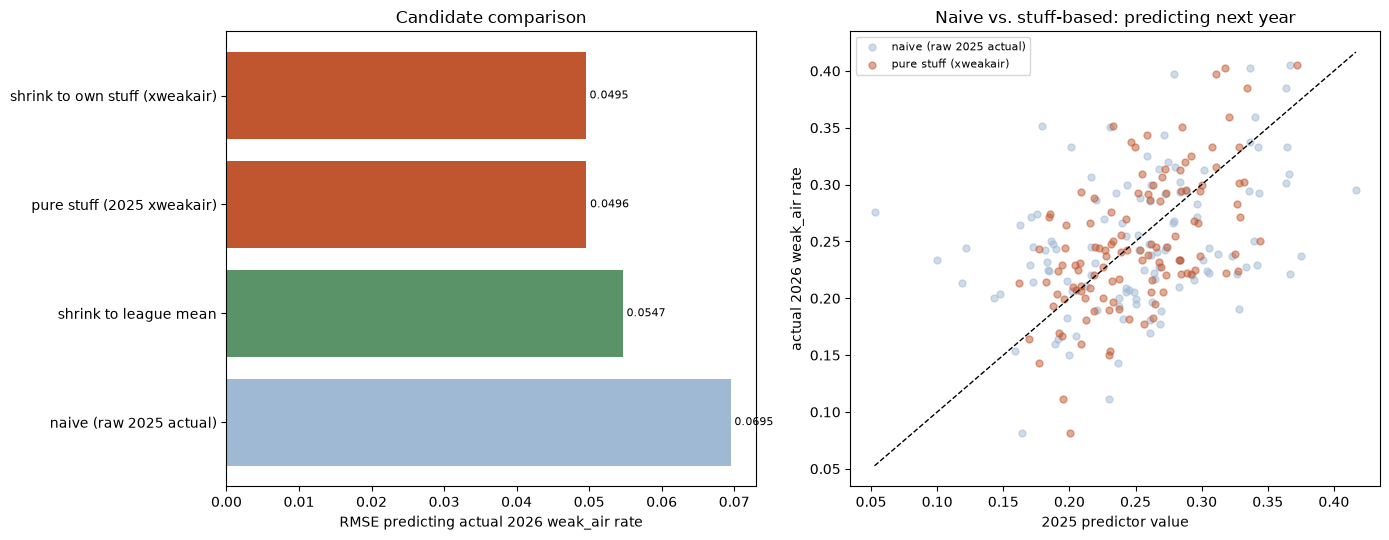

Best method: shrink to own stuff (xweakair)  (RMSE=0.0495, +28.7% vs. naive)


In [166]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

sorted_res = weakair_results.sort_values("RMSE", ascending=False)
colors = ["#9fb8d4" if "naive" in i else ("#5a9367" if "league mean" in i else "#c0562f") for i in sorted_res.index]
axes[0].barh(sorted_res.index, sorted_res["RMSE"], color=colors)
for i, v in enumerate(sorted_res["RMSE"]):
    axes[0].text(v + 0.0005, i, f"{v:.4f}", va="center", fontsize=8)
axes[0].set_xlabel("RMSE predicting actual 2026 weak_air rate")
axes[0].set_title("Candidate comparison")

axes[1].scatter(pairs["actual_rate"], pairs["actual_2026"], alpha=0.5, s=25, color="#9fb8d4", label="naive (raw 2025 actual)")
axes[1].scatter(pairs["xweakair"], pairs["actual_2026"], alpha=0.5, s=25, color="#c0562f", label="pure stuff (xweakair)")
lims = [pairs[["actual_rate","xweakair","actual_2026"]].min().min(), pairs[["actual_rate","xweakair","actual_2026"]].max().max()]
axes[1].plot(lims, lims, color="black", lw=1, ls="--")
axes[1].set_xlabel("2025 predictor value")
axes[1].set_ylabel("actual 2026 weak_air rate")
axes[1].set_title("Naive vs. stuff-based: predicting next year")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig("output/weak_air_pitcher_model_validation.png", dpi=150)
plt.show()

best = weakair_results["RMSE"].idxmin()
print(f"Best method: {best}  (RMSE={weakair_results.loc[best,'RMSE']:.4f}, {weakair_results.loc[best,'pct_improvement_vs_naive']:+.1f}% vs. naive)")


**Pure stuff (xWeakAir%) alone beats the pitcher's own raw observed rate by 28.7% RMSE and roughly doubles the year-to-year correlation (0.57 vs. 0.37).** Blending in a reliability-weighted sliver of their actual rate ("shrink to own stuff") does essentially nothing on top of that -- RMSE moves from 0.0496 to 0.0495, well within noise. Shrinking the observed rate to the plain league mean helps too (21.4%) but not as much as leaning on the pitcher's own repertoire-implied rate.

**The takeaway: for evaluating a pitcher's true weak-air-inducing ability, xWeakAir% *is* the better pitcher-level model -- not a refinement layered on top of it.** A single season's worth of BBE (even 100-150) is too noisy for a pitcher's own observed rate to add real information beyond what their pitch characteristics already imply. That's a meaningfully different conclusion than the batter wOBA-component shrinkage earlier in this project, where blending observed performance with a prior consistently beat either pure extreme -- here, the 'prior' (stuff) is just that much more informative relative to the noise in a pitcher's own weak-air outcome sample.

## Does the model need pitch-type labels at all?

Refit with pitch_type dropped entirely -- movement, velocity, and location only -- restricted to the strike-zone vicinity (`plate_x` in [-1.5, 1.5], `plate_z` in [0.5, 4.5], generous enough to keep 99.5% of in-play batted balls while trimming the handful of extreme-location outliers that aren't meaningfully "pitches" in the usual sense).

In [167]:
bbe_notype = bbe.dropna(subset=["ivb", "horz_break", "plate_x", "plate_z", "extension",
                                "rel_height", "rel_side", "effective_velo", "spin_rate",
                                "pitcher_throws", "year"]).copy()
bbe_notype = bbe_notype[(bbe_notype["pitcher_throws"] != "undefined")
                        & bbe_notype["plate_x"].between(-1.5, 1.5)
                        & bbe_notype["plate_z"].between(0.5, 4.5)].copy()
print(f"n = {len(bbe_notype):,}  ({len(bbe_notype)/len(bbe)*100:.1f}% of all non-Trustmark BBE)")

arm_sign2 = np.where(bbe_notype["pitcher_throws"] == "right", 1, -1)
bbe_notype["horz_break_as"] = bbe_notype["horz_break"] * arm_sign2
bbe_notype["rel_side_as"] = bbe_notype["rel_side"] * arm_sign2
bbe_notype["plate_x_as"] = bbe_notype["plate_x"] * arm_sign2

pred_cols_nt = ["effective_velo", "ivb", "horz_break_as", "spin_rate", "plate_x_as", "plate_z",
                "extension", "rel_height", "rel_side_as"]
Xnt = bbe_notype[pred_cols_nt].astype(float)
Xnt_z = (Xnt - Xnt.mean()) / Xnt.std()


n = 75,050  (98.8% of all non-Trustmark BBE)


In [168]:
vif_nt = pd.DataFrame({"feature": pred_cols_nt,
                       "VIF": [variance_inflation_factor(Xnt_z.values, i) for i in range(len(pred_cols_nt))]})
print(vif_nt.round(2))

Xnt_full = sm.add_constant(Xnt_z.astype(float))
y_nt = bbe_notype["weak_air"].astype(float)
logit_nt = sm.Logit(y_nt, Xnt_full).fit(disp=0)
out_nt = logit_nt.summary2().tables[1].round(4)
out_nt["odds_ratio_per_sd"] = np.exp(out_nt["Coef."]).round(3)
print(f"n={len(bbe_notype):,}, pseudo R2={logit_nt.prsquared:.4f}  (vs. {logit_model.prsquared:.4f} with pitch type)")
out_nt.sort_values("Coef.", ascending=False)


          feature   VIF
0  effective_velo  2.49
1             ivb  2.41
2   horz_break_as  2.47
3       spin_rate  1.49
4      plate_x_as  1.14
5         plate_z  1.11
6       extension  1.23
7      rel_height  1.34
8     rel_side_as  1.30
n=75,050, pseudo R2=0.0427  (vs. 0.0437 with pitch type)


,Coef.,Std.Err.,z,P>|z|,[0.025,0.975],odds_ratio_per_sd
ivb,0.5017,0.0138,36.3639,0.0000,0.4747,0.5288,1.652
plate_z,0.3279,0.0092,35.7007,0.0000,0.3099,0.3459,1.388
spin_rate,0.0575,0.0109,5.2625,0.0000,0.0361,0.0789,1.059
rel_side_as,0.0133,0.0098,1.3652,0.1722,-0.0058,0.0325,1.013
plate_x_as,0.0037,0.0091,0.4017,0.6879,-0.0142,0.0216,1.004
extension,-0.0035,0.0096,-0.3640,0.7159,-0.0223,0.0153,0.997
rel_height,-0.0751,0.0100,-7.5176,0.0000,-0.0947,-0.0555,0.928
horz_break_as,-0.2123,0.0136,-15.5729,0.0000,-0.2390,-0.1856,0.809
effective_velo,-0.3558,0.0136,-26.0991,0.0000,-0.3826,-0.3291,0.701
const,-1.1432,0.0088,-129.2293,0.0000,-1.1605,-1.1258,0.319


**Pseudo R2 barely moves** (0.0427 vs. 0.0437 with pitch type) and the coefficient ranking is unchanged -- IVB (OR=1.65/SD) and pitch height (OR=1.39/SD) are still the two clear drivers, velocity and horizontal break still lean negative, release height still mildly negative. Pitch type was adding almost nothing on top of the continuous shape variables -- which makes sense, since a pitch-type label is really just a coarse summary of exactly these numbers to begin with.

In [169]:
# Corroborate + get honest out-of-fold predictions for the pitcher-level check
Xnt_xgb = bbe_notype[pred_cols_nt].astype(float)
y_nt_int = bbe_notype["weak_air"].astype(int)

clf_nt = XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.05, subsample=0.8,
                        colsample_bytree=0.8, eval_metric="logloss", random_state=42)
oof_proba_nt = cross_val_predict(clf_nt, Xnt_xgb, y_nt_int, cv=kf, method="predict_proba")[:, 1]
auc_nt = roc_auc_score(y_nt_int, oof_proba_nt)
print(f"No-pitch-type OOF AUC: {auc_nt:.4f}  (vs. {auc:.4f} with pitch type)")

clf_nt.fit(Xnt_xgb, y_nt_int)
imp_nt = pd.Series(clf_nt.feature_importances_, index=pred_cols_nt).sort_values(ascending=False)
print(imp_nt.round(4))


No-pitch-type OOF AUC: 0.6515  (vs. 0.6519 with pitch type)


plate_z           0.3170
ivb               0.1865
effective_velo    0.1363
horz_break_as     0.1012
rel_height        0.0582
spin_rate         0.0537
rel_side_as       0.0511
plate_x_as        0.0502
extension         0.0458
dtype: float32


In [170]:
# Pitcher-level, same dual-year validation harness as before
bbe_notype["xweakair_nt"] = oof_proba_nt
py_nt = bbe_notype.groupby(["pitcher_id", "pitcher", "year"]).agg(
    n=("weak_air", "size"), actual_rate=("weak_air", "mean"), xweakair_nt=("xweakair_nt", "mean")
).reset_index()
py_nt_q = py_nt[py_nt["n"] >= MIN_N].copy()
print(f"pitcher-seasons >= {MIN_N}: {len(py_nt_q)}")
print(f"corr(actual_rate, xweakair_nt) at pitcher-season: {py_nt_q['actual_rate'].corr(py_nt_q['xweakair_nt']):.3f}")

p25_nt = py_nt_q[py_nt_q["year"] == 2025][["pitcher_id", "n", "actual_rate", "xweakair_nt"]]
p26_nt = py_nt_q[py_nt_q["year"] == 2026][["pitcher_id", "actual_rate"]].rename(columns={"actual_rate": "actual_2026"})
pairs_nt = p25_nt.merge(p26_nt, on="pitcher_id", how="inner")
print(f"dual-year n = {len(pairs_nt)}")

compare_rows = []
for label, col, frame in [
    ("with pitch type: xweakair", "xweakair", pairs),
    ("no pitch type: xweakair_nt", "xweakair_nt", pairs_nt),
]:
    rmse = np.sqrt(((frame[col] - frame["actual_2026"]) ** 2).mean())
    corr = frame[col].corr(frame["actual_2026"])
    compare_rows.append({"model": label, "RMSE": rmse, "corr": corr})
pd.DataFrame(compare_rows).round(4)


pitcher-seasons >= 20: 695
corr(actual_rate, xweakair_nt) at pitcher-season: 0.611
dual-year n = 117


,model,RMSE,corr
0,with pitch type: xweakair,0.0496,0.5735
1,no pitch type: xweakair_nt,0.0489,0.5871


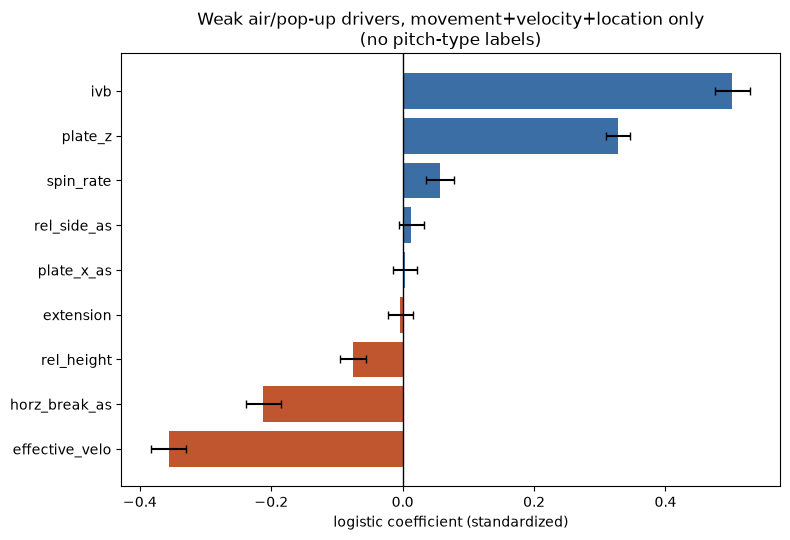

In [171]:
fig, ax = plt.subplots(figsize=(8, 5.5))
coef_plot_nt = out_nt.drop(index="const").sort_values("Coef.")
colors_nt = ["#c0562f" if v < 0 else "#3b6ea5" for v in coef_plot_nt["Coef."]]
ax.barh(coef_plot_nt.index, coef_plot_nt["Coef."], color=colors_nt,
        xerr=1.96 * coef_plot_nt["Std.Err."], capsize=3)
ax.axvline(0, color="black", lw=1)
ax.set_xlabel("logistic coefficient (standardized)")
ax.set_title("Weak air/pop-up drivers, movement+velocity+location only" + chr(10) + "(no pitch-type labels)")
plt.tight_layout()
plt.savefig("output/weak_air_no_pitchtype_coefficients.png", dpi=150)
plt.show()


**Removing pitch-type labels doesn't cost anything -- if anything, the pitcher-level validation comes out slightly better** (RMSE ~0.049 either way, correlation with actual 2026 rate 0.587 without labels vs. 0.574 with them -- within noise of each other, not a real improvement, but clearly not a loss).

That's a meaningful practical simplification: **the physical shape of the pitch is fully sufficient on its own.** You don't need a (potentially inconsistent, source-dependent) pitch-type classification to identify the profile that induces weak air contact -- you need a pitch that (1) rides (high IVB), (2) is located up (`plate_z`), (3) isn't just thrown as hard as possible without those other two, and ideally (4) comes from a lower release slot. Whether that pitch gets *labeled* four-seam, cutter, or something in between doesn't change what it does to the batter.

## Accounting for regions of velocity and break with XGBoost

The logistic model above forces velocity and movement into single additive effects -- one slope for velocity, one for IVB, one for horizontal break, no interaction between them. XGBoost (`clf_nt`, already fit on the no-pitch-type feature set) doesn't have that constraint, so a 2-way partial dependence surface can show whether the real relationship is a genuine region/interaction rather than two independent slopes.

In [172]:
from sklearn.inspection import partial_dependence

i_velo = pred_cols_nt.index("effective_velo")
i_ivb = pred_cols_nt.index("ivb")
i_hb = pred_cols_nt.index("horz_break_as")

pd_velo_ivb = partial_dependence(clf_nt, Xnt_xgb, features=[(i_velo, i_ivb)], kind="average", grid_resolution=20)
pd_velo_hb = partial_dependence(clf_nt, Xnt_xgb, features=[(i_velo, i_hb)], kind="average", grid_resolution=20)
pd_ivb_hb = partial_dependence(clf_nt, Xnt_xgb, features=[(i_ivb, i_hb)], kind="average", grid_resolution=20)

print(f"velo x ivb predicted-prob range:      {pd_velo_ivb['average'][0].min():.3f} - {pd_velo_ivb['average'][0].max():.3f}")
print(f"velo x horz_break predicted-prob range: {pd_velo_hb['average'][0].min():.3f} - {pd_velo_hb['average'][0].max():.3f}")
print(f"ivb x horz_break predicted-prob range:  {pd_ivb_hb['average'][0].min():.3f} - {pd_ivb_hb['average'][0].max():.3f}")


velo x ivb predicted-prob range:      0.088 - 0.476
velo x horz_break predicted-prob range: 0.158 - 0.422
ivb x horz_break predicted-prob range:  0.102 - 0.426


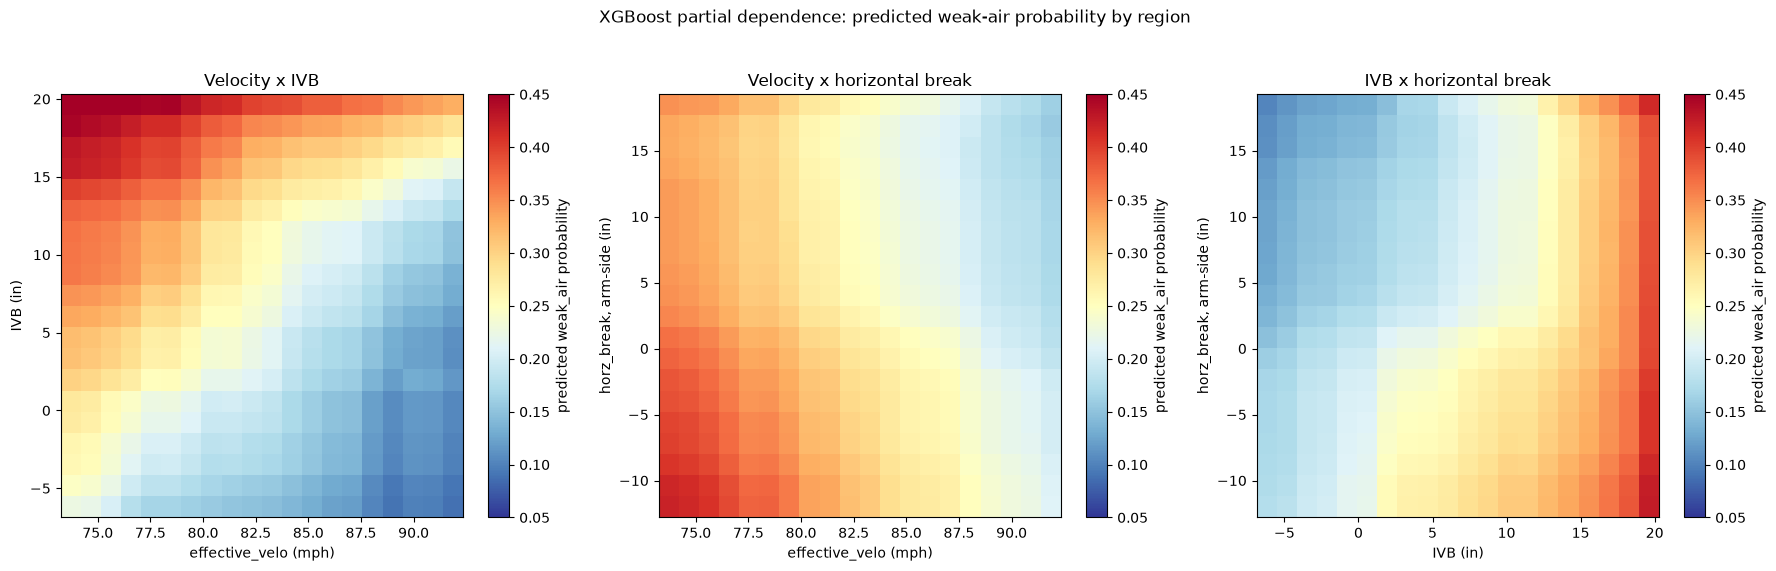

In [173]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

panels = [
    (pd_velo_ivb, "effective_velo (mph)", "IVB (in)", axes[0], "Velocity x IVB"),
    (pd_velo_hb, "effective_velo (mph)", "horz_break, arm-side (in)", axes[1], "Velocity x horizontal break"),
    (pd_ivb_hb, "IVB (in)", "horz_break, arm-side (in)", axes[2], "IVB x horizontal break"),
]
for pdres, xlabel, ylabel, ax, title in panels:
    xs, ys = pdres["grid_values"]
    zs = pdres["average"][0]
    im = ax.pcolormesh(xs, ys, zs.T, cmap="RdYlBu_r", shading="auto", vmin=0.05, vmax=0.45)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    plt.colorbar(im, ax=ax, label="predicted weak_air probability")
plt.suptitle("XGBoost partial dependence: predicted weak-air probability by region", y=1.03)
plt.tight_layout()
plt.savefig("output/weak_air_xgb_partial_dependence.png", dpi=150, bbox_inches="tight")
plt.show()


In [174]:
# Ground the model surface in the actual data -- empirical weak_air rate
# binned the same way, so the PDP isn't read as a pure model artifact
bbe_notype["velo_bin"] = pd.cut(bbe_notype["effective_velo"], bins=8)
bbe_notype["ivb_bin"] = pd.cut(bbe_notype["ivb"], bins=8)
emp_grid = bbe_notype.groupby(["velo_bin", "ivb_bin"], observed=True)["weak_air"].agg(["size", "mean"])
emp_grid_trusted = emp_grid[emp_grid["size"] >= 50]

print("--- highest empirical weak_air-rate cells (n>=50) ---")
print(emp_grid_trusted.sort_values("mean", ascending=False).head(8).round(3))
print()
print("--- lowest empirical weak_air-rate cells (n>=50) ---")
print(emp_grid_trusted.sort_values("mean").head(8).round(3))


--- highest empirical weak_air-rate cells (n>=50) ---
                                   size   mean
velo_bin         ivb_bin                      
(63.453, 70.485] (13.958, 20.469]    64  0.453
(84.551, 91.584] (20.469, 26.981]  1750  0.423
(77.518, 84.551] (20.469, 26.981]   222  0.414
(91.584, 98.617] (20.469, 26.981]   184  0.380
(63.453, 70.485] (0.936, 7.447]      96  0.375
(70.485, 77.518] (13.958, 20.469]   263  0.369
(77.518, 84.551] (13.958, 20.469]  2489  0.342
(63.453, 70.485] (7.447, 13.958]     59  0.339

--- lowest empirical weak_air-rate cells (n>=50) ---
                                     size   mean
velo_bin         ivb_bin                        
(77.518, 84.551] (-18.598, -12.087]   121  0.074
(84.551, 91.584] (-5.575, 0.936]      425  0.087
(91.584, 98.617] (0.936, 7.447]       151  0.093
(70.485, 77.518] (-25.161, -18.598]    57  0.105
(91.584, 98.617] (7.447, 13.958]     1551  0.139
(84.551, 91.584] (0.936, 7.447]      3994  0.144
(77.518, 84.551] (-12.087, -5.

**A real region, not just two independent slopes.** The velocity x IVB panel peaks in a specific corner -- moderate-to-upper velocity (roughly mid-80s mph) combined with high IVB (20+ in), predicted probability up near 0.49. The empirical grid backs this up directly: (84.6-91.6 mph, 20.5-27.0 IVB) hits **42.3% actual weak-air rate on n=1,750** -- a large, trustworthy cell, not a small-sample artifact. That's nowhere close to the hardest-throwing bin available (91.6-98.6 mph tops out lower at this same IVB level, 38.0%), which is exactly the interaction the additive logistic model couldn't represent -- 'as hard as possible' isn't the ceiling; 'hard enough to be dangerous, with IVB doing the rest of the work' is.

**The dead zone is just as clear and just as interaction-shaped.** Any velocity combined with negative-to-flat IVB (sinking/flat movement, the classic two-seam/sinker shape) collapses to the coldest part of the surface regardless of how hard it's thrown -- the empirical worst cell (77.5-84.5 mph, -18.6 to -12.1 IVB) sits at **7.4%**, and 84.5-91.6 mph paired with near-zero IVB is barely better at 8.7% (n=425). Velocity alone never rescues a sinking shape from inducing mostly grounders/hard-hit air instead of weak air.

**Horizontal break mostly just subtracts, without much interaction structure of its own** -- both other panels show it fading the effect fairly uniformly rather than creating its own hot corner, consistent with it being a much weaker, non-interacting driver in the logistic model too.

## rel_speed instead of effective_velo

`effective_velo` is itself derived from `rel_speed` adjusted by `extension` (more extension = ball reaches the plate sooner = plays up as "effectively" faster). That means `extension` was already partly baked into the velocity term above, which could be masking or double-counting its own effect. Swapping in raw `rel_speed` (correlation with effective_velo = 0.985, so barely any information lost) cleanly separates the two.

In [175]:
bbe_rs = bbe.dropna(subset=["ivb", "horz_break", "plate_x", "plate_z", "extension",
                            "rel_height", "rel_side", "rel_speed", "spin_rate",
                            "pitcher_throws", "year"]).copy()
bbe_rs = bbe_rs[(bbe_rs["pitcher_throws"] != "undefined")
                & bbe_rs["plate_x"].between(-1.5, 1.5) & bbe_rs["plate_z"].between(0.5, 4.5)].copy()
print(f"n = {len(bbe_rs):,}")
print(f"corr(rel_speed, effective_velo) = {bbe['rel_speed'].corr(bbe['effective_velo']):.3f}")
print(f"corr(rel_speed, extension)      = {bbe['rel_speed'].corr(bbe['extension']):.3f}  (vs. "
      f"corr(effective_velo, extension) = {bbe['effective_velo'].corr(bbe['extension']):.3f})")

arm_sign3 = np.where(bbe_rs["pitcher_throws"] == "right", 1, -1)
bbe_rs["horz_break_as"] = bbe_rs["horz_break"] * arm_sign3
bbe_rs["rel_side_as"] = bbe_rs["rel_side"] * arm_sign3
bbe_rs["plate_x_as"] = bbe_rs["plate_x"] * arm_sign3

pred_cols_rs = ["rel_speed", "ivb", "horz_break_as", "spin_rate", "plate_x_as", "plate_z",
                "extension", "rel_height", "rel_side_as"]
Xrs = bbe_rs[pred_cols_rs].astype(float)
Xrs_z = (Xrs - Xrs.mean()) / Xrs.std()

vif_rs = pd.DataFrame({"feature": pred_cols_rs,
                       "VIF": [variance_inflation_factor(Xrs_z.values, i) for i in range(len(pred_cols_rs))]})
print(vif_rs.round(2))


n = 75,050


corr(rel_speed, effective_velo) = 0.985
corr(rel_speed, extension)      = 0.224  (vs. corr(effective_velo, extension) = 0.375)


         feature   VIF
0      rel_speed  2.31
1            ivb  2.43
2  horz_break_as  2.50
3      spin_rate  1.50
4     plate_x_as  1.14
5        plate_z  1.11
6      extension  1.12
7     rel_height  1.34
8    rel_side_as  1.29


In [176]:
Xrs_full = sm.add_constant(Xrs_z.astype(float))
y_rs = bbe_rs["weak_air"].astype(float)
logit_rs = sm.Logit(y_rs, Xrs_full).fit(disp=0)
out_rs = logit_rs.summary2().tables[1].round(4)
out_rs["odds_ratio_per_sd"] = np.exp(out_rs["Coef."]).round(3)
print(f"n={len(bbe_rs):,}, pseudo R2={logit_rs.prsquared:.4f}  (vs. {logit_nt.prsquared:.4f} with effective_velo)")
out_rs.sort_values("Coef.", ascending=False)


n=75,050, pseudo R2=0.0422  (vs. 0.0427 with effective_velo)

,Coef.,Std.Err.,z,P>|z|,[0.025,0.975],odds_ratio_per_sd
ivb,0.5019,0.0139,36.1669,0.0000,0.4747,0.5291,1.652
plate_z,0.3277,0.0092,35.6851,0.0000,0.3097,0.3457,1.388
spin_rate,0.0549,0.0109,5.0138,0.0000,0.0334,0.0763,1.056
rel_side_as,0.0160,0.0098,1.6386,0.1013,-0.0031,0.0351,1.016
plate_x_as,0.0029,0.0091,0.3145,0.7531,-0.0150,0.0208,1.003
extension,-0.0607,0.0091,-6.6756,0.0000,-0.0786,-0.0429,0.941
rel_height,-0.0760,0.0100,-7.6016,0.0000,-0.0956,-0.0564,0.927
horz_break_as,-0.2121,0.0137,-15.4777,0.0000,-0.2390,-0.1853,0.809
rel_speed,-0.3329,0.0131,-25.3323,0.0000,-0.3587,-0.3072,0.717
const,-1.1426,0.0088,-129.2209,0.0000,-1.1600,-1.1253,0.319


**Extension goes from non-significant to a real, independent negative effect.** With `effective_velo` in the model, extension's own coefficient was noise (p=0.71). With raw `rel_speed` instead -- and extension's correlation with the velocity term dropping from 0.375 to 0.224 -- extension comes out clearly significant (OR=0.94/SD, p<0.0001): more extension at a *given* raw radar velocity is associated with **less** weak-air contact, all else equal. That's the same direction as the velocity effect itself (more extension effectively plays up as harder, and harder plays down for this outcome) -- `effective_velo` had been quietly absorbing this instead of showing it as its own lever. IVB (1.65x/SD) and pitch height (1.39x/SD) are essentially unchanged, as expected since neither is mechanically tied to how velocity is defined.

In [177]:
# Corroborate + partial dependence, same treatment as the effective_velo version
Xrs_xgb = bbe_rs[pred_cols_rs].astype(float)
y_rs_int = bbe_rs["weak_air"].astype(int)

clf_rs = XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.05, subsample=0.8,
                        colsample_bytree=0.8, eval_metric="logloss", random_state=42)
oof_proba_rs = cross_val_predict(clf_rs, Xrs_xgb, y_rs_int, cv=kf, method="predict_proba")[:, 1]
print(f"rel_speed OOF AUC: {roc_auc_score(y_rs_int, oof_proba_rs):.4f}  (vs. {auc_nt:.4f} with effective_velo)")

clf_rs.fit(Xrs_xgb, y_rs_int)
imp_rs = pd.Series(clf_rs.feature_importances_, index=pred_cols_rs).sort_values(ascending=False)
print(imp_rs.round(4))


rel_speed OOF AUC: 0.6520  (vs. 0.6515 with effective_velo)


plate_z          0.3152
ivb              0.1844
rel_speed        0.1352
horz_break_as    0.0998
rel_height       0.0597
spin_rate        0.0536
plate_x_as       0.0514
rel_side_as      0.0509
extension        0.0497
dtype: float32


--- top empirical cells (rel_speed x IVB, n>=50) ---
                                   size   mean
rs_bin           ivb_bin                      
(85.479, 92.216] (20.469, 26.981]  1742  0.432
(65.267, 72.005] (13.958, 20.469]    58  0.397
(72.005, 78.742] (13.958, 20.469]   299  0.395
(65.267, 72.005] (7.447, 13.958]     62  0.387
(92.216, 98.953] (20.469, 26.981]   275  0.371


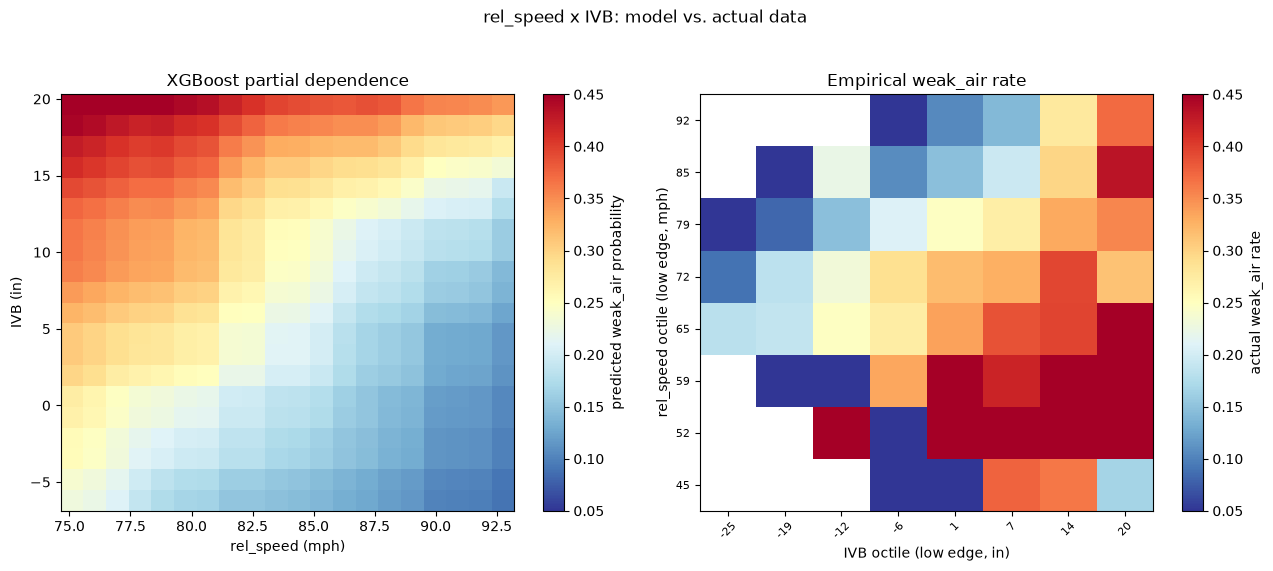

In [178]:
i_rs = pred_cols_rs.index("rel_speed")
i_ivb_rs = pred_cols_rs.index("ivb")
pd_rs_ivb = partial_dependence(clf_rs, Xrs_xgb, features=[(i_rs, i_ivb_rs)], kind="average", grid_resolution=20)

bbe_rs["rs_bin"] = pd.cut(bbe_rs["rel_speed"], bins=8)
bbe_rs["ivb_bin"] = pd.cut(bbe_rs["ivb"], bins=8)
emp_rs = bbe_rs.groupby(["rs_bin", "ivb_bin"], observed=True)["weak_air"].agg(["size", "mean"])
emp_rs_trusted = emp_rs[emp_rs["size"] >= 50]
print("--- top empirical cells (rel_speed x IVB, n>=50) ---")
print(emp_rs_trusted.sort_values("mean", ascending=False).head(5).round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
xs, ys = pd_rs_ivb["grid_values"]
zs = pd_rs_ivb["average"][0]
im = axes[0].pcolormesh(xs, ys, zs.T, cmap="RdYlBu_r", shading="auto", vmin=0.05, vmax=0.45)
axes[0].set_xlabel("rel_speed (mph)")
axes[0].set_ylabel("IVB (in)")
axes[0].set_title("XGBoost partial dependence")
plt.colorbar(im, ax=axes[0], label="predicted weak_air probability")

pivot_emp = emp_rs["mean"].unstack("ivb_bin")
im2 = axes[1].imshow(pivot_emp.values, cmap="RdYlBu_r", vmin=0.05, vmax=0.45, aspect="auto", origin="lower")
axes[1].set_xticks(range(len(pivot_emp.columns)))
axes[1].set_xticklabels([f"{i.left:.0f}" for i in pivot_emp.columns], rotation=45, fontsize=8)
axes[1].set_yticks(range(len(pivot_emp.index)))
axes[1].set_yticklabels([f"{i.left:.0f}" for i in pivot_emp.index], fontsize=8)
axes[1].set_xlabel("IVB octile (low edge, in)")
axes[1].set_ylabel("rel_speed octile (low edge, mph)")
axes[1].set_title("Empirical weak_air rate")
plt.colorbar(im2, ax=axes[1], label="actual weak_air rate")
plt.suptitle("rel_speed x IVB: model vs. actual data", y=1.03)
plt.tight_layout()
plt.savefig("output/weak_air_relspeed_partial_dependence.png", dpi=150, bbox_inches="tight")
plt.show()


In [179]:
# Same dual-year validation harness, does xWeakAir% built on rel_speed predict as well?
bbe_rs["xweakair_rs"] = oof_proba_rs
py_rs = bbe_rs.groupby(["pitcher_id", "pitcher", "year"]).agg(
    n=("weak_air", "size"), actual_rate=("weak_air", "mean"), xweakair_rs=("xweakair_rs", "mean")
).reset_index()
py_rs_q = py_rs[py_rs["n"] >= MIN_N].copy()

p25_rs = py_rs_q[py_rs_q["year"] == 2025][["pitcher_id", "actual_rate", "xweakair_rs"]]
p26_rs = py_rs_q[py_rs_q["year"] == 2026][["pitcher_id", "actual_rate"]].rename(columns={"actual_rate": "actual_2026"})
pairs_rs = p25_rs.merge(p26_rs, on="pitcher_id", how="inner")

rmse_rs = np.sqrt(((pairs_rs["xweakair_rs"] - pairs_rs["actual_2026"]) ** 2).mean())
corr_rs = pairs_rs["xweakair_rs"].corr(pairs_rs["actual_2026"])
print(f"rel_speed xweakair: RMSE={rmse_rs:.4f}, corr={corr_rs:.3f}  (n={len(pairs_rs)})")
print(f"effective_velo xweakair_nt (for comparison): see 'no pitch type' section above")


rel_speed xweakair: RMSE=0.0489, corr=0.587  (n=117)
effective_velo xweakair_nt (for comparison): see 'no pitch type' section above


**Predictive power is unchanged, as expected given the 0.985 correlation between the two velocity measures** -- same AUC (0.652), same feature ranking (plate_z, ivb, velocity term), same dual-year RMSE/correlation. The empirical grid replicates the exact same shape too: the hottest cell is again mid-to-upper-80s velocity with high IVB (85.5-92.2 mph rel_speed, 20.5-27.0 IVB -> 43.2% actual rate, n=1,742), and the hardest-throwing bin at the same IVB level again does *worse* (37.1%) -- confirming the "sweet spot, not just max effort" finding wasn't an artifact of how effective_velo folds in extension.

**What changes is interpretability, not accuracy.** Using `rel_speed` cleanly reveals extension as its own real, negative, independent lever -- useful for scouting because it separates two different things a pitcher can work on: throwing harder (rel_speed) vs. releasing the ball closer to the plate (extension) both push in the same direction for inducing *harder* contact (bad for this specific goal), while a pitcher content to sit in the mid-80s to low-90s without over-extending -- provided the IVB and elevated location are there -- is closer to the actual profile that works.